# Home Improvement Credit Scorecard

# Step 1 — Data Exploration

Retail lending is a high-volume, small-ticket business, so credit decisions are automated with scorecards that estimate each applicant's probability of default at the point of application. Profitability depends on the interest margin earned on good loans exceeding the losses on loans that go bad, so the rate charged must reflect the risk of the portfolio (Module 7.1).

Home Improvement loans are instalment loans that homeowners use to renovate, repair or upgrade the property they live in. The loan is paid out once and repaid in fixed instalments. This notebook builds an application scorecard for the product from the assignment's application and credit bureau data.

**Proxy population.** The data has **no loan-purpose field**, so renovation loans cannot be selected directly. The analysis uses a profile-based proxy: applicants who match the profile of a home-improvement borrower. Results describe that proxy population, not confirmed renovation borrowers. `FLAG_OWN_REALTY` only records that the client owns a house or flat. It does not show:
- what the loan is for;
- that the client lives in the property they own;
- that the property secures the loan.

The loan is therefore treated as unsecured.

**Target variable.** `TARGET = 1` marks a client with payment difficulties: a payment more than X days late on at least one of the first Y instalments. `TARGET = 0` covers all other cases. The data dictionary does not specify X or Y, so the bad outcome is early payment difficulty, not a confirmed default or a realised loss. Throughout, `TARGET = 1` is the event (bad) and `TARGET = 0` the non-event (good).

**Units.** The dictionary does not state the currency of the amount fields, or whether income and annuity are monthly or annual. Amounts are reported as recorded, without a currency or period label.

**Scope of this step.** Exploration covers every application. No segment filter is applied here; the representative population is selected in 2.1. All charts and rates in this step are descriptive whole-population results and are not used to choose predictors, bins or cutoffs.

Import the libraries and fix the random seed so that every split and model is reproducible.

In [1]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# fix the random seed for reproducible splits and models
RANDOM_STATE = 453
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# display settings
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.4f}'.format)
sns.set_theme(style='whitegrid')
warnings.filterwarnings('ignore', category=FutureWarning)

print('pandas', pd.__version__, '| numpy', np.__version__, '| scikit-learn', sklearn.__version__, '| seaborn', sns.__version__)

pandas 2.2.3 | numpy 2.2.2 | scikit-learn 1.9.1 | seaborn 0.13.2


Locate the data files. The data folder defaults to the folder next to this notebook and can be changed with the `IS453_DATA_ROOT` environment variable.

In [2]:
# notebook folder = current working directory when Jupyter opens this notebook
PROJECT_DIR = Path.cwd()

# data root: environment variable if set, otherwise the folder next to the notebook
DATA_ROOT = Path(os.environ.get('IS453_DATA_ROOT', PROJECT_DIR / 'IS453 Group Assignment - Data'))

APP_FILE = DATA_ROOT / 'IS453 Group Assignment - Application Data.csv'
BUREAU_FILE = DATA_ROOT / 'IS453 Group Assignment - Bureau Data.csv'
DICT_FILE = DATA_ROOT / 'IS453 Group Assignment - Data Dict.xlsx'

# borrower-level outputs stay local
OUTPUT_DIR = PROJECT_DIR / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

# show the data root relative to the notebook so no personal path is saved in the outputs
try:
    shown_root = DATA_ROOT.resolve().relative_to(PROJECT_DIR.resolve())
except ValueError:
    shown_root = '(set by IS453_DATA_ROOT)'
print('Data root:', shown_root)
for f in [APP_FILE, BUREAU_FILE, DICT_FILE]:
    status = f'found ({f.stat().st_size / 1e6:,.2f} MB)' if f.exists() else 'missing'
    print(f'  {f.name}: {status}')

Data root: IS453 Group Assignment - Data
  IS453 Group Assignment - Application Data.csv: found (143.12 MB)
  IS453 Group Assignment - Bureau Data.csv: found (170.02 MB)
  IS453 Group Assignment - Data Dict.xlsx: found (0.02 MB)


Define the column names and settings used in later steps. The partition sizes follow the split-sample method: about one-third of the data is held out as a stratified test set. The IV bands and the minimum bin share are the screening and coarse-classing rules from class. `CODE_GENDER` is excluded from modelling on fair-lending grounds.

In [3]:
# identifiers and target
ID_COL = 'SK_ID_CURR'      # one row per loan application; key to the bureau file
TARGET = 'TARGET'          # 1 = payment difficulties (event / bad), 0 = all other cases (non-event / good)

# partitions: held-out test set, then internal validation within the development data
OUTER_TEST_SIZE = 1 / 3
VALID_SIZE = 0.25

# characteristic screening bands for Information Value
IV_BANDS = [(0.02, 'Not useful'), (0.10, 'Weak'), (0.30, 'Medium'), (0.50, 'Strong'), (np.inf, 'Potentially over-predictive')]
TOP_N_IV = 15

# coarse classing: minimum share of observations per bin
MIN_BIN_SHARE = 0.05

# variables excluded on fair-lending grounds
FAIRNESS_EXCLUDE = ['CODE_GENDER']

Set consistent chart colours: blue for goods (`TARGET = 0`) and orange for bads (`TARGET = 1`).

In [4]:
from matplotlib.colors import LinearSegmentedColormap

GOOD_COLOUR, BAD_COLOUR = '#2a78d6', '#eb6834'
TARGET_PALETTE = {0: GOOD_COLOUR, 1: BAD_COLOUR}
BAR_COLOUR = '#2a78d6'
# diverging map for correlations: red (negative) - grey (zero) - blue (positive)
CORR_CMAP = LinearSegmentedColormap.from_list('corr', ['#e34948', '#f0efec', '#2a78d6'])

plt.rcParams.update({'axes.edgecolor': '#c3c2b7', 'grid.color': '#e1e0d9', 'axes.titleweight': 'bold',
                     'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e'})

## 1.1 Identify Variable Types

Load the application file, the bureau file and both sheets of the data dictionary. The raw files are read only and never modified.

In [5]:
app_data = pd.read_csv(APP_FILE)
bureau_data = pd.read_csv(BUREAU_FILE)
data_dict = pd.read_excel(DICT_FILE, sheet_name=None)

print(f'Application data: {app_data.shape[0]:,} rows x {app_data.shape[1]} columns')
print(f'Bureau data:      {bureau_data.shape[0]:,} rows x {bureau_data.shape[1]} columns')
print('Dictionary sheets:', {name: len(sheet) for name, sheet in data_dict.items()})

Application data: 307,511 rows x 120 columns
Bureau data:      1,716,428 rows x 17 columns
Dictionary sheets: {'Application Data': 120, 'Bureau Data': 17}


**How the two files link.** Each application should appear once in the application file and zero or more times in the bureau file, joined on `SK_ID_CURR`. Check the keys and compare the dictionary with the actual column names.

In [6]:
app_ids = app_data[ID_COL]
bureau_ids = bureau_data[ID_COL]

print('SK_ID_CURR unique in application data:', app_ids.is_unique)
print('SK_ID_BUREAU unique in bureau data:   ', bureau_data['SK_ID_BUREAU'].is_unique)
print(f'Distinct SK_ID_CURR in bureau data:   {bureau_ids.nunique():,}')

# dictionary names versus actual columns
for sheet, df in [('Application Data', app_data), ('Bureau Data', bureau_data)]:
    dict_cols = set(data_dict[sheet]['Row'])
    print(f'{sheet}: in dictionary only {sorted(dict_cols - set(df.columns))}, in data only {sorted(set(df.columns) - dict_cols)}')

SK_ID_CURR unique in application data: True
SK_ID_BUREAU unique in bureau data:    True
Distinct SK_ID_CURR in bureau data:   305,811
Application Data: in dictionary only [], in data only []
Bureau Data: in dictionary only ['SK_BUREAU_ID'], in data only ['SK_ID_BUREAU']


In [7]:
# number of bureau records per application (applications without a record count as 0)
bureau_per_app = bureau_ids[bureau_ids.isin(app_ids)].value_counts().reindex(app_ids, fill_value=0)

link_table = pd.cut(bureau_per_app, bins=[-1, 0, 1, 5, 10, 20, bureau_per_app.max()],
                    labels=['0', '1', '2-5', '6-10', '11-20', '21+']).value_counts().sort_index().rename_axis('Bureau records').to_frame('Applications')
link_table['% of applications'] = link_table['Applications'] / len(app_data) * 100
print('Table 1.1a - Bureau records per application')
display(link_table.round(1))

orphan = ~bureau_ids.isin(app_ids)
print(f'Bureau rows with no matching application: {orphan.sum():,} ({orphan.mean():.1%}) across {bureau_ids[orphan].nunique():,} IDs')

Table 1.1a - Bureau records per application


,Applications,% of applications
Bureau records,,
0,44020,14.3000
1,36072,11.7000
2-5,122518,39.8000
6-10,72624,23.6000
11-20,29808,9.7000
21+,2469,0.8000


Bureau rows with no matching application: 251,103 (14.6%) across 42,320 IDs


The application file has one row per `SK_ID_CURR`, and each application has between zero and many bureau records. The relationship is one-to-many from application to bureau. The bureau file therefore has to be aggregated to one row per applicant before it can be joined (Module 9.2); a direct join would duplicate applicants. The bureau file also contains records for IDs that are not in the application file, and these can never be linked.

The dictionary calls the bureau record key `SK_BUREAU_ID`, but the CSV column is `SK_ID_BUREAU`. The CSV name is used from here on.

**Variable types.** Data type alone is misleading. Many 0/1 flags and counts are stored as integers, and `AMT_REQ_CREDIT_BUREAU_*` are enquiry counts despite the `AMT_` prefix. The fields are therefore grouped by their meaning in the dictionary.

In [8]:
building_cols = [c for c in app_data.columns if c.endswith(('_AVG', '_MODE', '_MEDI'))]
building_cat = [c for c in building_cols if app_data[c].dtype == 'O']

var_types = {
    'Identifier': [ID_COL],
    'Target': [TARGET],
    'Continuous amount': ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE'],
    'Day offset (relative to application)': [c for c in app_data.columns if c.startswith('DAYS_')],
    'Count': ['CNT_CHILDREN', 'CNT_FAM_MEMBERS'] + [c for c in app_data.columns if c.endswith('_SOCIAL_CIRCLE') or c.startswith('AMT_REQ_')],
    'Binary flag': [c for c in app_data.columns if c.startswith('FLAG_') or '_NOT_' in c],
    'Ordinal rating / ordered category': ['REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'NAME_EDUCATION_TYPE'],
    'Nominal category': [c for c in app_data.select_dtypes('object').columns
                         if not c.startswith('FLAG_') and c != 'NAME_EDUCATION_TYPE' and c not in building_cat] + building_cat,
    'Continuous (normalised score or measure)': ['EXT_SOURCE_1', 'REGION_POPULATION_RELATIVE', 'OWN_CAR_AGE']
                                                + [c for c in building_cols if c not in building_cat],
    'Time of application': ['HOUR_APPR_PROCESS_START'],
}

assigned = [c for cols in var_types.values() for c in cols]
assert len(assigned) == len(set(assigned)) == app_data.shape[1], 'every column should have exactly one type'

type_table = pd.DataFrame({'Fields': {k: len(v) for k, v in var_types.items()},
                           'Examples': {k: ', '.join(v[:4]) + (' ...' if len(v) > 4 else '') for k, v in var_types.items()}})
print('Table 1.1b - Application data fields by variable type')
display(type_table)

Table 1.1b - Application data fields by variable type


,Fields,Examples
Identifier,1,SK_ID_CURR
Target,1,TARGET
Continuous amount,4,"AMT_INCOME_TOTAL, AMT_CREDIT, AMT_ANNUITY, AMT..."
Day offset (relative to application),5,"DAYS_BIRTH, DAYS_EMPLOYED, DAYS_REGISTRATION, ..."
Count,12,"CNT_CHILDREN, CNT_FAM_MEMBERS, OBS_30_CNT_SOCI..."
Binary flag,34,"FLAG_OWN_CAR, FLAG_OWN_REALTY, FLAG_MOBIL, FLA..."
Ordinal rating / ordered category,3,"REGION_RATING_CLIENT, REGION_RATING_CLIENT_W_C..."
Nominal category,13,"NAME_CONTRACT_TYPE, CODE_GENDER, NAME_TYPE_SUI..."
Continuous (normalised score or measure),46,"EXT_SOURCE_1, REGION_POPULATION_RELATIVE, OWN_..."
Time of application,1,HOUR_APPR_PROCESS_START


In [9]:
bureau_types = pd.DataFrame({
    'Fields': ['SK_ID_CURR, SK_ID_BUREAU', 'CREDIT_ACTIVE, CREDIT_CURRENCY, CREDIT_TYPE',
               'DAYS_CREDIT, DAYS_CREDIT_ENDDATE, DAYS_ENDDATE_FACT, DAYS_CREDIT_UPDATE', 'CREDIT_DAY_OVERDUE',
               'AMT_CREDIT_SUM, AMT_CREDIT_SUM_DEBT, AMT_CREDIT_SUM_LIMIT, AMT_CREDIT_SUM_OVERDUE, AMT_CREDIT_MAX_OVERDUE, AMT_ANNUITY',
               'CNT_CREDIT_PROLONG']},
    index=['Identifier', 'Nominal category', 'Day offset', 'Days past due', 'Continuous amount', 'Count'])
print('Table 1.1c - Bureau data fields by variable type')
display(bureau_types)

Table 1.1c - Bureau data fields by variable type


,Fields
Identifier,"SK_ID_CURR, SK_ID_BUREAU"
Nominal category,"CREDIT_ACTIVE, CREDIT_CURRENCY, CREDIT_TYPE"
Day offset,"DAYS_CREDIT, DAYS_CREDIT_ENDDATE, DAYS_ENDDATE..."
Days past due,CREDIT_DAY_OVERDUE
Continuous amount,"AMT_CREDIT_SUM, AMT_CREDIT_SUM_DEBT, AMT_CREDI..."
Count,CNT_CREDIT_PROLONG


The application file holds 4 continuous amounts and 5 day offsets. It also holds 34 binary flags (20 document flags, 6 address-mismatch flags and 8 contact or ownership flags), which are mostly recorded as numbers but are categorical in meaning. The 47 building fields (`_AVG`, `_MODE`, `_MEDI`) describe the client's building rather than the client, and four of them are categorical. `EXT_SOURCE_1` is the only external score in this extract. Day offsets are negative counts of days before the application. Converting them to years gives readable ages and durations.

## 1.2 Univariate Analysis

Summary statistics show the centre and spread of each key numeric field. The median and upper percentiles matter more than the mean for skewed amounts. Age in years, `age_years = -DAYS_BIRTH / 365.25`, is derived for description only; the raw column is unchanged.

In [10]:
age_years = (-app_data['DAYS_BIRTH'] / 365.25).rename('age_years')

key_numeric = ['AMT_CREDIT', 'AMT_INCOME_TOTAL', 'AMT_ANNUITY', 'EXT_SOURCE_1', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS']
summary = app_data[key_numeric].assign(age_years=age_years).describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).T
summary['missing'] = len(app_data) - summary['count']
print('Table 1.2a - Summary statistics for key numeric fields (all applications)')
display(summary.drop(columns='count').style.format('{:,.2f}'))

Table 1.2a - Summary statistics for key numeric fields (all applications)


,mean,std,min,1%,25%,50%,75%,95%,99%,max,missing
AMT_CREDIT,"599,026.00","402,490.78","45,000.00","76,410.00","270,000.00","513,531.00","808,650.00","1,350,000.00","1,854,000.00","4,050,000.00",0.00
AMT_INCOME_TOTAL,"168,797.92","237,123.15","25,650.00","45,000.00","112,500.00","147,150.00","202,500.00","337,500.00","472,500.00","117,000,000.00",0.00
AMT_ANNUITY,"27,108.57","14,493.74","1,615.50","6,182.91","16,524.00","24,903.00","34,596.00","53,325.00","70,006.50","258,025.50",12.00
EXT_SOURCE_1,0.50,0.21,0.01,0.08,0.33,0.51,0.68,0.83,0.89,0.96,"173,378.00"
CNT_CHILDREN,0.42,0.72,0.00,0.00,0.00,0.00,1.00,2.00,3.00,19.00,0.00
CNT_FAM_MEMBERS,2.15,0.91,1.00,1.00,2.00,2.00,3.00,4.00,5.00,20.00,2.00
age_years,43.91,11.95,20.50,22.62,33.98,43.12,53.89,63.53,66.86,69.07,0.00


Histograms and boxplots show the shape of the distributions and where the long tails lie.

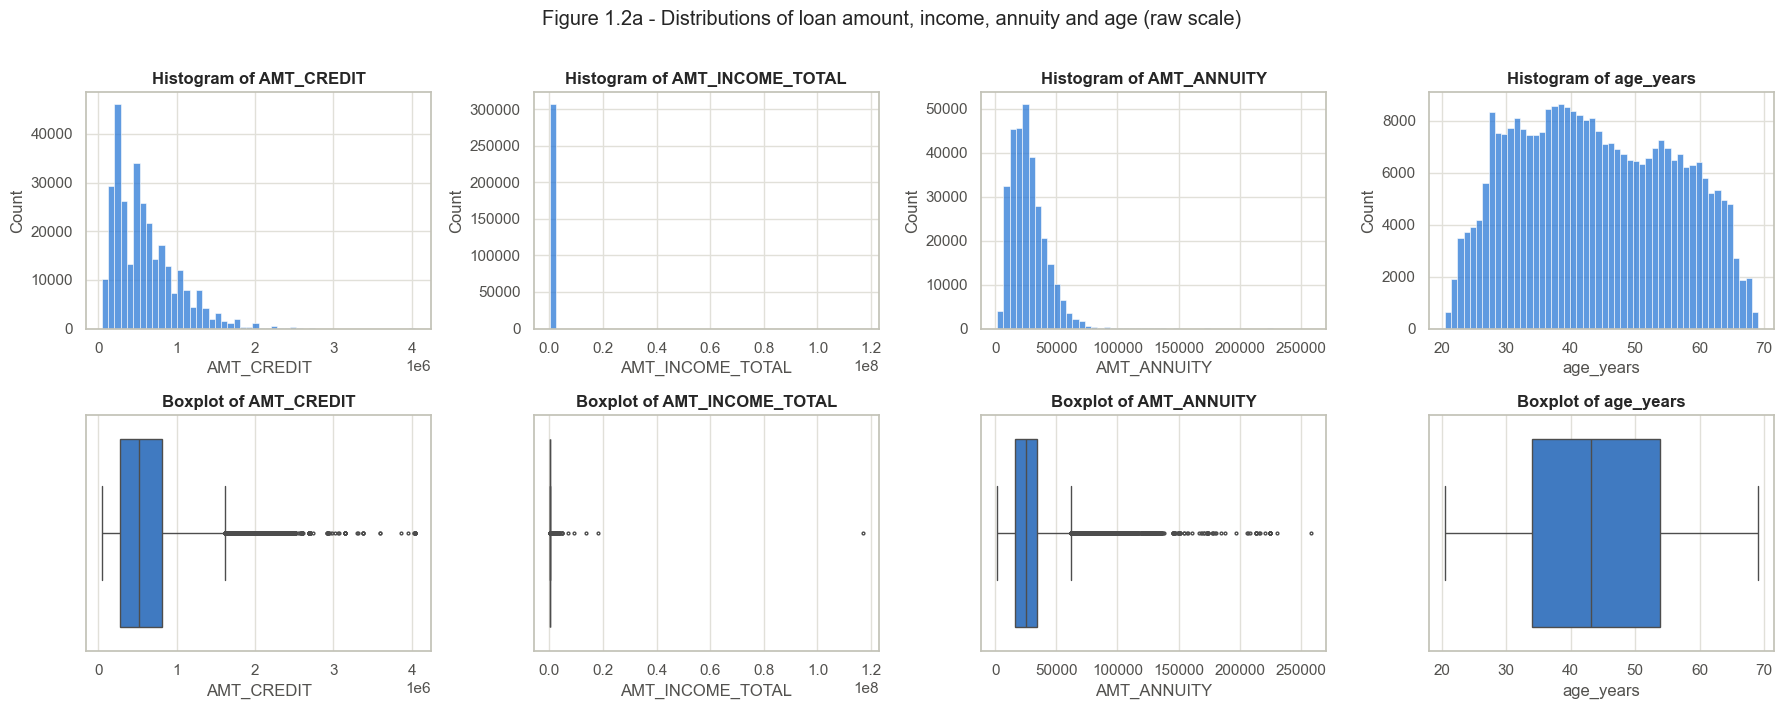

In [11]:
amount_vars = ['AMT_CREDIT', 'AMT_INCOME_TOTAL', 'AMT_ANNUITY']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))

for i, (name, values) in enumerate([*[(v, app_data[v]) for v in amount_vars], ('age_years', age_years)]):
    sns.histplot(values.dropna(), bins=50, color=BAR_COLOUR, ax=axes[0, i])
    axes[0, i].set_title(f'Histogram of {name}')
    sns.boxplot(x=values.dropna(), color=BAR_COLOUR, fliersize=2, ax=axes[1, i])
    axes[1, i].set_title(f'Boxplot of {name}')

plt.suptitle('Figure 1.2a - Distributions of loan amount, income, annuity and age (raw scale)', y=1.01)
plt.tight_layout()
plt.show()

The amounts are positively skewed, and one extreme income compresses the raw income chart. A log-scale view shows the body of each distribution without changing the data.

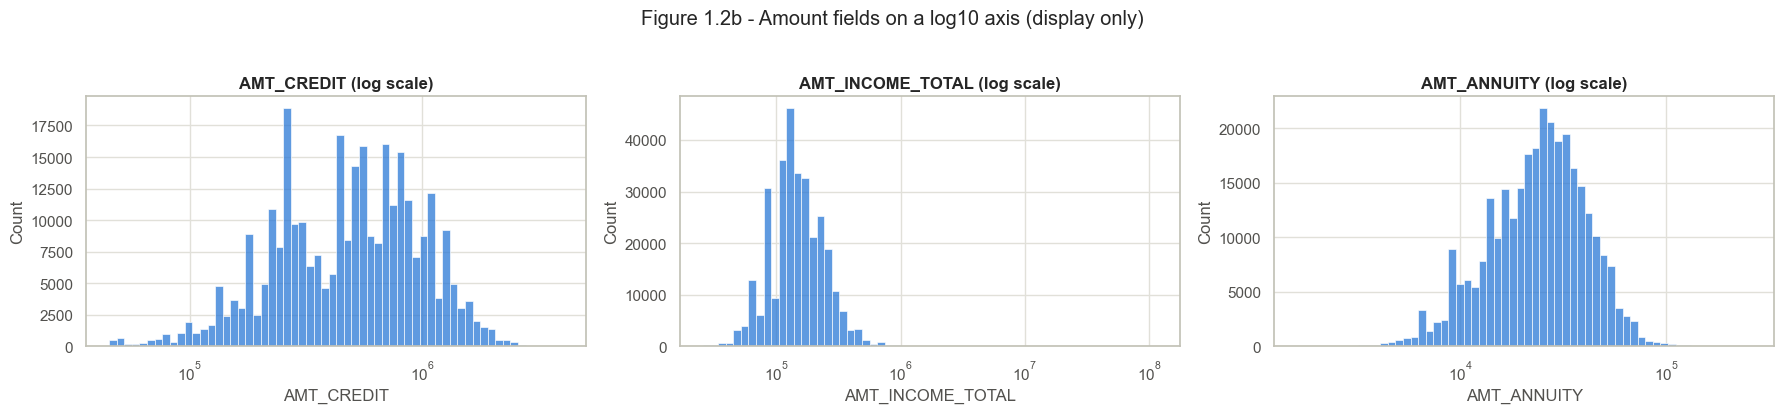

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, var in zip(axes, amount_vars):
    sns.histplot(app_data[var].dropna(), bins=60, log_scale=True, color=BAR_COLOUR, ax=ax)
    ax.set_title(f'{var} (log scale)')
plt.suptitle('Figure 1.2b - Amount fields on a log10 axis (display only)', y=1.03)
plt.tight_layout()
plt.show()

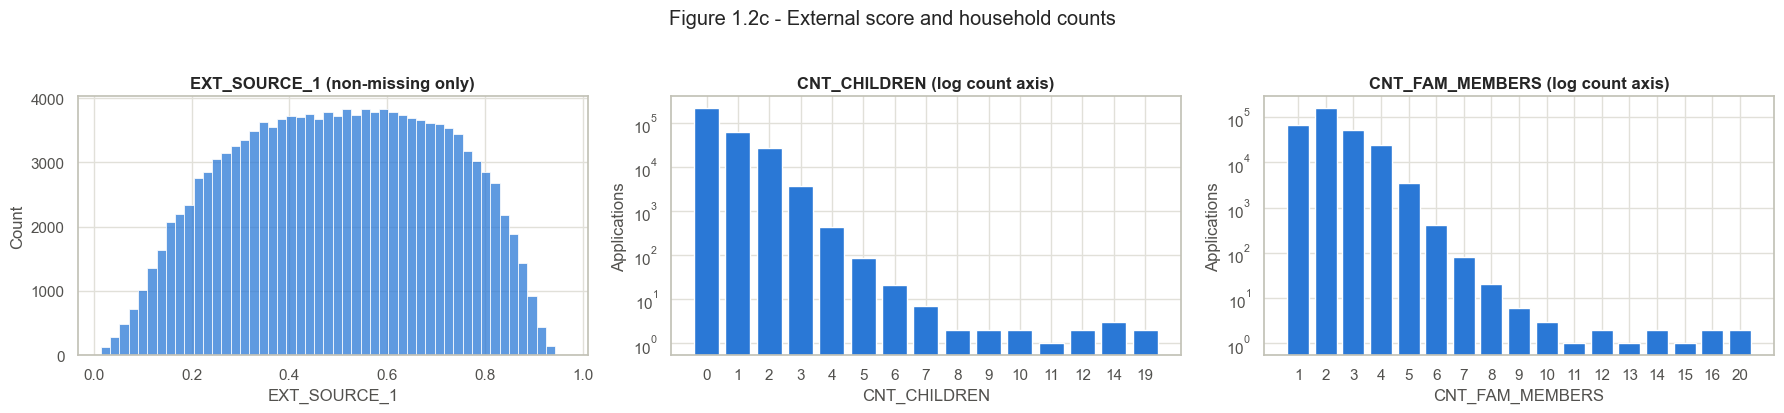

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(app_data['EXT_SOURCE_1'].dropna(), bins=50, color=BAR_COLOUR, ax=axes[0])
axes[0].set_title('EXT_SOURCE_1 (non-missing only)')
for ax, var in zip(axes[1:], ['CNT_CHILDREN', 'CNT_FAM_MEMBERS']):
    counts = app_data[var].value_counts().sort_index()
    ax.bar(counts.index.astype(int).astype(str), counts.values, color=BAR_COLOUR)
    ax.set_yscale('log')
    ax.set_title(f'{var} (log count axis)')
    ax.set_xlabel(var); ax.set_ylabel('Applications')
plt.suptitle('Figure 1.2c - External score and household counts', y=1.03)
plt.tight_layout()
plt.show()

Loan amount, income and annuity are right-skewed with long upper tails. The income tail is driven by a few very large values (see 1.6), which is why the raw histogram is unreadable and the log view is needed. Age is spread fairly evenly between about 21 and 69. `EXT_SOURCE_1` is roughly symmetric on its 0-1 scale but is missing for more than half of applications. Most applicants have no children, and household sizes above 6 are rare.

**Categorical fields.** Bar charts show the share of applications in each category.

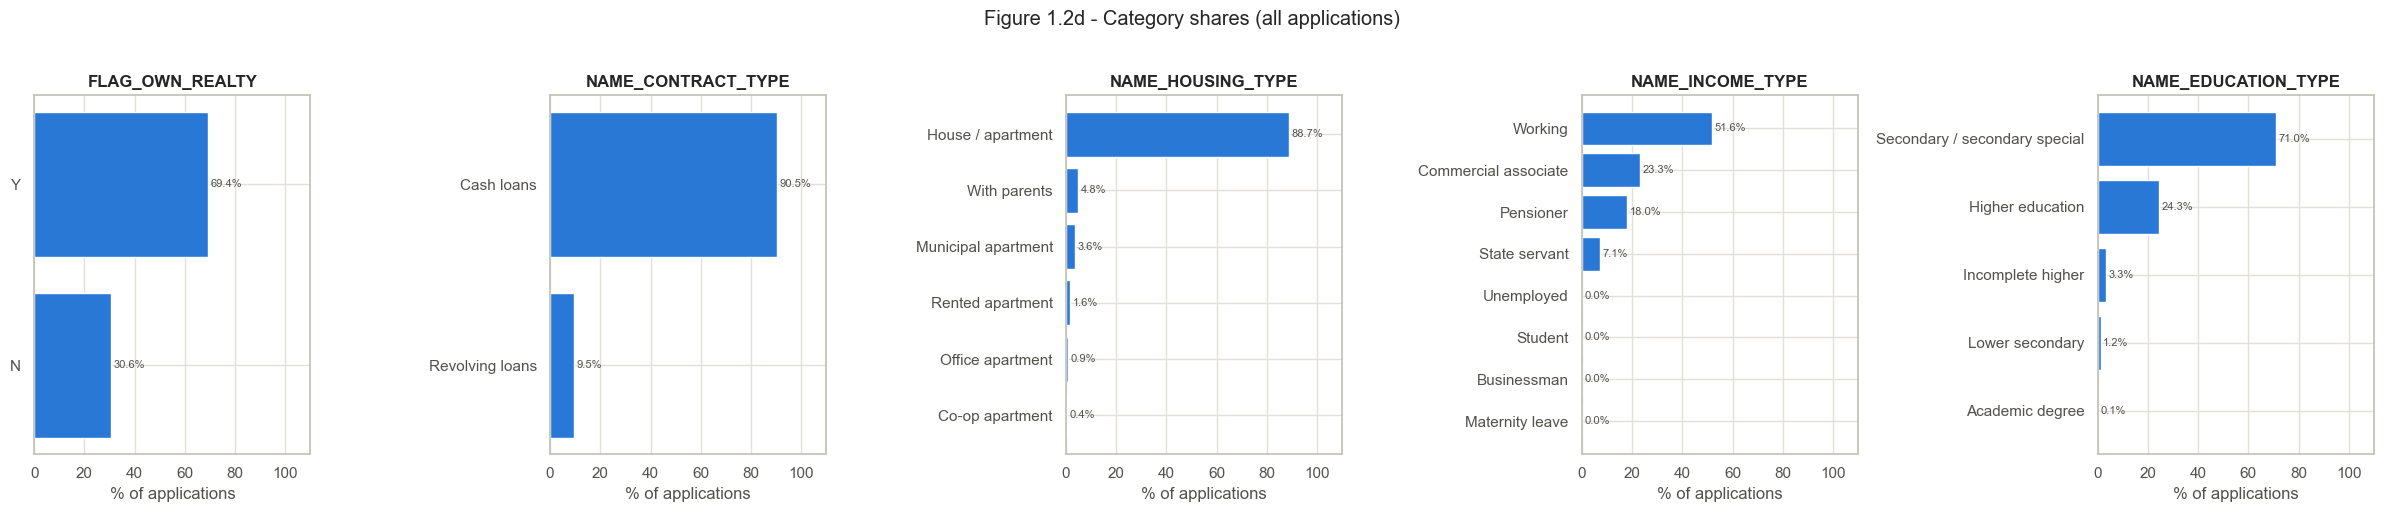

In [14]:
cat_vars = ['FLAG_OWN_REALTY', 'NAME_CONTRACT_TYPE', 'NAME_HOUSING_TYPE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE']
fig, axes = plt.subplots(1, 5, figsize=(24, 5))

for ax, var in zip(axes, cat_vars):
    shares = app_data[var].value_counts(normalize=True) * 100
    ax.barh(shares.index[::-1], shares.values[::-1], color=BAR_COLOUR)
    for y, v in enumerate(shares.values[::-1]):
        ax.text(v + 1, y, f'{v:.1f}%', va='center', fontsize=8, color='#52514e')
    ax.set_title(var); ax.set_xlabel('% of applications'); ax.set_xlim(0, 110)

plt.suptitle('Figure 1.2d - Category shares (all applications)', y=1.02)
plt.tight_layout()
plt.show()

**Target.** Count the goods and bads to see the class balance the scorecard has to work with.

In [15]:
target_table = app_data[TARGET].value_counts().sort_index().to_frame('Applications')
target_table.index = ['0 - good (no payment difficulty)', '1 - bad (payment difficulty)']
target_table['%'] = target_table['Applications'] / len(app_data) * 100
print('Table 1.2b - Target distribution (all applications)')
display(target_table.round(2))

Table 1.2b - Target distribution (all applications)


,Applications,%
0 - good (no payment difficulty),282686,91.9300
1 - bad (payment difficulty),24825,8.0700


In [16]:
# ratios between the amount fields help judge the (unstated) periodicity of income and annuity
credit_to_annuity = (app_data['AMT_CREDIT'] / app_data['AMT_ANNUITY']).median()
annuity_to_income = (app_data['AMT_ANNUITY'] / app_data['AMT_INCOME_TOTAL']).median()
print(f'Median AMT_CREDIT / AMT_ANNUITY:       {credit_to_annuity:.1f}')
print(f'Median AMT_ANNUITY / AMT_INCOME_TOTAL: {annuity_to_income:.3f}')

Median AMT_CREDIT / AMT_ANNUITY:       20.0
Median AMT_ANNUITY / AMT_INCOME_TOTAL: 0.163


Roughly one application in twelve is bad, so the classes are imbalanced. Accuracy alone would be a misleading measure later: a model that approves everyone would score above 90%.

About 69% of applicants own a house or flat. About 90% of loans are cash loans and the rest revolving. Most applicants are working, commercial associates, pensioners or state servants.

The median loan is about 20 times the annuity, and the median annuity is about 16% of recorded income. These ratios are consistent with a monthly instalment against monthly income, but the dictionary does not confirm the periods. The point matters only for loan term, pricing and profit in Step 5; ratio features are unaffected because they do not depend on the period.

## 1.3 Bivariate Analysis

Bivariate analysis compares goods and bads. KDE plots are normalised separately for each class (`common_norm=False`), so the two curves are comparable even though bads are only about 8% of the data. Where the curves separate, the variable carries information about risk.

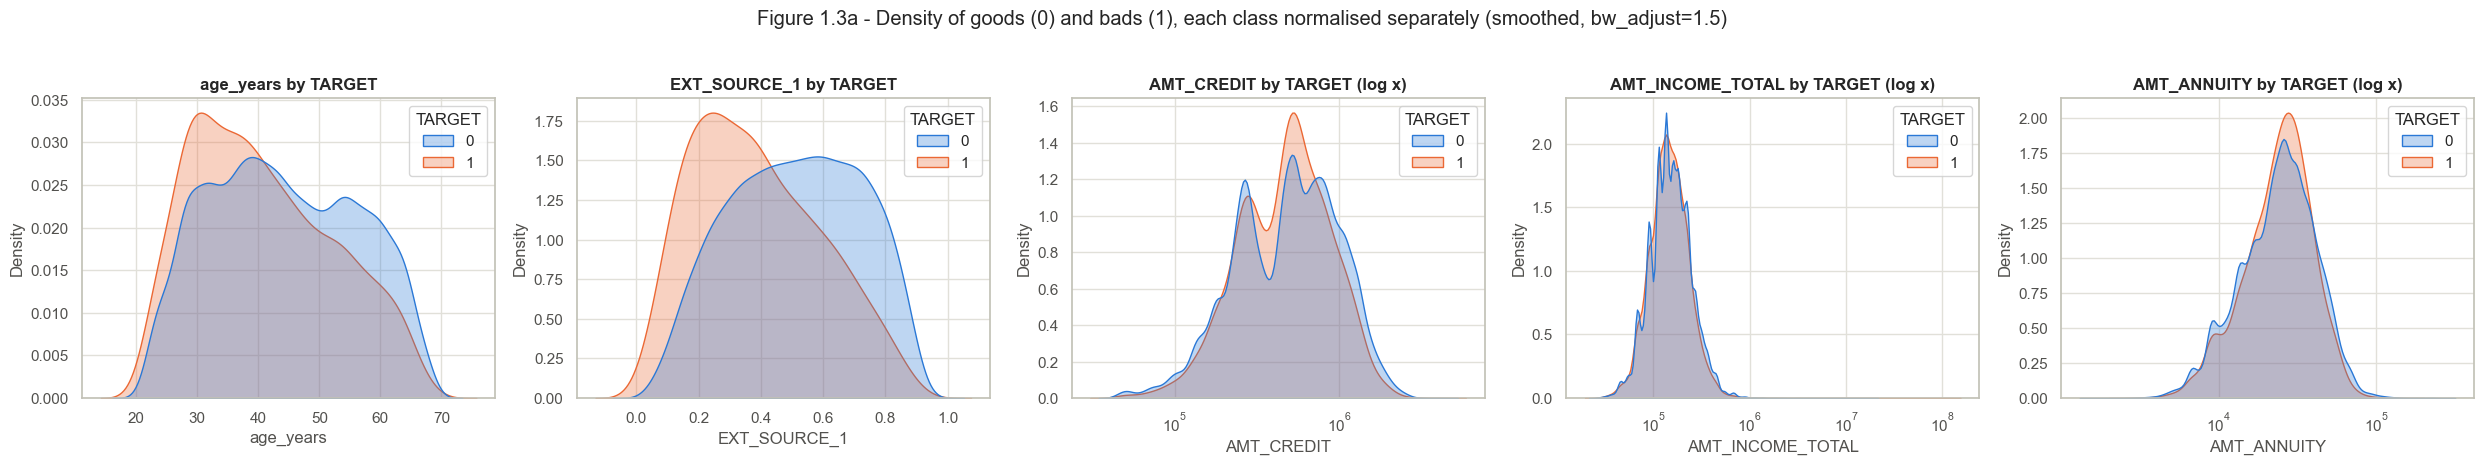

In [17]:
kde_data = app_data[['AMT_CREDIT', 'AMT_INCOME_TOTAL', 'AMT_ANNUITY', 'EXT_SOURCE_1', TARGET]].assign(age_years=age_years)
kde_vars = [('age_years', False), ('EXT_SOURCE_1', False), ('AMT_CREDIT', True), ('AMT_INCOME_TOTAL', True), ('AMT_ANNUITY', True)]

fig, axes = plt.subplots(1, 5, figsize=(25, 4.5))
for ax, (var, log) in zip(axes, kde_vars):
    sns.kdeplot(data=kde_data, x=var, hue=TARGET, common_norm=False, fill=True, alpha=0.3,
                palette=TARGET_PALETTE, log_scale=log, bw_adjust=1.5, ax=ax)
    ax.set_title(f'{var} by TARGET' + (' (log x)' if log else ''))
plt.suptitle('Figure 1.3a - Density of goods (0) and bads (1), each class normalised separately (smoothed, bw_adjust=1.5)', y=1.03)
plt.tight_layout()
plt.show()

In [18]:
median_table = kde_data.groupby(TARGET)[['age_years', 'EXT_SOURCE_1', 'AMT_CREDIT', 'AMT_INCOME_TOTAL', 'AMT_ANNUITY']].median().T
median_table.columns = ['Median - good (0)', 'Median - bad (1)']
print('Table 1.3a - Medians by target (EXT_SOURCE_1 uses non-missing values only)')
display(median_table.style.format('{:,.2f}'))

Table 1.3a - Medians by target (EXT_SOURCE_1 uses non-missing values only)


,Median - good (0),Median - bad (1)
age_years,43.47,39.10
EXT_SOURCE_1,0.52,0.36
AMT_CREDIT,"517,788.00","497,520.00"
AMT_INCOME_TOTAL,"148,500.00","135,000.00"
AMT_ANNUITY,"24,876.00","25,263.00"


Bads are younger on average, and they have clearly lower `EXT_SOURCE_1` scores; that curve shows the strongest separation of the five. The amount fields overlap heavily: bads have slightly lower incomes and loans, while annuities are almost the same. Whether any of these differences survives binning and screening will be tested on development training data in Step 3.

**Bad rate by category.** Each bar shows the share of applications in the category with `TARGET = 1`, with the number of applications printed alongside so that rates from small groups are not over-read.

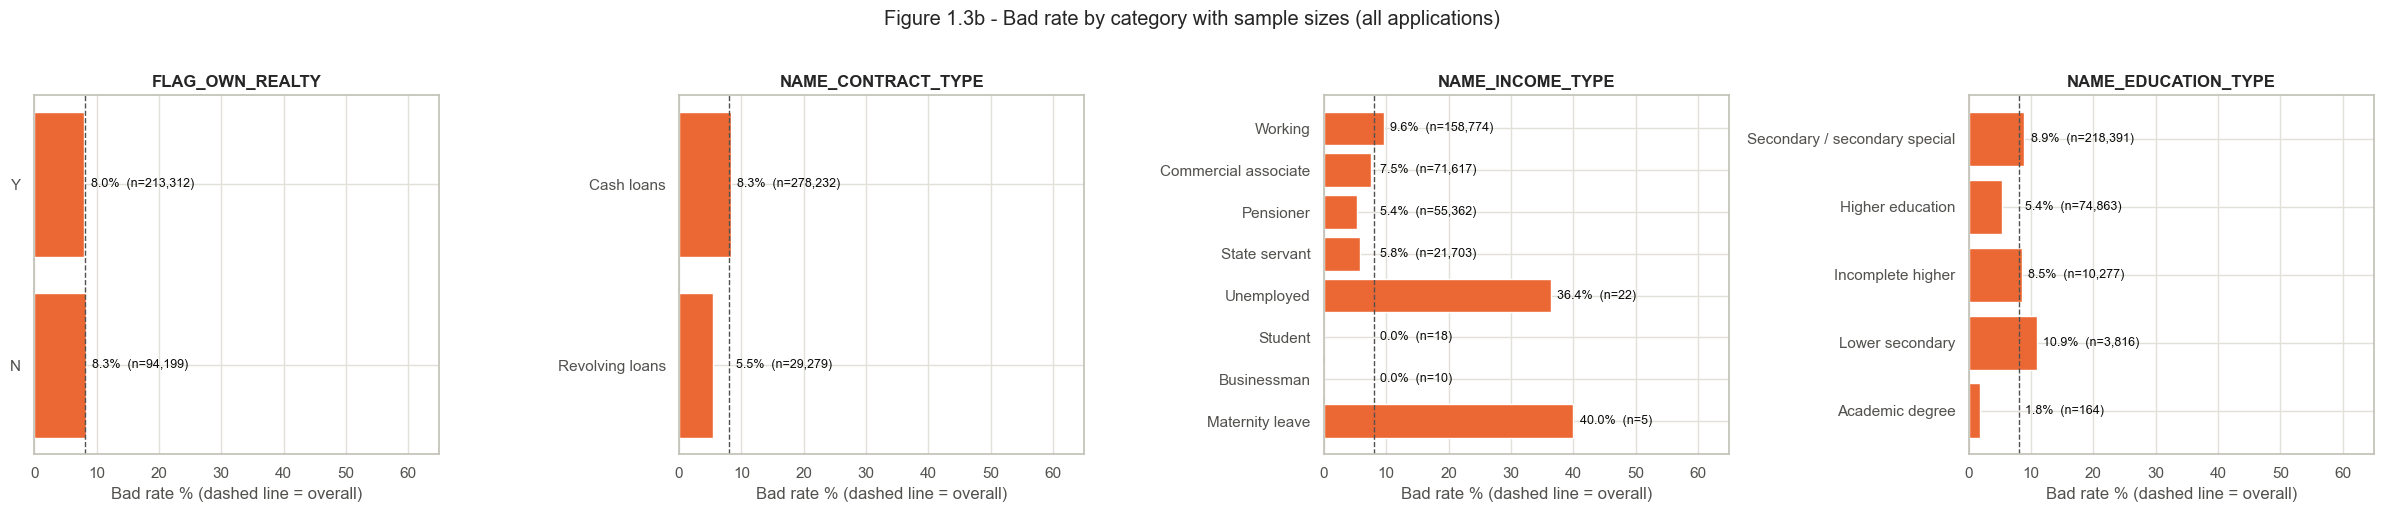

In [19]:
def bad_rate_table(data, var):
    # count, number of bads and bad rate for each category of var
    table = data.groupby(var, dropna=False)[TARGET].agg(Applications='count', Bads='sum')
    table['Bad rate %'] = table['Bads'] / table['Applications'] * 100
    return table.sort_values('Applications', ascending=False)

overall_bad_rate = app_data[TARGET].mean() * 100
biv_vars = ['FLAG_OWN_REALTY', 'NAME_CONTRACT_TYPE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE']

fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, var in zip(axes, biv_vars):
    table = bad_rate_table(app_data, var)
    ax.barh(table.index.astype(str)[::-1], table['Bad rate %'][::-1], color=BAD_COLOUR)
    ax.axvline(overall_bad_rate, color='#52514e', linestyle='--', linewidth=1)
    for y, (rate, n) in enumerate(zip(table['Bad rate %'][::-1], table['Applications'][::-1])):
        ax.text(max(rate, overall_bad_rate) + 1, y, f'{rate:.1f}%  (n={n:,})', va='center', fontsize=9, color='#0b0b0b')
    ax.set_title(var); ax.set_xlabel('Bad rate % (dashed line = overall)'); ax.set_xlim(0, 65)
plt.suptitle('Figure 1.3b - Bad rate by category with sample sizes (all applications)', y=1.02)
plt.tight_layout()
plt.show()

**Income types and the inclusion decision.** The checkpoint segment kept only working, commercial-associate and state-servant applicants. Following the professor's feedback ("income type do not discriminate"), no income group is excluded. The table below shows what that earlier filter would have removed. It explains the inclusion decision and is not used to pick a lower-risk population.

In [20]:
earned_income = ['Working', 'Commercial associate', 'State servant']
income_table = bad_rate_table(app_data, 'NAME_INCOME_TYPE')
income_table['Excluded by earlier filter'] = ~income_table.index.isin(earned_income)
print('Table 1.3b - Bad rate by income type')
display(income_table.round(2))

excluded = ~app_data['NAME_INCOME_TYPE'].isin(earned_income)
print(f'Applications the earned-income filter would have removed: {excluded.sum():,} ({excluded.mean():.1%})')

Table 1.3b - Bad rate by income type


,Applications,Bads,Bad rate %,Excluded by earlier filter
NAME_INCOME_TYPE,,,,
Working,158774,15224,9.5900,False
Commercial associate,71617,5360,7.4800,False
Pensioner,55362,2982,5.3900,True
State servant,21703,1249,5.7500,False
Unemployed,22,8,36.3600,True
Student,18,0,0.0000,True
Businessman,10,0,0.0000,True
Maternity leave,5,2,40.0000,True


Applications the earned-income filter would have removed: 55,417 (18.0%)


The earlier filter would have removed about 18% of applicants, almost all of them pensioners. Pensioners have a bad rate *below* the overall average, so excluding them would have raised the segment's bad rate. It would also have excluded a large group of potential borrowers on the basis of income source. The remaining excluded groups (unemployed, student, businessman, maternity leave) together number fewer than 60 applicants, so their bad rates are too unstable to interpret.

Revolving loans and applicants with higher education show lower bad rates. Owners and non-owners differ only slightly. These are whole-population descriptions, and they say nothing about cause.

**Gender audit (not a model input).** `CODE_GENDER` is excluded from modelling on fair-lending grounds. Its bad rates are shown only to make the exclusion transparent.

In [21]:
print('Table 1.3c - Bad rate by CODE_GENDER (audit only, not used in the scorecard)')
display(bad_rate_table(app_data, 'CODE_GENDER').round(2))

Table 1.3c - Bad rate by CODE_GENDER (audit only, not used in the scorecard)


,Applications,Bads,Bad rate %
CODE_GENDER,,,
F,202448,14170,7.0000
M,105059,10655,10.1400
XNA,4,0,0.0000


Male applicants show a higher bad rate than female applicants. Because gender would pass a purely statistical screen, it is excluded by policy rather than by the data. The difference is descriptive. It may reflect other characteristics that differ between the groups, and it is not evidence that the scorecard is fair or unfair. The four `XNA` records are an invalid code (see 1.6).

## 1.4 Correlation Analysis

A correlation heat map shows which numeric characteristics overlap and may be redundant. Identifiers, the target, binary document flags and categorical codes are left out. For this view only, `DAYS_EMPLOYED = 365243` is set to missing so that the sentinel does not distort the correlations (see 1.6). Spearman rank correlation is used because the amounts are heavily skewed.

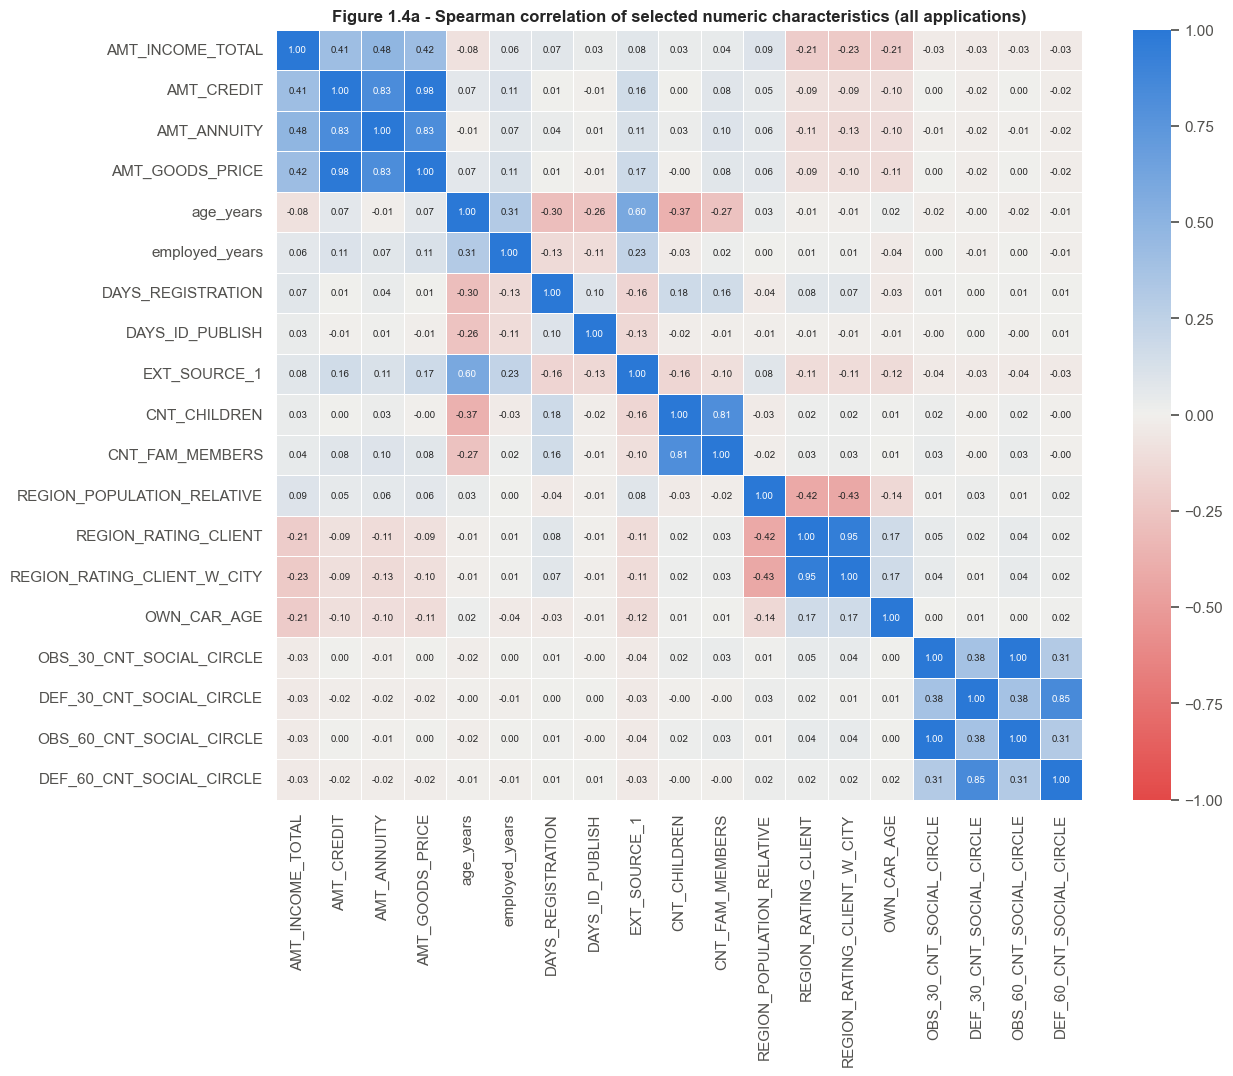

In [22]:
corr_data = pd.DataFrame({
    'AMT_INCOME_TOTAL': app_data['AMT_INCOME_TOTAL'], 'AMT_CREDIT': app_data['AMT_CREDIT'],
    'AMT_ANNUITY': app_data['AMT_ANNUITY'], 'AMT_GOODS_PRICE': app_data['AMT_GOODS_PRICE'],
    'age_years': age_years,
    'employed_years': -app_data['DAYS_EMPLOYED'].where(app_data['DAYS_EMPLOYED'] != 365243) / 365.25,
    'DAYS_REGISTRATION': app_data['DAYS_REGISTRATION'], 'DAYS_ID_PUBLISH': app_data['DAYS_ID_PUBLISH'],
    'EXT_SOURCE_1': app_data['EXT_SOURCE_1'], 'CNT_CHILDREN': app_data['CNT_CHILDREN'],
    'CNT_FAM_MEMBERS': app_data['CNT_FAM_MEMBERS'], 'REGION_POPULATION_RELATIVE': app_data['REGION_POPULATION_RELATIVE'],
    'REGION_RATING_CLIENT': app_data['REGION_RATING_CLIENT'], 'REGION_RATING_CLIENT_W_CITY': app_data['REGION_RATING_CLIENT_W_CITY'],
    'OWN_CAR_AGE': app_data['OWN_CAR_AGE'], 'OBS_30_CNT_SOCIAL_CIRCLE': app_data['OBS_30_CNT_SOCIAL_CIRCLE'],
    'DEF_30_CNT_SOCIAL_CIRCLE': app_data['DEF_30_CNT_SOCIAL_CIRCLE'], 'OBS_60_CNT_SOCIAL_CIRCLE': app_data['OBS_60_CNT_SOCIAL_CIRCLE'],
    'DEF_60_CNT_SOCIAL_CIRCLE': app_data['DEF_60_CNT_SOCIAL_CIRCLE'],
})
cor = corr_data.corr(method='spearman')

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(cor, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap=CORR_CMAP, vmin=-1, vmax=1, center=0,
            linewidths=0.5, linecolor='white', ax=ax)
ax.set_title('Figure 1.4a - Spearman correlation of selected numeric characteristics (all applications)')
plt.show()

List the pairs above |0.8|, then check the specific overlaps flagged in the checkpoint: credit versus goods price, income versus annuity, and the building AVG / MODE / MEDI triplets.

In [23]:
pairs = cor.where(np.triu(np.ones(cor.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).to_frame('Spearman r')
print('Table 1.4a - Pairs with |r| > 0.8 among the selected characteristics')
display(high_pairs.round(3))

check_pairs = [('AMT_CREDIT', 'AMT_GOODS_PRICE'), ('AMT_INCOME_TOTAL', 'AMT_ANNUITY'),
               ('APARTMENTS_AVG', 'APARTMENTS_MODE'), ('APARTMENTS_AVG', 'APARTMENTS_MEDI'),
               ('LIVINGAREA_AVG', 'LIVINGAREA_MODE'), ('LIVINGAREA_AVG', 'LIVINGAREA_MEDI'),
               ('YEARS_BUILD_AVG', 'YEARS_BUILD_MEDI'), ('APARTMENTS_AVG', 'LIVINGAREA_AVG')]
pair_table = pd.DataFrame([{'Variable 1': a, 'Variable 2': b,
                            'Pearson r': app_data[a].corr(app_data[b]),
                            'Spearman r': app_data[a].corr(app_data[b], method='spearman')} for a, b in check_pairs])
print('Table 1.4b - Specific overlaps checked')
display(pair_table.round(3))

Table 1.4a - Pairs with |r| > 0.8 among the selected characteristics


,,Spearman r
OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.9970
AMT_CREDIT,AMT_GOODS_PRICE,0.9850
REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,0.9500
DEF_30_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,0.8450
AMT_CREDIT,AMT_ANNUITY,0.8300
AMT_ANNUITY,AMT_GOODS_PRICE,0.8280
CNT_CHILDREN,CNT_FAM_MEMBERS,0.8120


Table 1.4b - Specific overlaps checked


,Variable 1,Variable 2,Pearson r,Spearman r
0,AMT_CREDIT,AMT_GOODS_PRICE,0.9870,0.9850
1,AMT_INCOME_TOTAL,AMT_ANNUITY,0.1920,0.4820
2,APARTMENTS_AVG,APARTMENTS_MODE,0.9730,0.9650
3,APARTMENTS_AVG,APARTMENTS_MEDI,0.9950,0.9950
4,LIVINGAREA_AVG,LIVINGAREA_MODE,0.9720,0.9640
5,LIVINGAREA_AVG,LIVINGAREA_MEDI,0.9960,0.9960
6,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.9980,0.9980
7,APARTMENTS_AVG,LIVINGAREA_AVG,0.9140,0.9060


Several groups overlap strongly:
- **Loan amount and goods price** move almost one for one, because the loan largely finances the goods price.
- **Children and family size** are strongly related.
- **The two region ratings** are strongly related.
- **The 30-day and 60-day social-circle counts** are near duplicates.
- **The building AVG, MODE and MEDI versions** of the same measure are near duplicates, so one version of each will usually be enough.

Annuity also correlates strongly with loan amount and goods price, so these three fields form one cluster. Income and annuity are only moderately related, because the annuity depends mostly on the loan size. `EXT_SOURCE_1` is moderately correlated with age (about 0.6), so part of its signal may overlap with age.

No variable is dropped here. Correlations on the full data are descriptive. Any redundancy decision is a learned choice, so it is made on development training data in 2.8 and 3.4, after the partitions in 2.9.

## 1.5 Identify Missing Values

Measure missing values by column and by row. The pattern of missingness can itself carry information, so it is described before any treatment is chosen (Module 9.1).

In [24]:
missing_cols = app_data.isna().sum().to_frame('Missing')
missing_cols['% missing'] = missing_cols['Missing'] / len(app_data) * 100
missing_cols = missing_cols[missing_cols['Missing'] > 0].sort_values('Missing', ascending=False)
missing_cols['Building field'] = missing_cols.index.isin(building_cols)

print(f'Columns with any missing value: {len(missing_cols)} of {app_data.shape[1]} '
      f'({missing_cols["Building field"].sum()} are building fields)')
print('Table 1.5a - Missing values in key non-building fields')
display(missing_cols[~missing_cols['Building field']].drop(columns='Building field').round(2))

Columns with any missing value: 65 of 120 (47 are building fields)
Table 1.5a - Missing values in key non-building fields


,Missing,% missing
OWN_CAR_AGE,202929,65.9900
EXT_SOURCE_1,173378,56.3800
OCCUPATION_TYPE,96391,31.3500
AMT_REQ_CREDIT_BUREAU_QRT,41519,13.5000
AMT_REQ_CREDIT_BUREAU_WEEK,41519,13.5000
AMT_REQ_CREDIT_BUREAU_YEAR,41519,13.5000
AMT_REQ_CREDIT_BUREAU_HOUR,41519,13.5000
AMT_REQ_CREDIT_BUREAU_MON,41519,13.5000
AMT_REQ_CREDIT_BUREAU_DAY,41519,13.5000
NAME_TYPE_SUITE,1292,0.4200


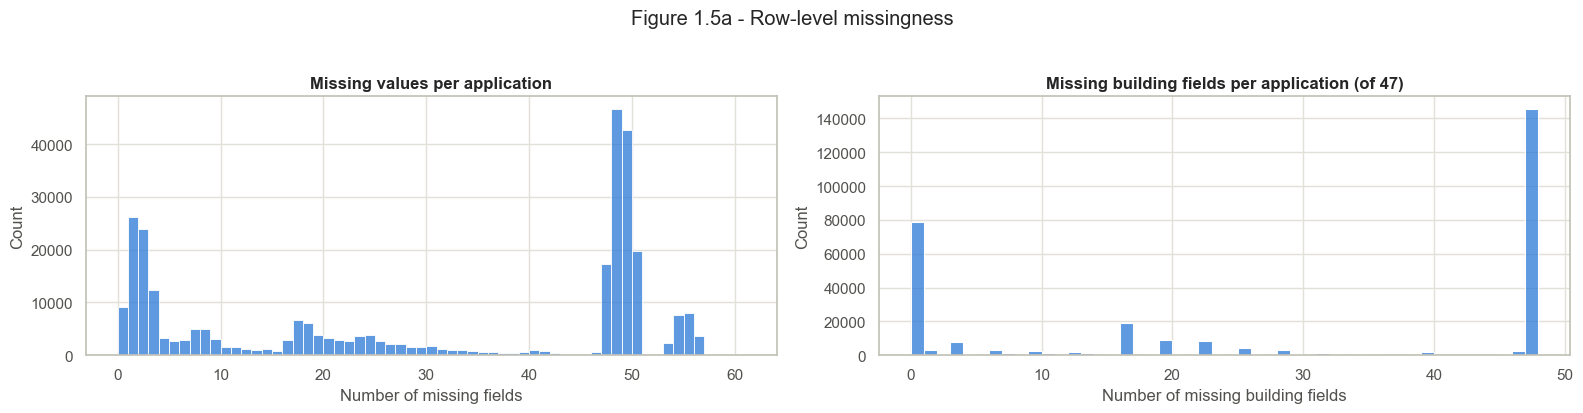

Applications with no missing value:          3.0%
Applications missing all 47 building fields: 47.4%
Applications with complete building fields:   25.6%


In [25]:
row_missing = app_data.isna().sum(axis=1)
building_missing = app_data[building_cols].isna().sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.histplot(row_missing, bins=range(0, row_missing.max() + 2), color=BAR_COLOUR, ax=axes[0])
axes[0].set_title('Missing values per application'); axes[0].set_xlabel('Number of missing fields')
sns.histplot(building_missing, bins=range(0, len(building_cols) + 2), color=BAR_COLOUR, ax=axes[1])
axes[1].set_title(f'Missing building fields per application (of {len(building_cols)})'); axes[1].set_xlabel('Number of missing building fields')
plt.suptitle('Figure 1.5a - Row-level missingness', y=1.03)
plt.tight_layout()
plt.show()

print(f'Applications with no missing value:          {(row_missing == 0).mean():.1%}')
print(f'Applications missing all {len(building_cols)} building fields: {(building_missing == len(building_cols)).mean():.1%}')
print(f'Applications with complete building fields:   {(building_missing == 0).mean():.1%}')

Missingness is concentrated in columns, not spread randomly across rows. Most missing cells are in the building fields, which tend to be either all present or all absent for an applicant. This suggests that building information was not collected for many applicants, rather than being skipped field by field.

Plausible structural explanations can be checked against other fields.

In [26]:
print('Table 1.5b - OWN_CAR_AGE missing by car ownership')
display(pd.crosstab(app_data['FLAG_OWN_CAR'], app_data['OWN_CAR_AGE'].isna().rename('OWN_CAR_AGE missing')))

print('Table 1.5c - OCCUPATION_TYPE missing by income type')
display(pd.crosstab(app_data['NAME_INCOME_TYPE'], app_data['OCCUPATION_TYPE'].isna().rename('OCCUPATION_TYPE missing')))

Table 1.5b - OWN_CAR_AGE missing by car ownership


OWN_CAR_AGE missing,False,True
FLAG_OWN_CAR,,
N,0,202924
Y,104582,5


Table 1.5c - OCCUPATION_TYPE missing by income type


OCCUPATION_TYPE missing,False,True
NAME_INCOME_TYPE,,
Businessman,8,2
Commercial associate,59320,12297
Maternity leave,4,1
Pensioner,5,55357
State servant,17916,3787
Student,13,5
Unemployed,0,22
Working,133854,24920


In [27]:
def missing_bad_rate(var):
    # descriptive bad rate for applications with and without a value
    table = app_data.groupby(app_data[var].isna())[TARGET].agg(Applications='count', Bads='sum')
    table['Bad rate %'] = table['Bads'] / table['Applications'] * 100
    table.index = [f'{var} reported', f'{var} missing']
    return table

print('Table 1.5d - Descriptive bad rate when the value is reported vs missing')
display(pd.concat([missing_bad_rate(v) for v in ['EXT_SOURCE_1', 'OCCUPATION_TYPE', 'OWN_CAR_AGE', 'TOTALAREA_MODE']]).round(2))

Table 1.5d - Descriptive bad rate when the value is reported vs missing


,Applications,Bads,Bad rate %
EXT_SOURCE_1 reported,134133,10054,7.5000
EXT_SOURCE_1 missing,173378,14771,8.5200
OCCUPATION_TYPE reported,211120,18547,8.7900
OCCUPATION_TYPE missing,96391,6278,6.5100
OWN_CAR_AGE reported,104582,7576,7.2400
OWN_CAR_AGE missing,202929,17249,8.5000
TOTALAREA_MODE reported,159080,11119,6.9900
TOTALAREA_MODE missing,148431,13706,9.2300


- `OWN_CAR_AGE` is missing for every applicant without a car. This is structurally missing: the question does not apply.
- `OCCUPATION_TYPE` is missing for almost all pensioners and unemployed applicants, which fits the same pattern. It is also missing for about one working applicant in six, where no structural reason is visible.
- `EXT_SOURCE_1` is missing for more than half of applicants, and those applicants have a higher bad rate than applicants with a score. Missing building information and missing car age also go with higher bad rates.
- Missing `OCCUPATION_TYPE` goes with a *lower* bad rate, because that group is dominated by pensioners. Missingness can therefore point either way on risk, and is best kept as a separate group whose effect the data can show.

These patterns show that missingness is related to other characteristics and to risk. They do not prove a mechanism, so the data are not labelled MCAR, MAR or MNAR from these tables alone. Unreported values are kept as their own "Missing" group in the binning (Module 10.4) rather than deleting applicants. This follows the professor's guidance to be as inclusive as possible.

**Bureau linkage.** An application with no bureau record differs from a bureau record with a missing amount. The first means the applicant has no reported credit history in the file; the second is a gap inside a record that exists.

In [28]:
has_bureau = app_ids.isin(bureau_ids)
link_status = app_data.groupby(has_bureau.map({True: 'Has bureau record(s)', False: 'No bureau record'}))[TARGET].agg(
    Applications='count', Bads='sum')
link_status['% of applications'] = link_status['Applications'] / len(app_data) * 100
link_status['Bad rate %'] = link_status['Bads'] / link_status['Applications'] * 100
print('Table 1.5e - Applications with and without bureau history (descriptive)')
display(link_status.round(2))

print('Table 1.5f - AMT_REQ_CREDIT_BUREAU_YEAR missing vs bureau history')
display(pd.crosstab(app_data['AMT_REQ_CREDIT_BUREAU_YEAR'].isna().rename('Enquiry count missing'),
                    has_bureau.rename('Has bureau record')))

Table 1.5e - Applications with and without bureau history (descriptive)


,Applications,Bads,% of applications,Bad rate %
SK_ID_CURR,,,,
Has bureau record(s),263491,20368,85.6900,7.7300
No bureau record,44020,4457,14.3100,10.1200


Table 1.5f - AMT_REQ_CREDIT_BUREAU_YEAR missing vs bureau history


Has bureau record,False,True
Enquiry count missing,,
False,2501,263491
True,41519,0


In [29]:
bureau_missing = bureau_data.isna().mean().mul(100).round(2)
bureau_missing = bureau_missing[bureau_missing > 0].sort_values(ascending=False).to_frame('% missing (bureau rows)')
print('Table 1.5g - Missing values inside existing bureau records')
display(bureau_missing)

print('Table 1.5h - DAYS_ENDDATE_FACT missing by credit status')
display(pd.crosstab(bureau_data['CREDIT_ACTIVE'], bureau_data['DAYS_ENDDATE_FACT'].isna().rename('End date missing')))

Table 1.5g - Missing values inside existing bureau records


,% missing (bureau rows)
AMT_ANNUITY,71.4700
AMT_CREDIT_MAX_OVERDUE,65.5100
DAYS_ENDDATE_FACT,36.9200
AMT_CREDIT_SUM_LIMIT,34.4800
AMT_CREDIT_SUM_DEBT,15.0100
DAYS_CREDIT_ENDDATE,6.1500


Table 1.5h - DAYS_ENDDATE_FACT missing by credit status


End date missing,False,True
CREDIT_ACTIVE,,
Active,1969,628638
Bad debt,10,11
Closed,1079148,125
Sold,1648,4879


About one applicant in seven has no bureau record, and this group has a higher descriptive bad rate than applicants with bureau history. A missing credit history is therefore itself a risk signal. These applicants will form a separate "no bureau history" group after aggregation rather than being dropped or given zeros.

The bureau enquiry counts (`AMT_REQ_CREDIT_BUREAU_*`) are missing only for applicants with no bureau record, so they are part of the same structural gap.

Inside existing bureau records, several gaps are structural:
- `DAYS_ENDDATE_FACT` is defined only for closed credit, and it is missing for almost all active credits.
- `AMT_ANNUITY` and `AMT_CREDIT_MAX_OVERDUE` are missing for most records, which limits their use.

## 1.6 Detect and Assess Outliers

Outliers can be valid but unusual observations (a very high income) or invalid values that cannot be true (Module 7.3). Two simple screens from class are used to *detect* them:
- **z-score:** z = (x − μ) / σ, flagging |z| > 3;
- **IQR fences:** values outside Q1 − 1.5·IQR and Q3 + 1.5·IQR.

No values are capped or removed in this step.

In [30]:
outlier_vars = ['AMT_INCOME_TOTAL', 'AMT_ANNUITY', 'AMT_CREDIT', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS']
rows = []
for var in outlier_vars:
    x = app_data[var]
    z = (x - x.mean()) / x.std()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    rows.append({'Variable': var, 'Median': x.median(), '99th pct': x.quantile(0.99), '99.9th pct': x.quantile(0.999),
                 'Max': x.max(), '|z| > 3': int((z.abs() > 3).sum()),
                 'Outside IQR fences': int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())})
print('Table 1.6a - Extreme values and outlier counts (application data)')
display(pd.DataFrame(rows).set_index('Variable').style.format('{:,.0f}'))

print('Five largest incomes:', [f'{v:,.0f}' for v in app_data['AMT_INCOME_TOTAL'].nlargest(5)])
print('Applications with 10+ children:', (app_data['CNT_CHILDREN'] >= 10).sum(),
      '| with 12+ family members:', (app_data['CNT_FAM_MEMBERS'] >= 12).sum())
print('Applications with annuity above recorded income:', (app_data['AMT_ANNUITY'] > app_data['AMT_INCOME_TOTAL']).sum())

Table 1.6a - Extreme values and outlier counts (application data)


,Median,99th pct,99.9th pct,Max,|z| > 3,Outside IQR fences
Variable,,,,,,
AMT_INCOME_TOTAL,"147,150","472,500","900,000","117,000,000",454,"14,035"
AMT_ANNUITY,"24,903","70,006","110,048","258,026","2,959","7,504"
AMT_CREDIT,"513,531","1,854,000","2,517,300","4,050,000","3,255","6,562"
CNT_CHILDREN,0,3,4,19,"4,272","4,272"
CNT_FAM_MEMBERS,2,5,6,20,"4,007","4,007"


Five largest incomes: ['117,000,000', '18,000,090', '13,500,000', '9,000,000', '6,750,000']
Applications with 10+ children: 10 | with 12+ family members: 10
Applications with annuity above recorded income: 33


The z-score and IQR screens flag thousands of records, because the amounts are skewed and the screens assume a roughly symmetric distribution. Most flagged values are plausible high earners or large loans, so they are *unusual*, not impossible. They should be kept and handled by placing them in the end bins.

A few values deserve review:
- **Income of 117,000,000.** This is more than 100 times the 99.9th percentile and looks like a recording error, though it cannot be proven wrong.
- **19 children and up to 20 family members.** These are rare but possible.

**Employment days sentinel.** `DAYS_EMPLOYED` should be negative (days before the application). Its maximum of 365,243 days would mean about 1,000 years of employment in the future, so it is a code, not a duration.

DAYS_EMPLOYED = 365243: 55,374 applications (18.0%)
Other positive DAYS_EMPLOYED values: 0
Table 1.6b - Income type of applications with the sentinel


,Applications
NAME_INCOME_TYPE,
Pensioner,55352
Unemployed,22


ORGANIZATION_TYPE = "XNA" on the same rows: True | total XNA: 55374


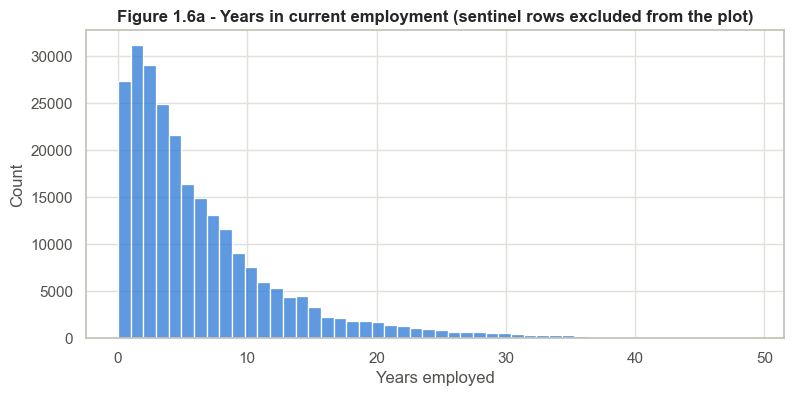

In [31]:
sentinel = app_data['DAYS_EMPLOYED'] == 365243
print(f'DAYS_EMPLOYED = 365243: {sentinel.sum():,} applications ({sentinel.mean():.1%})')
print(f'Other positive DAYS_EMPLOYED values: {((app_data["DAYS_EMPLOYED"] > 0) & ~sentinel).sum()}')
print('Table 1.6b - Income type of applications with the sentinel')
display(app_data.loc[sentinel, 'NAME_INCOME_TYPE'].value_counts().to_frame('Applications'))
print('ORGANIZATION_TYPE = "XNA" on the same rows:', (app_data.loc[sentinel, 'ORGANIZATION_TYPE'] == 'XNA').all(),
      '| total XNA:', (app_data['ORGANIZATION_TYPE'] == 'XNA').sum())

employed_years = -app_data.loc[~sentinel, 'DAYS_EMPLOYED'] / 365.25
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(employed_years, bins=50, color=BAR_COLOUR, ax=ax)
ax.set_title('Figure 1.6a - Years in current employment (sentinel rows excluded from the plot)')
ax.set_xlabel('Years employed')
plt.show()

The sentinel appears only for pensioners and unemployed applicants, and it coincides exactly with `ORGANIZATION_TYPE = 'XNA'`. It therefore means "not currently employed", not a real length of service. It should become its own "not employed" category rather than a number. Without the sentinel, employment length is right-skewed with a maximum of about 49 years, which is plausible.

**Invalid gender code.** `CODE_GENDER` has four `XNA` records. This is a data-quality issue only: gender is not a model input.

In [32]:
print('CODE_GENDER values:', app_data['CODE_GENDER'].value_counts().to_dict())
print('FLAG_MOBIL values: ', app_data['FLAG_MOBIL'].value_counts().to_dict())

CODE_GENDER values: {'F': 202448, 'M': 105059, 'XNA': 4}
FLAG_MOBIL values:  {1: 307510, 0: 1}


**Bureau dates and amounts.** Bureau day offsets should lie before the application date, and balances should not be negative.

In [33]:
bureau_vars = ['DAYS_CREDIT', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'DAYS_CREDIT_UPDATE', 'CREDIT_DAY_OVERDUE',
               'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG']
bureau_q = bureau_data[bureau_vars].quantile([0, 0.001, 0.5, 0.999, 1]).T
bureau_q.columns = ['Min', '0.1th pct', 'Median', '99.9th pct', 'Max']
print('Table 1.6c - Extreme quantiles of bureau fields')
display(bureau_q.style.format('{:,.0f}'))

checks = {
    'DAYS_CREDIT_ENDDATE more than 20,000 days ahead (> 54 years)': (bureau_data['DAYS_CREDIT_ENDDATE'] > 20000).sum(),
    'DAYS_CREDIT_ENDDATE / DAYS_ENDDATE_FACT more than 20,000 days ago': ((bureau_data['DAYS_CREDIT_ENDDATE'] < -20000) | (bureau_data['DAYS_ENDDATE_FACT'] < -20000)).sum(),
    'DAYS_CREDIT_UPDATE after the application (> 0)': (bureau_data['DAYS_CREDIT_UPDATE'] > 0).sum(),
    'Active credit with an actual end date': ((bureau_data['CREDIT_ACTIVE'] == 'Active') & bureau_data['DAYS_ENDDATE_FACT'].notna()).sum(),
    'Negative AMT_CREDIT_SUM_DEBT': (bureau_data['AMT_CREDIT_SUM_DEBT'] < 0).sum(),
    'Negative AMT_CREDIT_SUM_LIMIT': (bureau_data['AMT_CREDIT_SUM_LIMIT'] < 0).sum(),
}
print('Table 1.6d - Bureau values that are impossible or inconsistent')
display(pd.Series(checks, name='Bureau rows').to_frame().style.format('{:,}'))

Table 1.6c - Extreme quantiles of bureau fields


,Min,0.1th pct,Median,99.9th pct,Max
DAYS_CREDIT,"-2,922","-2,917",-987,-10,0
DAYS_CREDIT_ENDDATE,"-42,060","-2,737",-330,"31,184","31,199"
DAYS_ENDDATE_FACT,"-42,023","-2,789",-897,-5,0
DAYS_CREDIT_UPDATE,"-41,947","-2,742",-395,-1,372
CREDIT_DAY_OVERDUE,0,0,0,53,"2,792"
AMT_CREDIT_SUM,0,0,"125,518","11,021,004","585,000,000"
AMT_CREDIT_SUM_DEBT,"-4,705,600",-906,0,"8,841,942","170,100,000"
AMT_CREDIT_SUM_LIMIT,"-586,406",0,0,"562,500","4,705,600"
AMT_CREDIT_MAX_OVERDUE,0,0,0,"211,324","115,987,185"
CNT_CREDIT_PROLONG,0,0,0,1,9


Table 1.6d - Bureau values that are impossible or inconsistent


,Bureau rows
"DAYS_CREDIT_ENDDATE more than 20,000 days ahead (> 54 years)","38,454"
"DAYS_CREDIT_ENDDATE / DAYS_ENDDATE_FACT more than 20,000 days ago",135
DAYS_CREDIT_UPDATE after the application (> 0),17
Active credit with an actual end date,"1,969"
Negative AMT_CREDIT_SUM_DEBT,"8,418"
Negative AMT_CREDIT_SUM_LIMIT,351


Bureau credits were opened within about eight years before the application (`DAYS_CREDIT`), so dates decades in the past or future are not credible:
- Planned end dates more than 54 years ahead are probably placeholder values for open-ended credit, and they should not be read as true durations.
- A few update dates fall after the application.
- Some active credits carry an actual end date.
- Some debts and limits are negative, which may reflect overpayments or reporting conventions.
- The largest credit and overdue amounts are extreme but cannot be shown to be wrong.

**Issues to address in Data Preparation**

| Issue | Classification | Planned handling (Step 2) |
|---|---|---|
| `DAYS_EMPLOYED = 365243` | Invalid as a number (code for not employed) | Missing / "not employed" category; never a duration |
| `CODE_GENDER = 'XNA'` | Invalid code | Recorded only; gender excluded from modelling |
| Income of 117,000,000 and other very large incomes | Unusual; one value likely a recording error | Keep; review the single extreme value; end bins limit influence |
| Large `CNT_CHILDREN` / `CNT_FAM_MEMBERS` | Unusual but possible | Keep; top bin |
| Bureau end dates beyond ±20,000 days; updates after application; negative balances | Implausible or inconsistent | Set to missing or neutralise before aggregation |
| Building fields, `EXT_SOURCE_1`, `OCCUPATION_TYPE`, `OWN_CAR_AGE` missing | Largely structural | Keep applicants; "Missing" bins; structural categories where justified |
| No bureau history (about 1 in 7 applicants) | Absent records, not missing values | Separate "no bureau history" group after aggregation |
| Near-duplicate fields (goods price, AVG/MODE/MEDI, 30/60-day counts) | Redundancy | Decide on development training data (2.8, 3.4) |

Any cap or replacement value learned from the data will be fitted on development training data only, after the partitions in 2.9.

# Step 2 — Data Preparation

Data preparation turns the raw files into one clean row per application that can be binned and modelled (Module 9.1). Every learned step (cut-offs, caps, bins, WOE) is fitted only after the stratified partitions in 2.9, on development training data.

## 2.1 Select Representative Data Records

The sample should represent the applicants the scorecard will score (Module 9.1). The Week 10 checkpoint selected the segment with five filters: owns realty, lives in a house or apartment, cash loan, age 25-65 and earned income only. The professor's feedback asked for the segment to be "as inclusive as possible", said that "days birth makes sense" and "income type do not discriminate", and said that housing type and contract type "can drop".

The feedback line "do either 1) or 2) not both probably 1" is ambiguous. It is read here as: keep filter 1 (owns realty) rather than filter 2 (housing type). This is our interpretation, not a confirmed instruction. The revised segment is therefore:

- `FLAG_OWN_REALTY = 'Y'` - the applicant owns a house or flat, a precondition for home improvement;
- age 25-65, with `age_years = -DAYS_BIRTH / 365.25` - working-age borrowers who can repay over a loan term.

The original checkpoint waterfall is reproduced first for comparison.

In [34]:
def waterfall(steps):
    # apply filters cumulatively and report retained / excluded counts and bad rates
    rows, mask, previous = [], pd.Series(True, index=app_data.index), len(app_data)
    for name, condition in steps:
        mask = mask & condition
        n = int(mask.sum())
        rows.append({'Step': name, 'Retained': n, 'Excluded at step': previous - n,
                     '% of all applications': n / len(app_data) * 100,
                     'Bads': int(app_data.loc[mask, TARGET].sum()), 'Bad rate %': app_data.loc[mask, TARGET].mean() * 100})
        previous = n
    return pd.DataFrame(rows).set_index('Step'), mask

all_rows = pd.Series(True, index=app_data.index)
owns_realty = app_data['FLAG_OWN_REALTY'] == 'Y'
age_25_65 = age_years.between(25, 65)

old_steps = [('0 All applications', all_rows), ('1 Owns realty', owns_realty),
             ('2 + House / apartment', app_data['NAME_HOUSING_TYPE'] == 'House / apartment'),
             ('3 + Cash loans', app_data['NAME_CONTRACT_TYPE'] == 'Cash loans'),
             ('4a + Age 25-65', age_25_65), ('4b + Earned income only', app_data['NAME_INCOME_TYPE'].isin(earned_income))]
old_table, old_mask = waterfall(old_steps)
print('Table 2.1a - Checkpoint (Week 10) filter waterfall, shown for comparison only')
display(old_table.round(2))

Table 2.1a - Checkpoint (Week 10) filter waterfall, shown for comparison only


,Retained,Excluded at step,% of all applications,Bads,Bad rate %
Step,,,,,
0 All applications,307511,0,100.0000,24825,8.0700
1 Owns realty,213312,94199,69.3700,16983,7.9600
2 + House / apartment,199197,14115,64.7800,15585,7.8200
3 + Cash loans,177989,21208,57.8800,14446,8.1200
4a + Age 25-65,167906,10083,54.6000,13649,8.1300
4b + Earned income only,135005,32901,43.9000,11781,8.7300


In [35]:
new_steps = [('0 All applications', all_rows), ('1 Owns realty', owns_realty), ('2 + Age 25-65', age_25_65)]
new_table, segment_mask = waterfall(new_steps)
print('Table 2.1b - Revised, feedback-led segment')
display(new_table.round(2))

ownership_only = waterfall([('Owns realty only (no age filter)', owns_realty)])[0]
print('Table 2.1c - Ownership-only alternative')
display(ownership_only.round(2))

Table 2.1b - Revised, feedback-led segment


,Retained,Excluded at step,% of all applications,Bads,Bad rate %
Step,,,,,
0 All applications,307511,0,100.0000,24825,8.0700
1 Owns realty,213312,94199,69.3700,16983,7.9600
2 + Age 25-65,199573,13739,64.9000,15810,7.9200


Table 2.1c - Ownership-only alternative


,Retained,Excluded at step,% of all applications,Bads,Bad rate %
Step,,,,,
Owns realty only (no age filter),213312,94199,69.3700,16983,7.9600


In [36]:
segment = app_data.loc[segment_mask]
composition = pd.concat({
    'NAME_CONTRACT_TYPE': segment['NAME_CONTRACT_TYPE'].value_counts(normalize=True),
    'NAME_HOUSING_TYPE': segment['NAME_HOUSING_TYPE'].value_counts(normalize=True),
}).mul(100).to_frame('% of segment')
print('Table 2.1d - Contract and housing composition of the revised segment')
display(composition.round(2))

Table 2.1d - Contract and housing composition of the revised segment


% of segment
NAME_CONTRACT_TYPE Cash loans                89.6100
                   Revolving loans           10.3900
NAME_HOUSING_TYPE  House / apartment         93.8300
                   With parents               2.2100
                   Municipal apartment        2.0900
                   Rented apartment           0.9200
                   Office apartment           0.6500
                   Co-op apartment            0.3100

The revised segment keeps 199,573 applications (64.9% of all applications), with a bad rate of 7.92%. The old checkpoint segment had 135,005 rows and is no longer used. The age filter removes only 13,739 owners (younger than 25 or older than 65), so the ownership-only alternative is very similar in size and bad rate. Age 25-65 is kept because the professor endorsed it and because it matches a typical repayment horizon. The choice was not made on bad rate.

Two limitations follow from the inclusive design:

- **Revolving loans are included.** About 10% of the segment holds revolving loans, so the sample is broader than the proposed lump-sum instalment product. The scorecard therefore describes the credit risk of homeowners in general, not instalment borrowing only.
- **Ownership does not mean occupancy.** Some owners live with parents, rent, or live in municipal or office housing. The owned property may not be the home being improved, and it does not secure the loan.

In [37]:
hi_data = app_data.loc[segment_mask].copy().reset_index(drop=True)
print(f'Selected applications: {len(hi_data):,} | bads: {hi_data[TARGET].sum():,} | bad rate: {hi_data[TARGET].mean():.2%}')

Selected applications: 199,573 | bads: 15,810 | bad rate: 7.92%


## 2.2 Clean Invalid and Inconsistent Data

Validate the target and key, then correct the invalid codes found in 1.6. Each replacement keeps an indicator, so that the information in the code is not lost.

In [38]:
assert set(hi_data[TARGET].unique()) == {0, 1}, 'TARGET must be binary'
assert hi_data[ID_COL].is_unique, 'one row per application'

# DAYS_EMPLOYED = 365243 is a code for "not currently employed", not a duration
hi_data['employment_not_recorded'] = (hi_data['DAYS_EMPLOYED'] == 365243).astype(int)
hi_data['DAYS_EMPLOYED'] = hi_data['DAYS_EMPLOYED'].replace(365243, np.nan)

# ORGANIZATION_TYPE 'XNA' occurs on exactly the same rows: label it explicitly
hi_data['ORGANIZATION_TYPE'] = hi_data['ORGANIZATION_TYPE'].replace('XNA', 'Not employed (XNA)')

# CODE_GENDER 'XNA' is an invalid code (gender is audit-only)
hi_data['CODE_GENDER'] = hi_data['CODE_GENDER'].replace('XNA', np.nan)

print('Employment sentinel replaced:', hi_data['employment_not_recorded'].sum())
print('Positive DAYS_EMPLOYED remaining:', (hi_data['DAYS_EMPLOYED'] > 0).sum())

Employment sentinel replaced: 36839
Positive DAYS_EMPLOYED remaining: 0


**Bureau records.** Only bureau rows for the selected applications are kept. Day offsets are measured relative to the application:
- negative `DAYS_CREDIT` (credit opened before the application) is expected;
- a positive `DAYS_CREDIT_ENDDATE` is a scheduled maturity date in the future, not leakage.

Values beyond ±20,000 days (about 55 years) are implausible and are set to missing. Negative debt balances cannot be debts, so they are also set to missing rather than to zero. Amounts can only be summed within one currency.

In [39]:
bureau_seg = bureau_data[bureau_data[ID_COL].isin(hi_data[ID_COL])].copy()
print(f'Bureau rows for selected applications: {len(bureau_seg):,}')

print('Table 2.2a - Bureau credit currency codes')
display(bureau_seg['CREDIT_CURRENCY'].value_counts().to_frame('Bureau rows'))

cleaning = {
    'DAYS_CREDIT > 0 (after application)': int((bureau_seg['DAYS_CREDIT'] > 0).sum()),
    'DAYS_CREDIT_ENDDATE > 0 (future maturity, kept)': int((bureau_seg['DAYS_CREDIT_ENDDATE'] > 0).sum()),
    'DAYS_CREDIT_ENDDATE beyond +/-20,000 days -> missing': int((bureau_seg['DAYS_CREDIT_ENDDATE'].abs() > 20000).sum()),
    'DAYS_ENDDATE_FACT beyond -20,000 days -> missing': int((bureau_seg['DAYS_ENDDATE_FACT'] < -20000).sum()),
    'Negative AMT_CREDIT_SUM_DEBT -> missing': int((bureau_seg['AMT_CREDIT_SUM_DEBT'] < 0).sum()),
}
bureau_seg.loc[bureau_seg['DAYS_CREDIT_ENDDATE'].abs() > 20000, 'DAYS_CREDIT_ENDDATE'] = np.nan
bureau_seg.loc[bureau_seg['DAYS_ENDDATE_FACT'] < -20000, 'DAYS_ENDDATE_FACT'] = np.nan
bureau_seg.loc[bureau_seg['AMT_CREDIT_SUM_DEBT'] < 0, 'AMT_CREDIT_SUM_DEBT'] = np.nan
print('Table 2.2b - Bureau date and sign checks')
display(pd.Series(cleaning, name='Bureau rows').to_frame())

Bureau rows for selected applications: 972,776
Table 2.2a - Bureau credit currency codes


,Bureau rows
CREDIT_CURRENCY,
currency 1,971964
currency 2,711
currency 3,95
currency 4,6


Table 2.2b - Bureau date and sign checks


,Bureau rows
DAYS_CREDIT > 0 (after application),0
"DAYS_CREDIT_ENDDATE > 0 (future maturity, kept)",338431
"DAYS_CREDIT_ENDDATE beyond +/-20,000 days -> missing",20988
"DAYS_ENDDATE_FACT beyond -20,000 days -> missing",1
Negative AMT_CREDIT_SUM_DEBT -> missing,5341


Almost all bureau credits are in `currency 1`. The data gives no exchange rates for the other codes, so bureau amounts are summed only over `currency 1` records; credits in other currencies are still counted. The application file's own currency is not stated. Bureau amounts are therefore not divided by application income, because the two may not be in the same currency.

To avoid name clashes (both files have an `AMT_ANNUITY` column), every bureau aggregate is prefixed `BUR_`.

## 2.3 Treat Missing Values

Module 9.1 gives three options for missing values: keep, delete or replace. Here missing values are **kept**. Each missing predictor will get its own "Missing" WOE bin in Step 3, so its risk is measured rather than assumed (Module 10.4). No applicant is deleted for unreported values, in line with the feedback to be inclusive. No imputation is used, so no replacement value needs to be fitted.

Two kinds of bureau gap are kept apart:
- **No bureau history** - the applicant has no bureau record at all;
- **Partially unreported** - records exist, but some amounts inside them are missing.

In [40]:
hi_data['no_bureau_history'] = (~hi_data[ID_COL].isin(bureau_seg[ID_COL])).astype(int)

gap_table = hi_data.groupby('no_bureau_history')[TARGET].agg(Applications='count', Bads='sum')
gap_table.index = ['Has bureau record(s)', 'No bureau history']
gap_table['% of segment'] = gap_table['Applications'] / len(hi_data) * 100
gap_table['Bad rate %'] = gap_table['Bads'] / gap_table['Applications'] * 100
print('Table 2.3a - Bureau history in the selected segment')
display(gap_table.round(2))

key_missing = hi_data[['EXT_SOURCE_1', 'OCCUPATION_TYPE', 'OWN_CAR_AGE', 'DAYS_EMPLOYED', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'TOTALAREA_MODE']].isna().mean() * 100
print('Table 2.3b - % missing for key fields in the segment (kept as "Missing" bins)')
display(key_missing.round(2).to_frame('% missing'))

Table 2.3a - Bureau history in the selected segment


,Applications,Bads,% of segment,Bad rate %
Has bureau record(s),171296,13003,85.8300,7.5900
No bureau history,28277,2807,14.1700,9.9300


Table 2.3b - % missing for key fields in the segment (kept as "Missing" bins)


,% missing
EXT_SOURCE_1,57.3900
OCCUPATION_TYPE,31.4900
OWN_CAR_AGE,65.4600
DAYS_EMPLOYED,18.4600
AMT_REQ_CREDIT_BUREAU_YEAR,13.3500
TOTALAREA_MODE,47.6800


When bureau records are aggregated in 2.5, sums use `min_count=1`. An applicant whose debt amounts are all unreported therefore gets a missing total rather than a false zero. A total of zero is used only where zero is actually observed.

## 2.4 Treat Outliers

Invalid values were converted to missing in 2.2: the employment sentinel, the `XNA` codes, implausible bureau dates and negative debts. The remaining extremes, such as the 117,000,000 income and households of up to 20 people, cannot be shown to be wrong, so they are kept.

Module 9.1 offers truncation as one way to treat valid outliers: values with |z| > 3 are replaced by μ ± 3σ. That is not used here, for two reasons:

- z-scores assume a roughly symmetric distribution. On skewed amounts they would flag thousands of ordinary high earners.
- Every characteristic will be binned. Extremes fall into the open-ended top or bottom bin, where they share that bin's WOE and have no extra influence (Module 10.4).

No cap is fitted, so no threshold is learned from the data.

In [41]:
income = hi_data['AMT_INCOME_TOTAL']
z = (income - income.mean()) / income.std()
print(f'Incomes with |z| > 3 in the segment: {(z.abs() > 3).sum():,} (would be truncated under the z-score rule; kept here)')
print(f'Largest income: {income.max():,.0f} | 99.9th percentile: {income.quantile(0.999):,.0f}')

Incomes with |z| > 3 in the segment: 151 (would be truncated under the z-score rule; kept here)
Largest income: 117,000,000 | 99.9th percentile: 900,000


## 2.5 Group and Aggregate Records

Each applicant can have many bureau records, so the records are aggregated to one row per `SK_ID_CURR` before joining (Module 9.2, option 3). A plain join would duplicate applicants and give one person's default several votes. The dictionary describes the bureau fields as at the time of application: days before the application, and overdue amounts at the application date. They were therefore available when the lending decision was made.

In [42]:
bureau_work = bureau_seg.copy()
in_currency_1 = bureau_work['CREDIT_CURRENCY'] == 'currency 1'
for col in ['AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_OVERDUE', 'AMT_CREDIT_MAX_OVERDUE']:
    bureau_work[col] = bureau_work[col].where(in_currency_1)   # sum amounts within one currency only

bureau_work['is_active'] = (bureau_work['CREDIT_ACTIVE'] == 'Active').astype(int)
bureau_work['is_closed'] = (bureau_work['CREDIT_ACTIVE'] == 'Closed').astype(int)
bureau_work['is_mortgage'] = (bureau_work['CREDIT_TYPE'] == 'Mortgage').astype(int)
bureau_work['is_car_loan'] = (bureau_work['CREDIT_TYPE'] == 'Car loan').astype(int)
bureau_work['other_currency'] = (~in_currency_1).astype(int)

grouped = bureau_work.groupby(ID_COL)
bureau_summary = pd.DataFrame({
    'BUR_credit_count': grouped['SK_ID_BUREAU'].count(),
    'BUR_active_count': grouped['is_active'].sum(),
    'BUR_closed_count': grouped['is_closed'].sum(),
    'BUR_debt_sum': grouped['AMT_CREDIT_SUM_DEBT'].sum(min_count=1),
    'BUR_credit_sum': grouped['AMT_CREDIT_SUM'].sum(min_count=1),
    'BUR_overdue_sum': grouped['AMT_CREDIT_SUM_OVERDUE'].sum(min_count=1),
    'BUR_max_days_overdue': grouped['CREDIT_DAY_OVERDUE'].max(),
    'BUR_max_amount_overdue': grouped['AMT_CREDIT_MAX_OVERDUE'].max(),
    'BUR_prolong_count': grouped['CNT_CREDIT_PROLONG'].sum(),
    'BUR_days_since_recent_credit': -grouped['DAYS_CREDIT'].max(),
    'BUR_has_mortgage': grouped['is_mortgage'].max(),
    'BUR_has_car_loan': grouped['is_car_loan'].max(),
    'BUR_debt_reported_count': grouped['AMT_CREDIT_SUM_DEBT'].count(),
    'BUR_max_overdue_reported_count': grouped['AMT_CREDIT_MAX_OVERDUE'].count(),
    'BUR_other_currency_count': grouped['other_currency'].sum(),
})
assert bureau_summary.index.is_unique
print(f'Bureau summary: {len(bureau_summary):,} applicants x {bureau_summary.shape[1]} features')
print('Table 2.5a - Bureau aggregate features (applicants with bureau history)')
display(bureau_summary.describe(percentiles=[0.5, 0.95]).T.style.format('{:,.1f}'))

Bureau summary: 171,296 applicants x 15 features
Table 2.5a - Bureau aggregate features (applicants with bureau history)


,count,mean,std,min,50%,95%,max
BUR_credit_count,"171,296.0",5.7,4.4,1.0,5.0,14.0,94.0
BUR_active_count,"171,296.0",2.1,1.8,0.0,2.0,5.0,32.0
BUR_closed_count,"171,296.0",3.6,3.4,0.0,3.0,10.0,84.0
BUR_debt_sum,"166,567.0","678,783.1","1,540,819.0",0.0,"191,893.5","2,804,953.0","74,487,294.0"
BUR_credit_sum,"171,270.0","1,998,823.0","4,239,132.3",0.0,"997,710.3","7,182,610.2","1,017,957,917.4"
BUR_overdue_sum,"171,271.0",252.6,"19,678.8",0.0,0.0,0.0,"3,756,681.0"
BUR_max_days_overdue,"171,296.0",4.9,90.8,0.0,0.0,0.0,"2,792.0"
BUR_max_amount_overdue,"119,612.0","9,034.1","350,689.4",0.0,0.0,"26,554.5","115,987,185.0"
BUR_prolong_count,"171,296.0",0.0,0.2,0.0,0.0,0.0,8.0
BUR_days_since_recent_credit,"171,296.0",491.8,540.3,0.0,301.0,"1,663.0","2,922.0"


The features cover credit volume (counts of all, active and closed credits), indebtedness (debt and credit sums), arrears (overdue sum and worst overdue days and amount), how often credits were extended, recency (days since the most recent credit) and the presence of a mortgage or car loan. The two "reported count" fields show how many records actually reported debt and maximum-overdue amounts. A missing sum can then be traced to unreported data rather than read as zero debt.

Maximum and sum are the natural summaries for worst arrears and total exposure. A mean would hide a single serious delinquency. `AMT_CREDIT_MAX_OVERDUE` is reported in only about a third of bureau records (Table 1.5g), so its maximum is often missing.

## 2.6 Merge Datasets

Left-join the one-row bureau summary onto the selected applications. A left join keeps every applicant; `validate='one_to_one'` stops the merge if the summary has duplicate IDs.

In [43]:
rows_before, bads_before = len(hi_data), hi_data[TARGET].sum()
model_data = hi_data.merge(bureau_summary, how='left', left_on=ID_COL, right_index=True, validate='one_to_one')

assert len(model_data) == rows_before, 'row count must not change'
assert model_data[ID_COL].is_unique, 'one row per application'
assert model_data[TARGET].sum() == bads_before, 'target counts must not change'

# no bureau history: zero credits is a real zero, but amounts stay unobserved (missing)
count_cols = ['BUR_credit_count', 'BUR_active_count', 'BUR_closed_count', 'BUR_prolong_count',
              'BUR_has_mortgage', 'BUR_has_car_loan', 'BUR_debt_reported_count',
              'BUR_max_overdue_reported_count', 'BUR_other_currency_count']
no_hist = model_data['no_bureau_history'] == 1
model_data.loc[no_hist, count_cols] = 0
assert model_data.loc[no_hist, 'BUR_debt_sum'].isna().all()

matched = model_data['BUR_credit_count'] > 0
print(f'Applications: {len(model_data):,} (unchanged) | bads: {model_data[TARGET].sum():,} (unchanged)')
print(f'Matched to bureau summary: {matched.sum():,} ({matched.mean():.1%}) | no bureau history: {no_hist.sum():,} ({no_hist.mean():.1%})')
print(f'Bureau-only IDs left out of the modelling population: {bureau_data.loc[~bureau_data[ID_COL].isin(app_data[ID_COL]), ID_COL].nunique():,}')

Applications: 199,573 (unchanged) | bads: 15,810 (unchanged)
Matched to bureau summary: 171,296 (85.8%) | no bureau history: 28,277 (14.2%)
Bureau-only IDs left out of the modelling population: 42,320


The merge keeps all 199,573 applications and leaves the bad count unchanged. Applicants without bureau history have a credit count of zero, which is a true value, but their debt and overdue amounts stay missing and they carry the separate `no_bureau_history` flag. The scorecard will therefore not treat them as debt-free. Bureau IDs that never appear in the application file have no target, and they cannot enter the model.

## 2.7 Feature Transformation and Feature Extraction

Feature extraction creates new characteristics as functions of existing ones (Module 9.1; the lab example is debt-to-income).
- The day offsets become years, which are easier to read.
- Three ratios describe affordability and leverage.
- Division is protected: a zero or missing denominator gives a missing value, not infinity.

In [44]:
def safe_divide(numerator, denominator):
    # ratio that is missing when the denominator is zero, negative or missing
    return np.where(denominator > 0, numerator / denominator, np.nan)

model_data['age_years'] = -model_data['DAYS_BIRTH'] / 365.25
model_data['employment_years'] = -model_data['DAYS_EMPLOYED'] / 365.25     # missing when not employed
model_data['credit_to_income'] = safe_divide(model_data['AMT_CREDIT'], model_data['AMT_INCOME_TOTAL'])
model_data['annuity_to_income'] = safe_divide(model_data['AMT_ANNUITY'], model_data['AMT_INCOME_TOTAL'])
model_data['BUR_debt_to_credit'] = safe_divide(model_data['BUR_debt_sum'], model_data['BUR_credit_sum'])

feature_table = pd.DataFrame([
    ('age_years', '-DAYS_BIRTH / 365.25', 'Age in years at application'),
    ('employment_years', '-DAYS_EMPLOYED / 365.25', 'Years in current job; missing when not employed (pensioners, unemployed)'),
    ('employment_not_recorded', 'DAYS_EMPLOYED == 365243', 'Flag for the not-employed code'),
    ('credit_to_income', 'AMT_CREDIT / AMT_INCOME_TOTAL', 'Loan size in multiples of recorded income (income period unstated)'),
    ('annuity_to_income', 'AMT_ANNUITY / AMT_INCOME_TOTAL', 'Instalment burden relative to recorded income (periods unstated)'),
    ('BUR_debt_to_credit', 'BUR_debt_sum / BUR_credit_sum', 'Share of bureau credit still outstanding (currency 1 only)'),
], columns=['Feature', 'Formula', 'Meaning']).set_index('Feature')
print('Table 2.7a - Extracted features')
display(feature_table)
display(model_data[feature_table.index].describe(percentiles=[0.01, 0.5, 0.99]).T.style.format('{:,.3f}'))

Table 2.7a - Extracted features


,Formula,Meaning
Feature,,
age_years,-DAYS_BIRTH / 365.25,Age in years at application
employment_years,-DAYS_EMPLOYED / 365.25,Years in current job; missing when not employe...
employment_not_recorded,DAYS_EMPLOYED == 365243,Flag for the not-employed code
credit_to_income,AMT_CREDIT / AMT_INCOME_TOTAL,Loan size in multiples of recorded income (inc...
annuity_to_income,AMT_ANNUITY / AMT_INCOME_TOTAL,Instalment burden relative to recorded income ...
BUR_debt_to_credit,BUR_debt_sum / BUR_credit_sum,Share of bureau credit still outstanding (curr...


,count,mean,std,min,1%,50%,99%,max
age_years,"199,573.000",45.034,10.927,25.002,25.809,44.693,64.512,64.999
employment_years,"162,734.000",6.856,6.581,-0.000,0.309,4.794,31.582,46.130
employment_not_recorded,"199,573.000",0.185,0.388,0.000,0.000,0.000,1.000,1.000
credit_to_income,"199,573.000",3.952,2.673,0.005,0.579,3.274,12.918,84.737
annuity_to_income,"199,570.000",0.181,0.094,0.000,0.038,0.163,0.482,1.876
BUR_debt_to_credit,"166,020.000",0.287,0.290,0.000,0.000,0.221,0.990,6.994


`credit_to_income` and `annuity_to_income` are unit-free with respect to currency. Their meaning, however, depends on the unstated periods: if income is annual, a `credit_to_income` of 3 means three years of income, and if income is monthly it means three months. For ranking applicants by risk this does not matter, but the ratios should not be read as affordability limits.

A cross-source bureau-debt-to-income ratio is not created, because the bureau and application currencies cannot be confirmed as the same. The raw fields are kept alongside the ratios. Whether a raw field or its ratio is more useful is a supervised choice, made on development training data in Step 3.

## 2.8 Initial Feature Selection and Dimensionality Reduction

Feature selection here uses only meaning and policy, never the target (Module 9.1). Target-based screening (IV and correlation filtering) waits for development training data.

| Excluded | Reason |
|---|---|
| `SK_ID_CURR`, `TARGET` | Identifier and outcome |
| `CODE_GENDER` | Fair-lending policy (Module 7.1) |
| `NAME_INCOME_TYPE` | No longer a filter (feedback: "do not discriminate"). Its use as a predictor is unconfirmed, so it is kept for audit only |
| `NAME_FAMILY_STATUS` | Project choice: marital status is a sensitive personal characteristic; kept for audit only |
| `FLAG_OWN_REALTY`, `FLAG_MOBIL` | Constant in the segment, so they cannot discriminate |
| `DAYS_BIRTH`, `DAYS_EMPLOYED` | Replaced one-for-one by `age_years` and `employment_years` (+ `employment_not_recorded`) |
| `WEEKDAY_APPR_PROCESS_START`, `HOUR_APPR_PROCESS_START` | Timing of the application process, not a borrower characteristic |
| Bureau "reported count" fields | Data-quality diagnostics, not borrower characteristics |

In [45]:
audit_only = ['CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS']
policy_exclude = [ID_COL, TARGET, 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START',
                  'BUR_debt_reported_count', 'BUR_max_overdue_reported_count']
constant_cols = [c for c in model_data.columns if model_data[c].nunique(dropna=False) <= 1]

candidate_vars = [c for c in model_data.columns if c not in set(audit_only + policy_exclude + constant_cols)]
print('Constant in the segment:', constant_cols)
print(f'Candidate characteristics for screening: {len(candidate_vars)}')
print('Still varying after broader inclusion:',
      {c: model_data[c].nunique() for c in ['NAME_HOUSING_TYPE', 'NAME_CONTRACT_TYPE']})

Constant in the segment: ['FLAG_OWN_REALTY', 'FLAG_MOBIL']
Candidate characteristics for screening: 129
Still varying after broader inclusion: {'NAME_HOUSING_TYPE': 6, 'NAME_CONTRACT_TYPE': 2}


`NAME_HOUSING_TYPE` and `NAME_CONTRACT_TYPE` were constant under the old filters. They now vary, so they enter screening as ordinary candidates.

The 47 building fields are mostly AVG / MODE / MEDI versions of the same measurement (Table 1.4b), so most of them are redundant. They are kept as candidates for now. The redundancy rule (keep the stronger of any pair with |r| > 0.8) is applied to development training data in 3.4, so that full-data correlations do not influence the selection.

## 2.9 Establish Stratified Training and Test Partitions

The split-sample method sets aside data the model never sees, so overfitting can be detected (Module 11.3). Splits are stratified on `TARGET`, so each partition keeps the same bad rate. The data has no application date, so a genuine out-of-time test is not possible; the test set is a random holdout from the same period.

### 2.9.1 Create the Held Out Test Partition

Hold out one-third of the segment as the test set. It is not used again until the scorecard, cutoff and pricing are frozen (5.9).

In [46]:
from sklearn.model_selection import train_test_split

development, test = train_test_split(model_data, test_size=OUTER_TEST_SIZE, stratify=model_data[TARGET],
                                     random_state=RANDOM_STATE)
print(f'Development: {len(development):,} | Test (held out): {len(test):,}')

Development: 133,048 | Test (held out): 66,525


### 2.9.2 Create Internal Training and Validation Partitions

Split the development data again: dev_train fits bins, WOE and the model, and validation compares tuning options and cutoffs.

In [47]:
dev_train, validation = train_test_split(development, test_size=VALID_SIZE, stratify=development[TARGET],
                                         random_state=RANDOM_STATE)

partitions = {'dev_train': dev_train, 'validation': validation, 'test': test}
id_sets = {name: set(df[ID_COL]) for name, df in partitions.items()}
assert not (id_sets['dev_train'] & id_sets['validation']) and not (id_sets['dev_train'] & id_sets['test']) \
       and not (id_sets['validation'] & id_sets['test']), 'partitions must be disjoint'
assert set().union(*id_sets.values()) == set(model_data[ID_COL]), 'partitions must cover every application'

split_table = pd.DataFrame({name: {'Applications': len(df), 'Bads': int(df[TARGET].sum()), 'Bad rate %': df[TARGET].mean() * 100,
                                   '% of segment': len(df) / len(model_data) * 100} for name, df in partitions.items()}).T
print('Table 2.9a - Stratified partitions')
display(split_table.style.format({'Applications': '{:,.0f}', 'Bads': '{:,.0f}', 'Bad rate %': '{:.2f}', '% of segment': '{:.1f}'}))

# split membership saved locally (outputs/ is not version-controlled)
pd.concat([df[[ID_COL]].assign(partition=name) for name, df in partitions.items()]).to_csv(OUTPUT_DIR / 'split_membership.csv', index=False)

Table 2.9a - Stratified partitions


,Applications,Bads,Bad rate %,% of segment
dev_train,"99,786","7,905",7.92,50.0
validation,"33,262","2,635",7.92,16.7
test,"66,525","5,270",7.92,33.3


The three partitions are disjoint, together cover every selected application, and have the same bad rate to two decimals. Each partition has thousands of bads, well above the minimum of 30 for the split-sample method (Module 11.3).

No learned treatment (caps or imputations) was needed in Steps 2.2-2.8, so nothing has to be refitted here. From Step 3 onwards, bins, WOE and the model are fitted on `dev_train` only. `validation` is used for tuning and cutoff choice, and `test` stays untouched until 5.9.

# Step 3 — Grouping and Screening

Grouping (binning) turns every characteristic into a small set of attributes, so that missing values and outliers can be included and each attribute's risk can be measured with Weight of Evidence (Module 10.2). Screening then keeps the characteristics with real predictive power. Every bin edge, WOE value and IV in this step is calculated on **dev_train** only.

## 3.1 Fine Classing

Fine classing creates many initial bins (about 20), so that WOE and IV can be calculated for every candidate before any judgement is applied (Module 10.2). The binning rules depend on the type of field:

- **Continuous fields:** about 20 equal-frequency bins, with edges learned from dev_train. The outer bins are open-ended, so any future value, however extreme, has a bin.
- **Discrete numbers with 10 or fewer distinct values** (flags, small counts, ratings): one bin per observed value.
- **Categories:** one bin per level. A level never seen in dev_train is mapped to an `Unseen` bin with a neutral WOE of 0.
- **Missing values** get their own `Missing` bin. For bureau aggregates, an applicant with no bureau record gets a separate `No bureau history` bin.

In [48]:
MISSING, NO_HISTORY, UNSEEN = 'Missing', 'No bureau history', 'Unseen'

def fmt(v):
    # compact number format for bin labels
    return f'{v:,.6g}'

def fine_spec(train, var, n_bins=20):
    # learn the fine-classing rule for one characteristic from training data
    s = train[var].dropna()
    if s.dtype == 'O':
        levels = sorted(s.unique(), key=str)
        return {'type': 'categorical', 'groups': {lvl: str(lvl) for lvl in levels}}
    levels = np.sort(s.unique())
    if len(levels) <= 10:
        return {'type': 'numeric', 'discrete': True, 'levels': [float(x) for x in levels],
                'edges': [float(x) for x in (levels[:-1] + levels[1:]) / 2]}
    _, edges = pd.qcut(s, q=n_bins, duplicates='drop', retbins=True)
    return {'type': 'numeric', 'discrete': False, 'edges': [float(x) for x in edges[1:-1]]}

def bin_labels(spec):
    # readable, unique labels for the numeric bins defined by spec['edges']
    edges = [-np.inf] + list(spec['edges']) + [np.inf]
    labels = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        if spec.get('discrete'):
            inside = [x for x in spec['levels'] if lo < x <= hi]
            lo_v, hi_v = fmt(min(inside)), fmt(max(inside))
            labels.append(lo_v if lo_v == hi_v else (f'{lo_v}+' if hi == np.inf else f'{lo_v}-{hi_v}'))
        elif len(edges) == 2:
            labels.append('All values')
        elif lo == -np.inf:
            labels.append(f'<= {fmt(hi)}')
        elif hi == np.inf:
            labels.append(f'> {fmt(lo)}')
        else:
            labels.append(f'({fmt(lo)}, {fmt(hi)}]')
    return labels

def bin_order(spec):
    # display order of attributes: numeric/category bins first, then special bins
    main = bin_labels(spec) if spec['type'] == 'numeric' else list(dict.fromkeys(spec['groups'].values()))
    return main + [MISSING, NO_HISTORY, UNSEEN]

def assign_bins(df, var, spec):
    # map each raw value to exactly one attribute label
    s = df[var]
    if spec['type'] == 'numeric':
        out = pd.cut(s, bins=[-np.inf] + list(spec['edges']) + [np.inf], labels=bin_labels(spec), right=True).astype(object)
        out = out.where(s.notna(), MISSING)
    else:
        out = s.map(spec['groups']).astype(object)
        out = out.where(~(s.notna() & out.isna()), UNSEEN)
        out = out.where(s.notna(), MISSING)
    if var.startswith('BUR_'):
        out = out.where(~((df['no_bureau_history'] == 1) & s.isna()), NO_HISTORY)
    return out

fine_specs = {var: fine_spec(dev_train, var) for var in candidate_vars}
spec_types = pd.Series({v: ('categorical' if s['type'] == 'categorical' else 'discrete numeric' if s['discrete'] else 'continuous')
                        for v, s in fine_specs.items()})
print('Fine-classing rule by characteristic type:', spec_types.value_counts().to_dict())

Fine-classing rule by characteristic type: {'continuous': 73, 'discrete numeric': 45, 'categorical': 11}


The 129 candidates split into 73 continuous fields (quantile bins), 45 discrete numeric fields (one bin per value) and 11 categorical fields (one bin per level).

### 3.1.1 Equal Interval Binning

Equal interval binning uses bins of fixed width, so the number of observations per bin varies (Module 10.2). It is shown on `AMT_CREDIT` with 20 intervals across the dev_train range. The interior edges come from dev_train. The outer bins are open, so the same edges can be applied to any later data without being relearned.

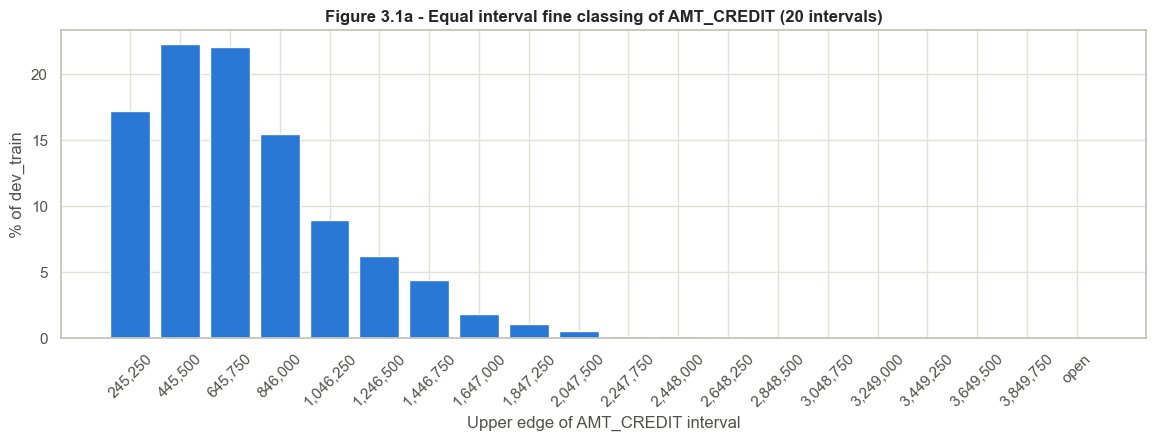

Intervals holding < 1% of dev_train: 11 of 20


In [49]:
credit = dev_train['AMT_CREDIT']
width_edges = np.linspace(credit.min(), credit.max(), 21)[1:-1]
equal_width = pd.cut(credit, bins=[-np.inf, *width_edges, np.inf])
width_counts = equal_width.value_counts(sort=False)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(width_counts)), width_counts.values / len(credit) * 100, color=BAR_COLOUR)
ax.set_xticks(range(len(width_counts)))
ax.set_xticklabels([f'{iv.right:,.0f}' if np.isfinite(iv.right) else 'open' for iv in width_counts.index], rotation=45)
ax.set_xlabel('Upper edge of AMT_CREDIT interval'); ax.set_ylabel('% of dev_train')
ax.set_title('Figure 3.1a - Equal interval fine classing of AMT_CREDIT (20 intervals)')
plt.show()
print(f'Intervals holding < 1% of dev_train: {(width_counts / len(credit) < 0.01).sum()} of {len(width_counts)}')

`AMT_CREDIT` is right-skewed, so most applicants fall in the first few equal-width intervals. More than half of the 20 intervals hold under 1% of dev_train, and the smallest is empty. WOE values for such sparse bins would be unstable or undefined.

### 3.1.2 Equal Frequency Binning

Equal frequency binning fixes the number of observations per bin and lets the widths vary (Module 10.2). `pd.qcut(q=20, duplicates='drop', retbins=True)` returns the edges used. Tied values can reduce the number of bins below 20, so the actual count is recorded.

In [50]:
freq_bins, freq_edges = pd.qcut(credit, q=20, duplicates='drop', retbins=True)
freq_counts = freq_bins.value_counts(sort=False)
print(f'Equal-frequency bins actually created for AMT_CREDIT: {len(freq_counts)} of 20 requested')

comparison = pd.DataFrame({
    'Equal interval': [len(width_counts), width_counts.min(), width_counts.max(), np.diff(width_edges).mean()],
    'Equal frequency': [len(freq_counts), freq_counts.min(), freq_counts.max(), np.diff(freq_edges[1:-1]).mean()],
}, index=['Bins', 'Smallest bin (rows)', 'Largest bin (rows)', 'Mean interior width'])
print('Table 3.1a - Equal interval vs equal frequency on AMT_CREDIT (dev_train)')
display(comparison.style.format('{:,.0f}'))

Equal-frequency bins actually created for AMT_CREDIT: 20 of 20 requested
Table 3.1a - Equal interval vs equal frequency on AMT_CREDIT (dev_train)


,Equal interval,Equal frequency
Bins,20,20
Smallest bin (rows),0,"2,637"
Largest bin (rows),"22,161","7,340"
Mean interior width,"200,250","67,500"


Equal frequency spreads dev_train evenly. Every bin holds thousands of applicants, with narrow bins where loans are common and wide bins in the sparse upper tail. Bin sizes are not identical because many loans share the same round amounts.

Equal frequency binning is used for every continuous candidate, because it gives each fine bin enough observations for a stable WOE. Discrete fields keep their observed values and categories keep their levels, with the special bins described in 3.1.

## 3.2 Calculate Weight of Evidence

Weight of Evidence measures how strongly an attribute separates goods from bads (Module 10.1):

$$WOE = \ln\left(\frac{\%\ \text{of non-events}}{\%\ \text{of events}}\right) = \ln\left(\frac{n_{good}/N_{good}}{n_{bad}/N_{bad}}\right)$$

`TARGET = 1` is the event (bad), so a **positive WOE means lower risk** than average and a negative WOE means higher risk.

A bin with no goods or no bads would give an infinite WOE, a problem the lab function did not handle. To avoid it, 0.5 is added to the good and bad counts of **every** bin, and each class total is increased by 0.5 × the number of bins so that the shares still sum to one. The observed counts and bad rates are reported unsmoothed alongside the WOE.

In [51]:
def woe_iv_table(data, order=None, smoothing=0.5):
    # lab-style binning table: data has a Bin_Range column and the TARGET column
    variable_data = data.groupby('Bin_Range', observed=True)[TARGET].agg(Count='count', Events='sum')
    if order is not None:
        variable_data = variable_data.reindex([b for b in order if b in variable_data.index])
    variable_data['Non_Events'] = variable_data['Count'] - variable_data['Events']
    variable_data['Bad_Rate'] = variable_data['Events'] / variable_data['Count']
    k = len(variable_data)
    variable_data['%_of_Events'] = (variable_data['Events'] + smoothing) / (variable_data['Events'].sum() + smoothing * k)
    variable_data['%_of_Non_Events'] = (variable_data['Non_Events'] + smoothing) / (variable_data['Non_Events'].sum() + smoothing * k)
    variable_data['WOE'] = np.log(variable_data['%_of_Non_Events'] / variable_data['%_of_Events'])
    variable_data['IV'] = (variable_data['%_of_Non_Events'] - variable_data['%_of_Events']) * variable_data['WOE']
    variable_data['total_IV'] = variable_data['IV'].sum()
    return variable_data

def woe_iv(df, var, spec):
    # bin one characteristic with its rule, then build the WOE / IV table
    woe_bin_data = pd.DataFrame({'Bin_Range': assign_bins(df, var, spec).values, TARGET: df[TARGET].values})
    return woe_iv_table(woe_bin_data, order=bin_order(spec))

ext_fine = woe_iv(dev_train, 'EXT_SOURCE_1', fine_specs['EXT_SOURCE_1'])
print('Table 3.2a - Fine-classed WOE for EXT_SOURCE_1 (dev_train)')
display(ext_fine.drop(columns=['IV', 'total_IV']).style.format({'Count': '{:,.0f}', 'Events': '{:,.0f}', 'Non_Events': '{:,.0f}',
                                                                  'Bad_Rate': '{:.2%}', '%_of_Events': '{:.4f}', '%_of_Non_Events': '{:.4f}', 'WOE': '{:.3f}'}))

Table 3.2a - Fine-classed WOE for EXT_SOURCE_1 (dev_train)


,Count,Events,Non_Events,Bad_Rate,%_of_Events,%_of_Non_Events,WOE
Bin_Range,,,,,,,
<= 0.181561,"2,124",402,"1,722",18.93%,0.0508,0.0187,-0.998
"(0.181561, 0.241325]","2,124",298,"1,826",14.03%,0.0377,0.0199,-0.640
"(0.241325, 0.287323]","2,122",249,"1,873",11.73%,0.0315,0.0204,-0.436
"(0.287323, 0.327845]","2,123",217,"1,906",10.22%,0.0275,0.0207,-0.281
"(0.327845, 0.365886]","2,123",189,"1,934",8.90%,0.0239,0.0211,-0.129
"(0.365886, 0.400595]","2,123",201,"1,922",9.47%,0.0255,0.0209,-0.196
"(0.400595, 0.434406]","2,123",170,"1,953",8.01%,0.0215,0.0213,-0.013
"(0.434406, 0.46719]","2,123",131,"1,992",6.17%,0.0166,0.0217,0.266
"(0.46719, 0.499831]","2,123",165,"1,958",7.77%,0.0209,0.0213,0.019


WOE rises from about -1.0 in the lowest-score bin (bad rate 18.9%) to above +1.1 in the highest bins (bad rates of 2-3%). Higher external scores therefore mean much lower risk. The trend is broadly one-directional, with small reversals between neighbouring bins that look like noise; coarse classing will smooth them out.

The `Missing` bin holds 57% of dev_train and has a WOE of -0.09: applicants without an external score are slightly riskier than average, so the missing value carries information of its own.

## 3.3 Calculate Information Value

Information Value sums the separation over all attributes of a characteristic (Module 10.2):

$$IV_{bin} = (\%\ \text{non-events} - \%\ \text{events}) \times WOE, \qquad IV_{characteristic} = \sum IV_{bin}$$

Worked example: the first bin of `EXT_SOURCE_1` from Table 3.2a.

In [52]:
first = ext_fine.iloc[0]
print(f"Bin {ext_fine.index[0]}: %non-events = {first['%_of_Non_Events']:.4f}, %events = {first['%_of_Events']:.4f}")
print(f"WOE    = ln({first['%_of_Non_Events']:.4f} / {first['%_of_Events']:.4f}) = {first['WOE']:.4f}")
print(f"IV_bin = ({first['%_of_Non_Events']:.4f} - {first['%_of_Events']:.4f}) x {first['WOE']:.4f} = {first['IV']:.4f}")
print(f"IV for EXT_SOURCE_1 (sum over {len(ext_fine)} bins) = {ext_fine['IV'].sum():.4f}")

Bin <= 0.181561: %non-events = 0.0187, %events = 0.0508
WOE    = ln(0.0187 / 0.0508) = -0.9979
IV_bin = (0.0187 - 0.0508) x -0.9979 = 0.0320
IV for EXT_SOURCE_1 (sum over 21 bins) = 0.1614


The same calculation is wrapped in the Session 10 lab's `woe_iv_plot` function: WOE by bin as a line, the `Missing` bin as a separate point, and the share of observations as bars.

IV for EXT_SOURCE_1 with 20 numeric bins: 0.1614


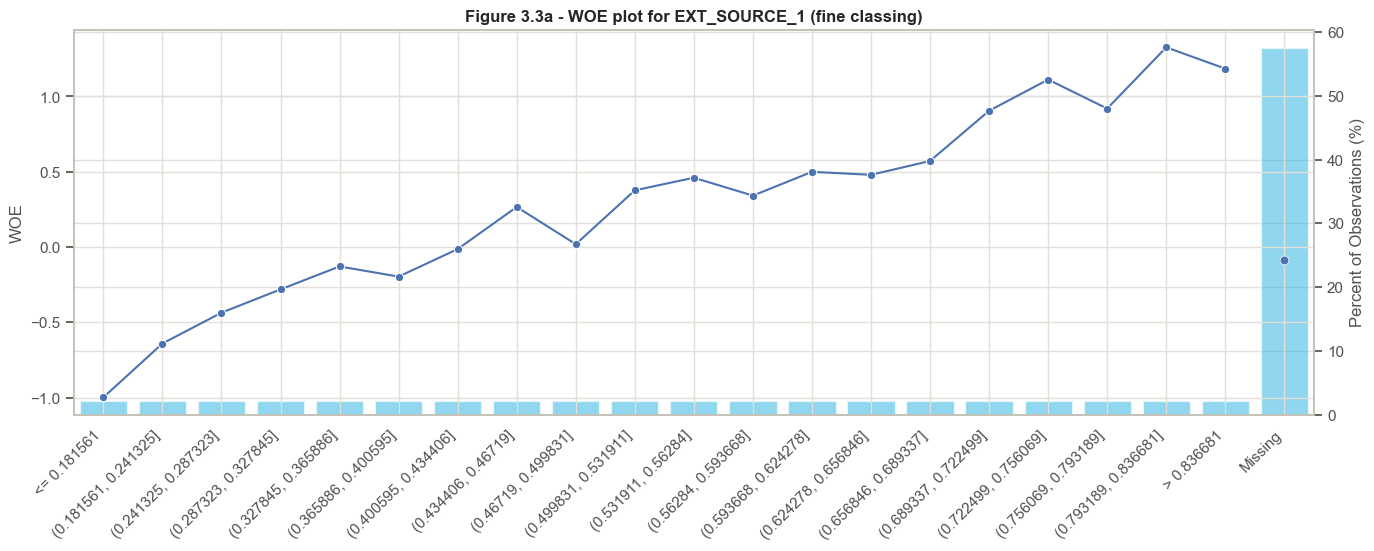

In [53]:
def woe_iv_plot(data, variable_name, order=None, title=None):
    # lab-style WOE plot: WOE line for value bins, special bins as points, % of observations as bars
    variable_data = woe_iv_table(data, order)
    special = [b for b in variable_data.index if b in (MISSING, NO_HISTORY, UNSEEN)]
    numeric = [b for b in variable_data.index if b not in special]
    print('IV for', variable_name, 'with', len(numeric), 'numeric bins:', round(variable_data['IV'].sum(), 4))

    fig, ax1 = plt.subplots(figsize=(16, 5))
    sns.lineplot(x=range(len(numeric)), y=variable_data.loc[numeric, 'WOE'].values, marker='o', ax=ax1)
    if special:
        sns.scatterplot(x=range(len(numeric), len(variable_data)), y=variable_data.loc[special, 'WOE'].values, color='b', s=40, ax=ax1)
    ax1.set_ylabel('WOE')

    ax2 = ax1.twinx()
    variable_data['Percent'] = variable_data['Count'] / variable_data['Count'].sum() * 100
    sns.barplot(x=variable_data.index.astype(str), y=variable_data['Percent'].values, alpha=0.5, ax=ax2, color='deepskyblue')
    ax2.set_ylabel('Percent of Observations (%)')
    ax1.set_xticks(range(len(variable_data)))
    ax1.set_xticklabels(variable_data.index.astype(str), rotation=45, ha='right')
    ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)   # keep the WOE line in front of the bars
    plt.title(title or 'WOE plot for ' + variable_name)
    plt.show()

# fine-classed EXT_SOURCE_1, prepared the same way as in the lab
variable = 'EXT_SOURCE_1'
woe_bin_data = dev_train[[variable, TARGET]].copy()
woe_bin_data['Bin_Range'] = assign_bins(dev_train, variable, fine_specs[variable])
woe_iv_plot(woe_bin_data, variable, order=bin_order(fine_specs[variable]), title='Figure 3.3a - WOE plot for EXT_SOURCE_1 (fine classing)')

With an IV of about 0.16, `EXT_SOURCE_1` has medium predictive power. Almost all of its IV comes from the value bins at the two ends of the score range.

## 3.4 Characteristic Screening

Every candidate characteristic is ranked by its fine-classed IV on dev_train and labelled with the class bands (Module 10.2): below 0.02 not useful, 0.02-0.1 weak, 0.1-0.3 medium, 0.3-0.5 strong. Above 0.5 is potentially over-predictive and has to be investigated for leakage, not treated as excellent.

In [54]:
def iv_band(iv):
    for upper, name in IV_BANDS:
        if iv < upper:
            return name

fine_tables = {var: woe_iv(dev_train, var, spec) for var, spec in fine_specs.items()}
iv_table = pd.DataFrame({'IV': {v: t['IV'].sum() for v, t in fine_tables.items()},
                         'Fine bins': {v: len(t) for v, t in fine_tables.items()},
                         'Type': spec_types}).sort_values('IV', ascending=False)
iv_table['Band'] = iv_table['IV'].apply(iv_band)
iv_table['Rank'] = range(1, len(iv_table) + 1)

print('Table 3.4a - Number of candidates by IV band (dev_train, fine classing)')
display(iv_table['Band'].value_counts().reindex([b for _, b in IV_BANDS]).fillna(0).astype(int).to_frame('Characteristics'))

Table 3.4a - Number of candidates by IV band (dev_train, fine classing)


,Characteristics
Band,
Not useful,63
Weak,63
Medium,3
Strong,0
Potentially over-predictive,0


Predictive power is modest across the board. Only three characteristics reach the medium band and none exceed 0.3, so no characteristic looks suspiciously over-predictive or leaky. About half of the candidates are weak and the other half not useful. A scorecard built from many weak-to-medium characteristics is typical for application data.

In [55]:
building_set = set(building_cols)
def eligibility_note(var):
    if var in building_set:
        return 'Building field (AVG/MODE/MEDI family)'
    if var == 'no_bureau_history':
        return 'Duplicates the No bureau history bin of BUR_ fields'
    if var == 'employment_not_recorded':
        return 'Duplicates the Missing bin of employment_years'
    if var.startswith('AMT_REQ_'):
        return 'Bureau enquiry count; missing only without bureau history'
    return ''

top15 = iv_table.head(TOP_N_IV).copy()
top15['Note'] = [eligibility_note(v) for v in top15.index]
print(f'Table 3.4b - Top {TOP_N_IV} characteristics by Information Value (dev_train)')
display(top15[['Rank', 'IV', 'Band', 'Type', 'Fine bins', 'Note']].style.format({'IV': '{:.4f}'}))

Table 3.4b - Top 15 characteristics by Information Value (dev_train)


,Rank,IV,Band,Type,Fine bins,Note
EXT_SOURCE_1,1,0.1614,Medium,continuous,21,
employment_years,2,0.1103,Medium,continuous,21,
AMT_GOODS_PRICE,3,0.1058,Medium,continuous,20,
BUR_debt_to_credit,4,0.0983,Weak,continuous,17,
BUR_days_since_recent_credit,5,0.0818,Weak,continuous,21,
OCCUPATION_TYPE,6,0.0784,Weak,categorical,19,
age_years,7,0.0699,Weak,continuous,20,
ORGANIZATION_TYPE,8,0.0699,Weak,categorical,58,
NAME_EDUCATION_TYPE,9,0.0507,Weak,categorical,5,
DAYS_LAST_PHONE_CHANGE,10,0.0504,Weak,continuous,18,


The top 15 contain overlapping fields. `AMT_GOODS_PRICE`, `AMT_CREDIT` and `AMT_ANNUITY` all measure loan size, the two region ratings are near copies, and `BUR_debt_sum` overlaps with `BUR_debt_to_credit`. Ranking by IV alone would therefore spend scorecard slots on the same information several times.

**Shortlist for coarse classing.** The top 15 are not adopted automatically. The shortlist is built with rules that are fixed in advance and use dev_train only:

1. Keep characteristics with IV of at least 0.02.
2. **Redundancy:** for any pair of numeric candidates with Spearman |r| > 0.8 on dev_train, keep the one with the higher IV (Session 09 lab rule).
3. **Duplicated information:** keep at most one building field, because the 47 fields describe the same building. Drop `no_bureau_history` and `employment_not_recorded` when the characteristic they duplicate is kept.
4. Take the 14 highest-IV survivors, which leaves room to reach a scorecard of 8-15 characteristics after coarse classing and model fitting.

Fairness exclusions were applied before screening (2.8), so they are never traded off against IV.

In [56]:
eligible = iv_table[iv_table['IV'] >= 0.02].index.tolist()
numeric_eligible = [v for v in eligible if spec_types[v] != 'categorical']
spearman = dev_train[numeric_eligible].corr(method='spearman')

dropped = {}
pairs = spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1)).stack()
for (a, b), r in pairs.reindex(pairs.abs().sort_values(ascending=False).index).items():
    if abs(r) > 0.8 and a not in dropped and b not in dropped:
        weaker, stronger = (a, b) if iv_table.loc[a, 'IV'] < iv_table.loc[b, 'IV'] else (b, a)
        dropped[weaker] = f'|r| = {abs(r):.2f} with {stronger}'

survivors = [v for v in eligible if v not in dropped]
kept_building = [v for v in survivors if v in building_set][:1]
for v in survivors:
    if v in building_set and v not in kept_building:
        dropped[v] = f'Building family represented by {kept_building[0]}'
survivors = [v for v in survivors if v not in dropped]
if any(v.startswith('BUR_') for v in survivors) and 'no_bureau_history' in survivors:
    dropped['no_bureau_history'] = 'Information kept as a bin of the BUR_ characteristics'
if 'employment_years' in survivors and 'employment_not_recorded' in survivors:
    dropped['employment_not_recorded'] = 'Information kept as the Missing bin of employment_years'
survivors = [v for v in survivors if v not in dropped]

shortlist = survivors[:14]
print(f'Eligible (IV >= 0.02): {len(eligible)} | removed by rules: {len(dropped)} | shortlist: {len(shortlist)}')
print('Table 3.4c - Removed by the redundancy rules')
display(pd.Series(dropped, name='Reason').to_frame().join(iv_table['IV']).sort_values('IV', ascending=False).style.format({'IV': '{:.4f}'}))
print('Table 3.4d - Shortlist for coarse classing')
display(iv_table.loc[shortlist, ['IV', 'Band', 'Type']].style.format({'IV': '{:.4f}'}))

Eligible (IV >= 0.02): 66 | removed by rules: 41 | shortlist: 14
Table 3.4c - Removed by the redundancy rules


,Reason,IV
AMT_CREDIT,|r| = 0.98 with AMT_GOODS_PRICE,0.0499
BUR_debt_sum,|r| = 0.82 with BUR_debt_to_credit,0.0499
REGION_RATING_CLIENT,|r| = 0.95 with REGION_RATING_CLIENT_W_CITY,0.0435
AMT_ANNUITY,|r| = 0.83 with AMT_GOODS_PRICE,0.0417
FLOORSMAX_MODE,|r| = 0.99 with FLOORSMAX_MEDI,0.0397
FLOORSMAX_AVG,|r| = 1.00 with FLOORSMAX_MEDI,0.0396
LIVINGAREA_MEDI,Building family represented by FLOORSMAX_MEDI,0.0374
TOTALAREA_MODE,|r| = 0.93 with LIVINGAREA_MEDI,0.0372
LIVINGAREA_AVG,|r| = 1.00 with LIVINGAREA_MEDI,0.0367
APARTMENTS_MODE,|r| = 0.87 with LIVINGAREA_MEDI,0.0366


Table 3.4d - Shortlist for coarse classing


,IV,Band,Type
EXT_SOURCE_1,0.1614,Medium,continuous
employment_years,0.1103,Medium,continuous
AMT_GOODS_PRICE,0.1058,Medium,continuous
BUR_debt_to_credit,0.0983,Weak,continuous
BUR_days_since_recent_credit,0.0818,Weak,continuous
OCCUPATION_TYPE,0.0784,Weak,categorical
age_years,0.0699,Weak,continuous
ORGANIZATION_TYPE,0.0699,Weak,categorical
NAME_EDUCATION_TYPE,0.0507,Weak,categorical
DAYS_LAST_PHONE_CHANGE,0.0504,Weak,continuous


The redundancy rules remove 41 of the 66 eligible characteristics. Most are building fields: the AVG, MODE and MEDI versions of the same measurement, represented in the shortlist by `FLOORSMAX_MEDI`. `employment_not_recorded` turns out to be identical to `FLAG_EMP_PHONE` (no employer phone without an employer). Its information also stays in the `Missing` bin of `employment_years`.

The 14 shortlisted characteristics cover:
- the external score;
- employment length and type;
- loan size;
- bureau leverage and recency;
- age and education;
- region;
- building;
- stability signals (how recently the phone number and identity document changed).

`NAME_INCOME_TYPE`, `NAME_FAMILY_STATUS` and `CODE_GENDER` were excluded by policy before screening and are not shown here.

## 3.5 Coarse Classing

Coarse classing merges fine bins into a few attributes that have enough observations, distinct WOE and a logical trend, which reduces overfitting (Module 10.3). The merging rules are applied the same way to every shortlisted characteristic.

**Numeric characteristics.** Adjacent fine bins are merged in three passes:
1. bins below 5% of dev_train are merged into the neighbour with the closer WOE;
2. if WOE does not move in one direction, the most out-of-line adjacent pair is merged, following the overall direction of the trend in the fine bins (the direction is not assumed in advance);
3. bins are merged until at most 6 attributes remain.

Edges are then rounded to readable values and the passes are repeated.

**Categorical characteristics.** Levels are ordered by WOE. Groups below 5% are merged with the neighbouring group of closest WOE, and merging continues until at most 6 groups remain. Unordered categories are not forced into a numeric trend.

`Missing` and `No bureau history` stay as separate attributes. They are never merged into a value bin without evidence.

In [57]:
def main_table(train, var, spec):
    # WOE table restricted to the value bins (special bins excluded)
    table = woe_iv(train, var, spec)
    return table.loc[[b for b in table.index if b not in (MISSING, NO_HISTORY, UNSEEN)]]

def round_edges(edges):
    # smallest number of significant figures that keeps the edges strictly increasing
    for sig in range(2, 7):
        rounded = [float(f'{e:.{sig}g}') for e in edges]
        if all(b > a for a, b in zip(rounded[:-1], rounded[1:])):
            return rounded
    return list(edges)

def merge_numeric(train, var, spec, min_share, max_bins, monotonic=True):
    edges, n = list(spec['edges']), len(train)
    table = lambda e: main_table(train, var, {**spec, 'edges': e})
    while edges:                                   # 1. thin bins
        t = table(edges); share = (t['Count'] / n).values
        if share.min() >= min_share:
            break
        i, w = int(share.argmin()), t['WOE'].values
        j = 0 if i == 0 else i - 1 if i == len(t) - 1 else (i - 1 if abs(w[i] - w[i - 1]) <= abs(w[i] - w[i + 1]) else i)
        edges.pop(j)
    if monotonic and len(edges) > 0:               # 2. one-directional WOE
        w = table(edges)['WOE'].values
        direction = np.sign(np.corrcoef(np.arange(len(w)), w)[0, 1]) or 1
        while edges:
            diffs = np.diff(table(edges)['WOE'].values) * direction
            if (diffs > 0).all():
                break
            edges.pop(int(diffs.argmin()))
    while len(edges) + 1 > max_bins:               # 3. number of attributes
        edges.pop(int(np.abs(np.diff(table(edges)['WOE'].values)).argmin()))
    return {**spec, 'edges': edges}

def coarse_numeric(train, var, spec, min_share=MIN_BIN_SHARE, max_bins=6, monotonic=True):
    coarse = merge_numeric(train, var, spec, min_share, max_bins, monotonic)
    if not coarse.get('discrete') and coarse['edges']:
        coarse = merge_numeric(train, var, {**coarse, 'edges': round_edges(coarse['edges'])}, min_share, max_bins, monotonic)
    return coarse

def group_name(levels):
    names = [str(x) for x in levels]
    return ', '.join(names[:3]) + (f' +{len(names) - 3} more' if len(names) > 3 else '')

def coarse_categorical(train, var, spec, min_share=MIN_BIN_SHARE, max_groups=6):
    n = len(train)
    groups = [[lvl for lvl, g in spec['groups'].items() if g == label] for label in dict.fromkeys(spec['groups'].values())]
    while len(groups) > 1:
        gspec = {'type': 'categorical', 'groups': {lvl: group_name(g) for g in groups for lvl in g}}
        t = main_table(train, var, gspec).sort_values('WOE')
        groups = [[lvl for lvl in gspec['groups'] if gspec['groups'][lvl] == label] for label in t.index]
        share, w = (t['Count'] / n).values, t['WOE'].values
        if len(groups) > 2 and share.min() < min_share:
            i = int(share.argmin())
            j = 0 if i == 0 else i - 1 if i == len(groups) - 1 else (i - 1 if abs(w[i] - w[i - 1]) <= abs(w[i] - w[i + 1]) else i)
        elif len(groups) > max_groups:
            j = int(np.abs(np.diff(w)).argmin())
        else:
            break
        groups[j:j + 2] = [groups[j] + groups[j + 1]]
    return {'type': 'categorical', 'groups': {lvl: group_name(g) for g in groups for lvl in g}}

coarse_specs = {}
for var in shortlist:
    spec = fine_specs[var]
    coarse_specs[var] = coarse_categorical(dev_train, var, spec) if spec['type'] == 'categorical' else coarse_numeric(dev_train, var, spec)

coarse_tables = {var: woe_iv(dev_train, var, spec) for var, spec in coarse_specs.items()}
print('Attributes after coarse classing (including special bins):', {v: len(t) for v, t in coarse_tables.items()})

Attributes after coarse classing (including special bins): {'EXT_SOURCE_1': 5, 'employment_years': 7, 'AMT_GOODS_PRICE': 5, 'BUR_debt_to_credit': 8, 'BUR_days_since_recent_credit': 7, 'OCCUPATION_TYPE': 7, 'age_years': 6, 'ORGANIZATION_TYPE': 6, 'NAME_EDUCATION_TYPE': 2, 'DAYS_LAST_PHONE_CHANGE': 6, 'REGION_RATING_CLIENT_W_CITY': 3, 'REGION_POPULATION_RELATIVE': 5, 'FLOORSMAX_MEDI': 4, 'DAYS_ID_PUBLISH': 6}


The edges found for `EXT_SOURCE_1` can be applied in the same way as the lab's `bin_edges` and `pd.cut`. Missing values become their own bin.

Coarse bin edges: [-inf, 0.43, 0.59, 0.69, inf]
IV for EXT_SOURCE_1 with 4 numeric bins: 0.1387


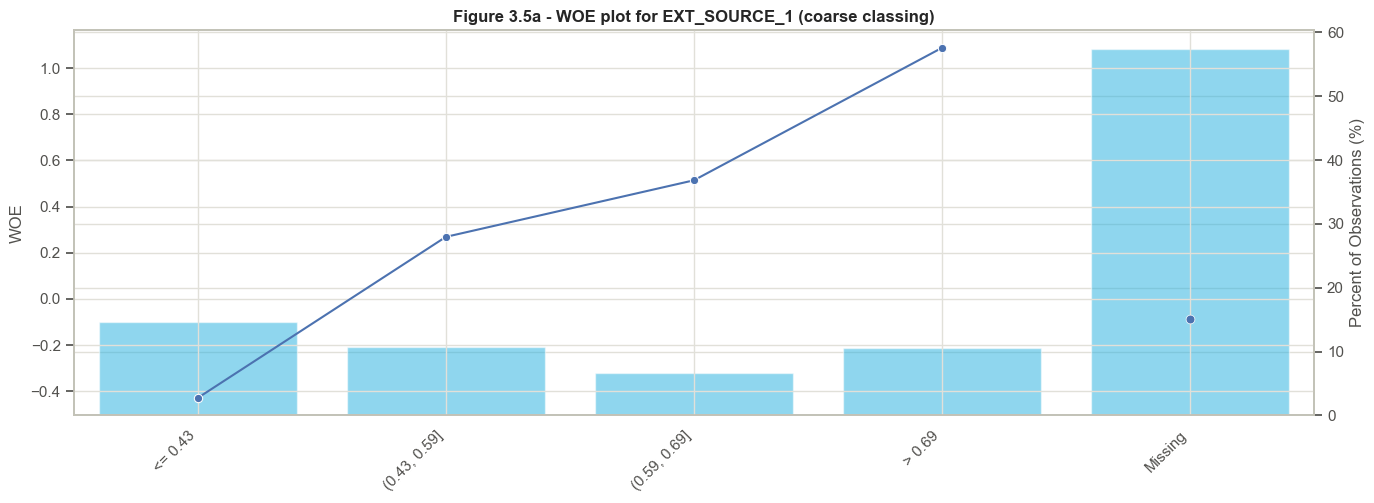

In [58]:
bin_edges = [-np.inf, *coarse_specs['EXT_SOURCE_1']['edges'], np.inf]
variable = 'EXT_SOURCE_1'
print('Coarse bin edges:', bin_edges)

# create groupings based on the coarse bin edges (right-inclusive, open outer bins)
woe_bin_data = dev_train[[variable, TARGET]].copy()
woe_bin_data['Bin_Range'] = pd.cut(dev_train[variable], bins=bin_edges, labels=bin_labels(coarse_specs[variable])).astype(object)
woe_bin_data['Bin_Range'] = woe_bin_data['Bin_Range'].fillna(MISSING)

woe_iv_plot(woe_bin_data, variable, order=bin_order(coarse_specs[variable]), title='Figure 3.5a - WOE plot for EXT_SOURCE_1 (coarse classing)')

## 3.6 Assess Bin Counts WOE Differentiation and Monotonicity

For each shortlisted characteristic, check the share of dev_train in each attribute, the goods and bads behind each WOE, and whether the trend is logical (Module 10.3).

In [59]:
rows = []
for var, t in coarse_tables.items():
    for b, r in t.iterrows():
        rows.append({'Characteristic': var, 'Attribute': b, 'Share %': r['Count'] / len(dev_train) * 100,
                     'Goods': int(r['Non_Events']), 'Bads': int(r['Events']), 'Bad rate %': r['Bad_Rate'] * 100, 'WOE': r['WOE'],
                     'Below 5%': 'yes' if r['Count'] / len(dev_train) < MIN_BIN_SHARE else ''})
coarse_detail = pd.DataFrame(rows).set_index(['Characteristic', 'Attribute'])
print('Table 3.6a - Coarse-classed attributes (dev_train)')
display(coarse_detail.style.format({'Share %': '{:.1f}', 'Goods': '{:,}', 'Bads': '{:,}', 'Bad rate %': '{:.2f}', 'WOE': '{:.3f}'}))

Table 3.6a - Coarse-classed attributes (dev_train)


In [60]:
def is_monotonic(var):
    w = main_table(dev_train, var, coarse_specs[var])['WOE'].values
    return len(w) < 3 or (np.diff(w) > 0).all() or (np.diff(w) < 0).all()

trend = pd.DataFrame({'Type': [spec_types[v] for v in shortlist],
                      'Value attributes': [len(main_table(dev_train, v, coarse_specs[v])) for v in shortlist],
                      'Monotonic WOE (numeric only)': ['n/a (unordered)' if spec_types[v] == 'categorical' else ('yes' if is_monotonic(v) else 'no') for v in shortlist],
                      'Min WOE gap between adjacent value bins': [np.abs(np.diff(main_table(dev_train, v, coarse_specs[v])['WOE'].values)).min()
                                                                   if len(main_table(dev_train, v, coarse_specs[v])) > 1 else np.nan for v in shortlist]},
                     index=shortlist)
print('Table 3.6b - Trend and differentiation checks')
display(trend.style.format({'Min WOE gap between adjacent value bins': '{:.3f}'}))

Table 3.6b - Trend and differentiation checks


,Type,Value attributes,Monotonic WOE (numeric only),Min WOE gap between adjacent value bins
EXT_SOURCE_1,continuous,4,yes,0.245
employment_years,continuous,6,yes,0.113
AMT_GOODS_PRICE,continuous,4,yes,0.107
BUR_debt_to_credit,continuous,6,yes,0.109
BUR_days_since_recent_credit,continuous,6,yes,0.059
OCCUPATION_TYPE,categorical,6,n/a (unordered),0.045
age_years,continuous,6,yes,0.108
ORGANIZATION_TYPE,categorical,6,n/a (unordered),0.101
NAME_EDUCATION_TYPE,categorical,2,n/a (unordered),0.557
DAYS_LAST_PHONE_CHANGE,continuous,6,yes,0.090


IV for EXT_SOURCE_1 with 4 numeric bins: 0.1387


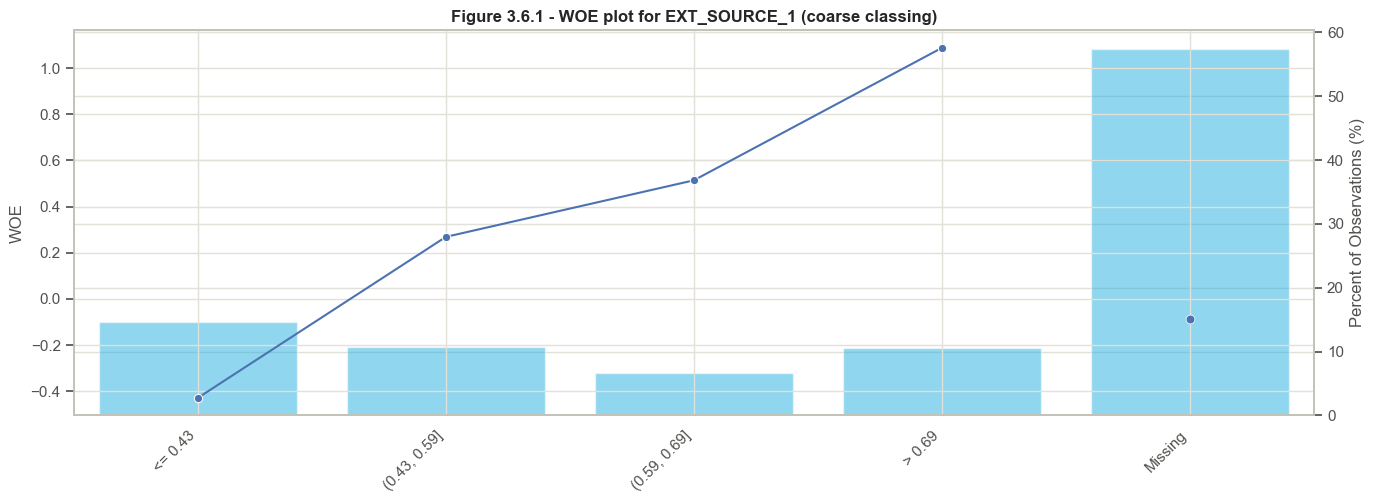

IV for employment_years with 6 numeric bins: 0.1084


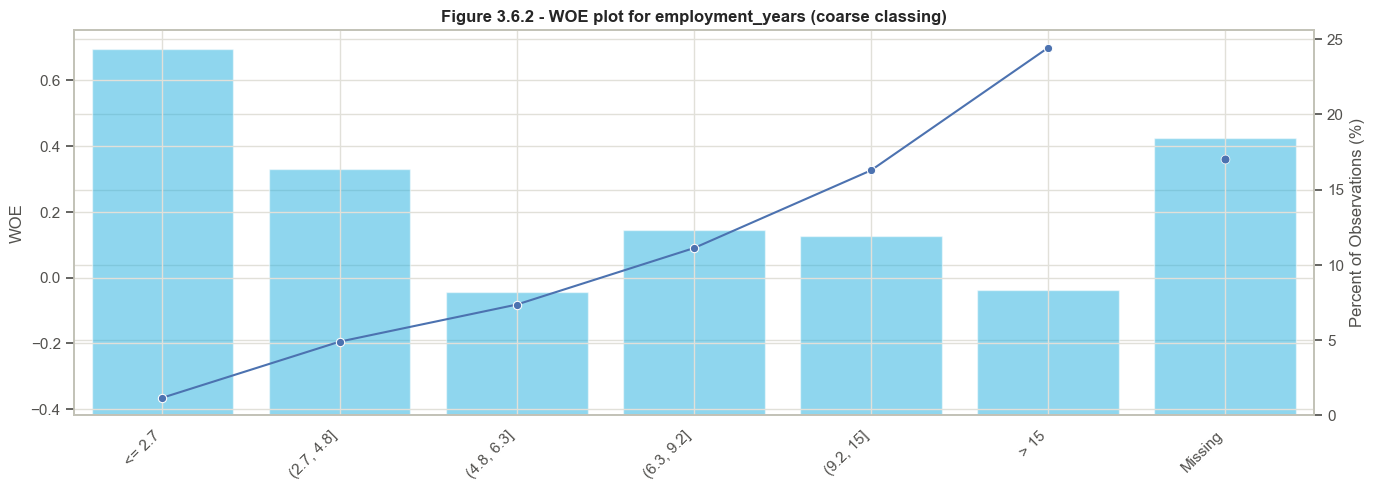

IV for AMT_GOODS_PRICE with 4 numeric bins: 0.0464


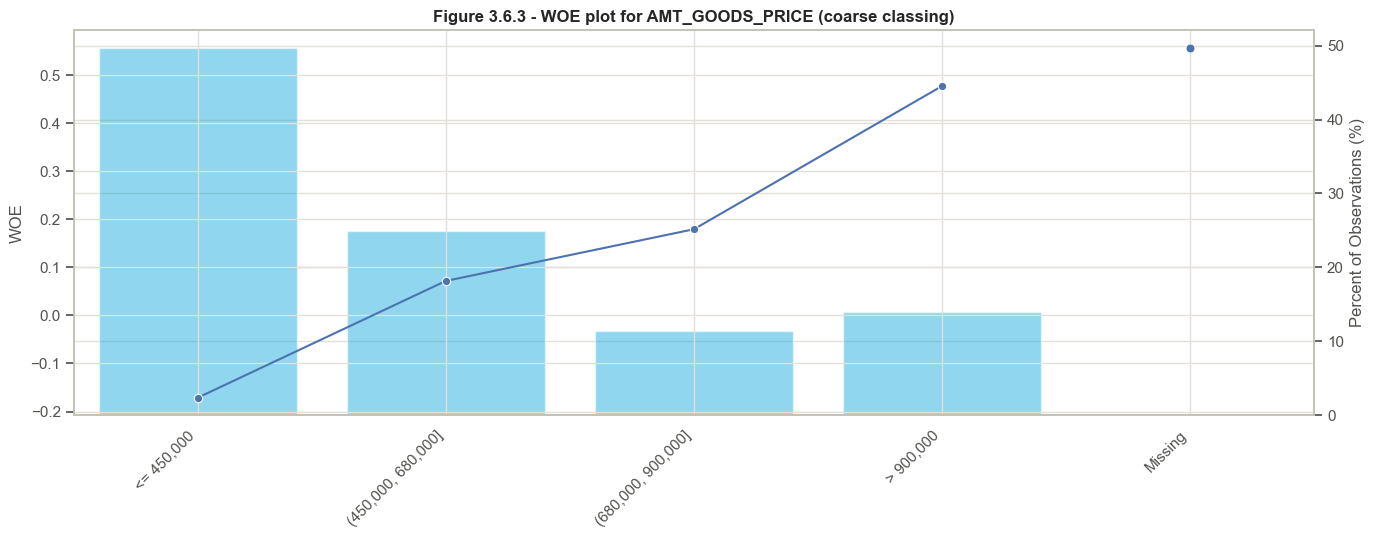

IV for BUR_debt_to_credit with 6 numeric bins: 0.0938


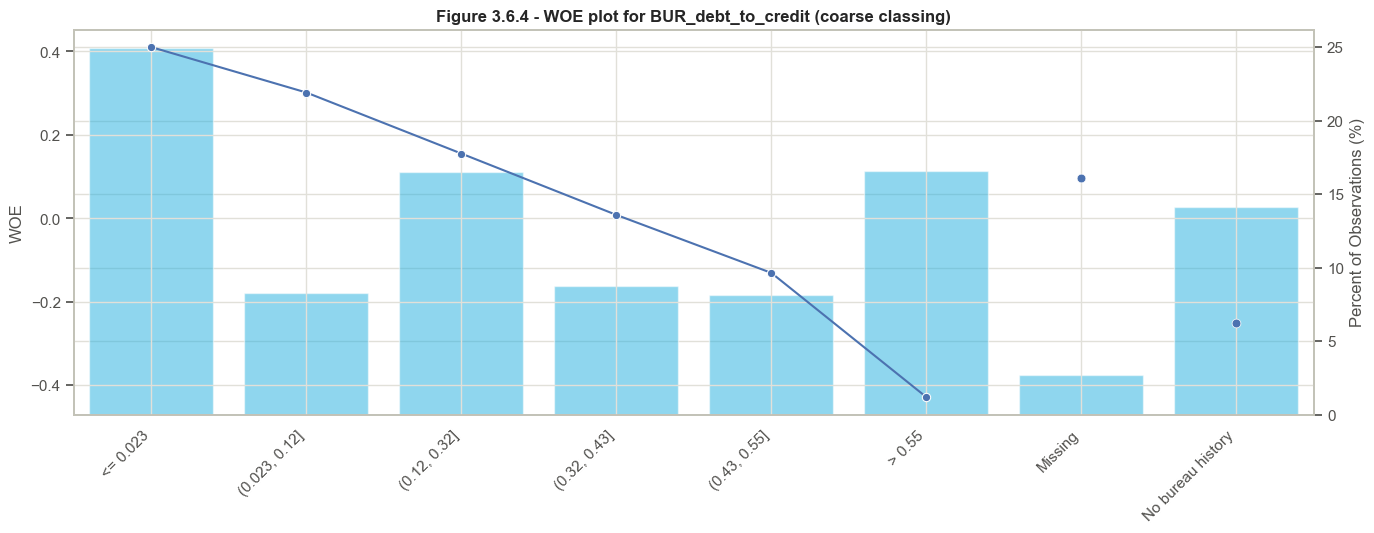

IV for BUR_days_since_recent_credit with 6 numeric bins: 0.0765


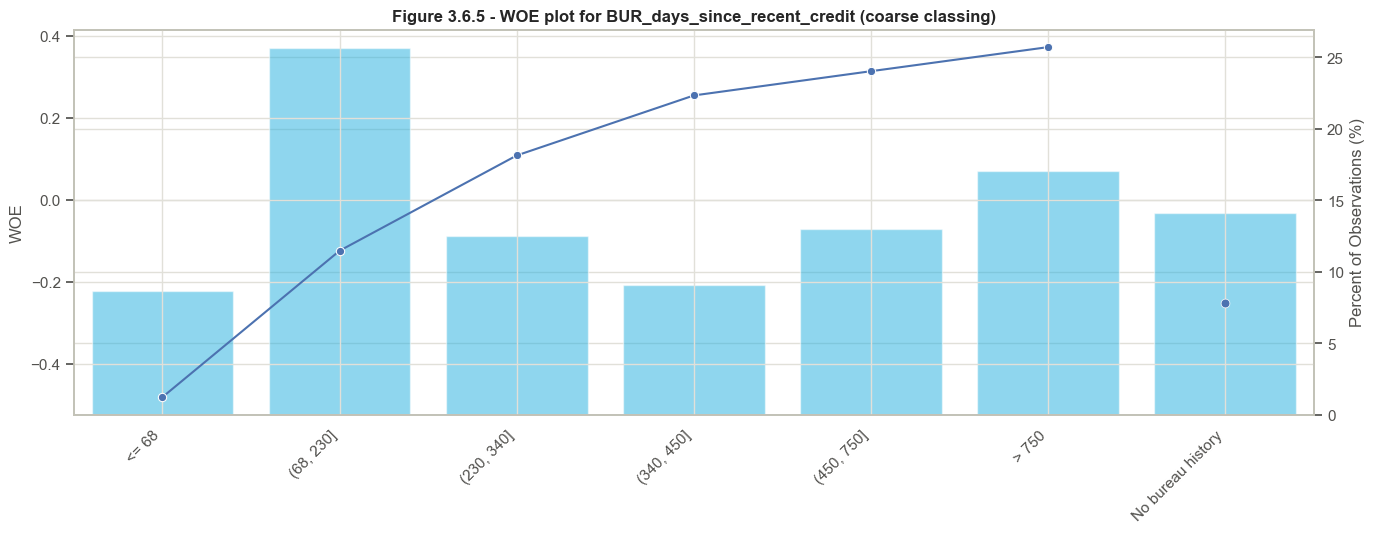

IV for OCCUPATION_TYPE with 6 numeric bins: 0.0752


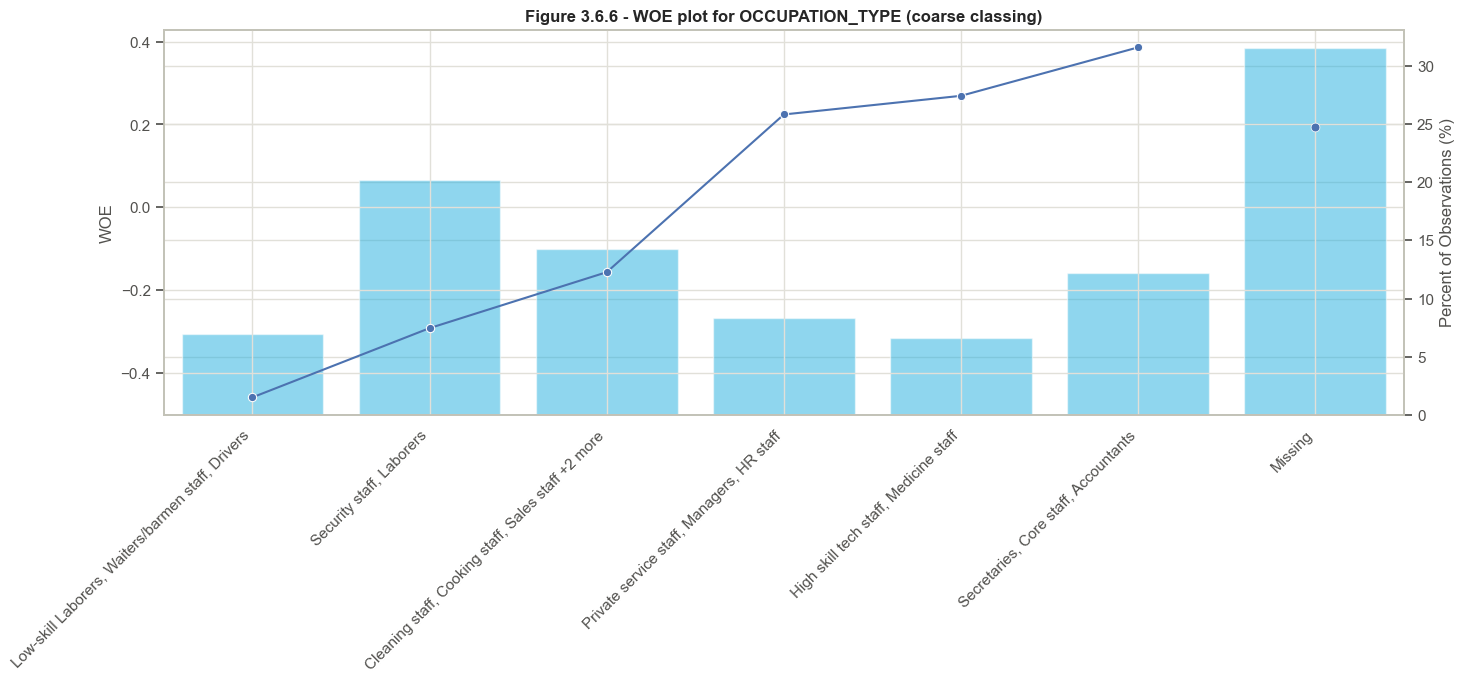

IV for age_years with 6 numeric bins: 0.0681


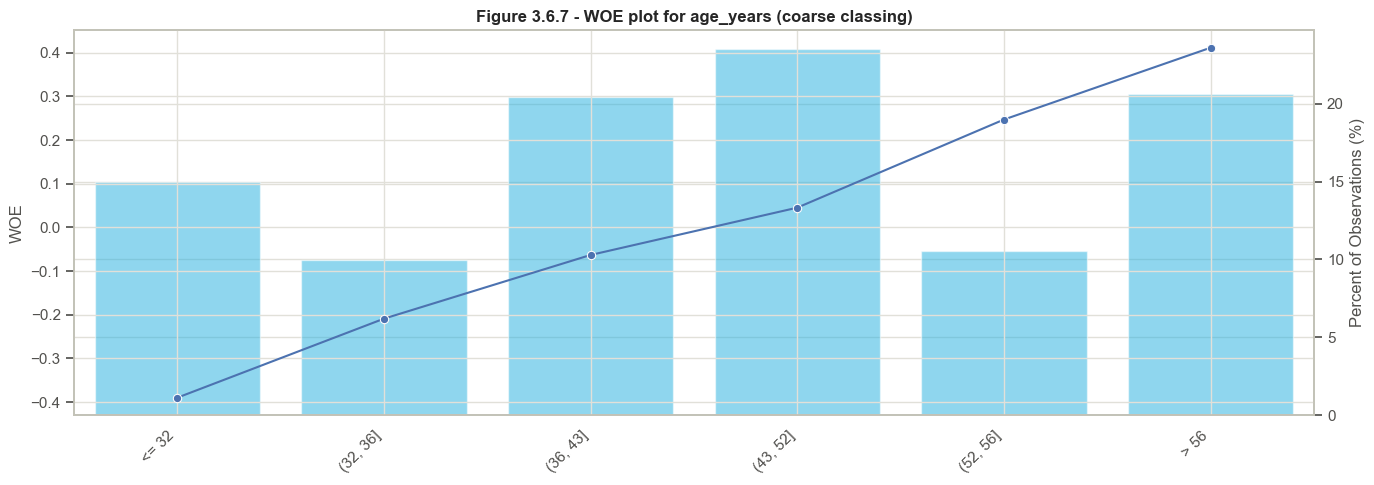

IV for ORGANIZATION_TYPE with 6 numeric bins: 0.0661


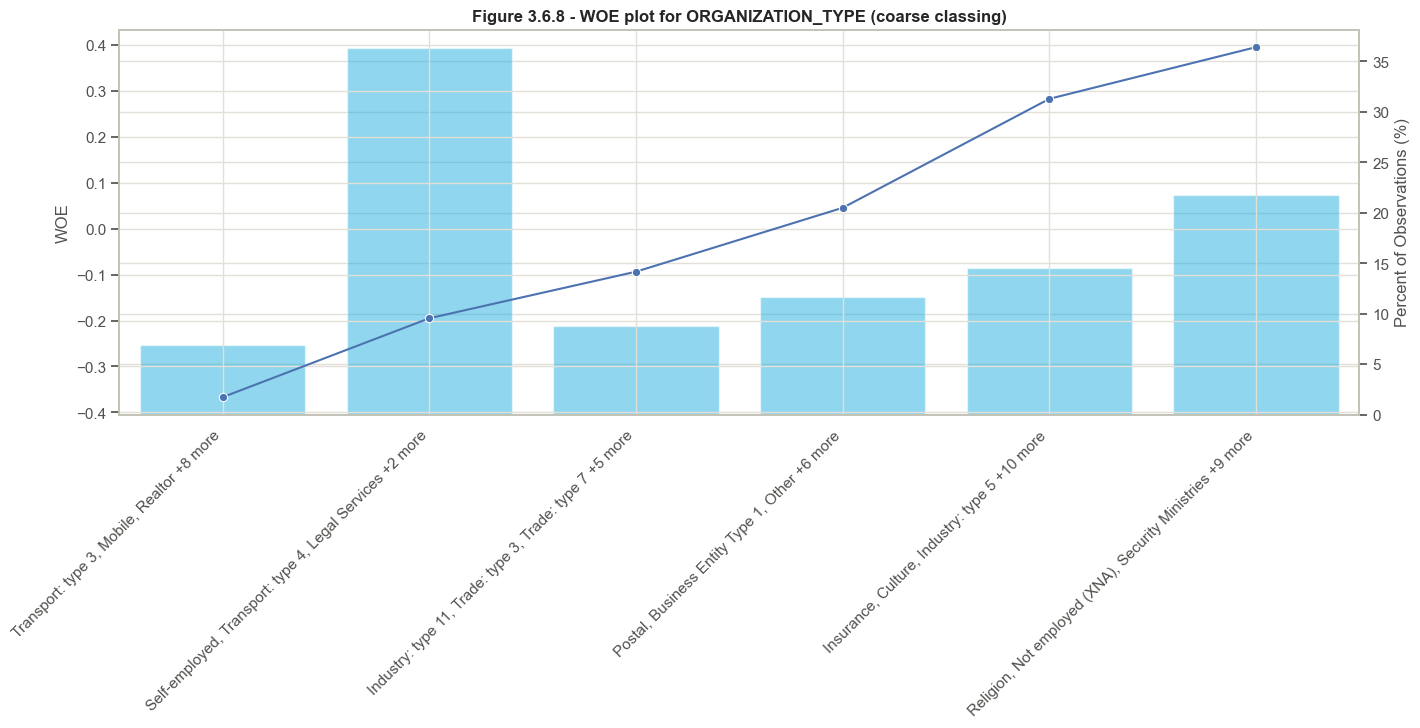

IV for NAME_EDUCATION_TYPE with 2 numeric bins: 0.0499


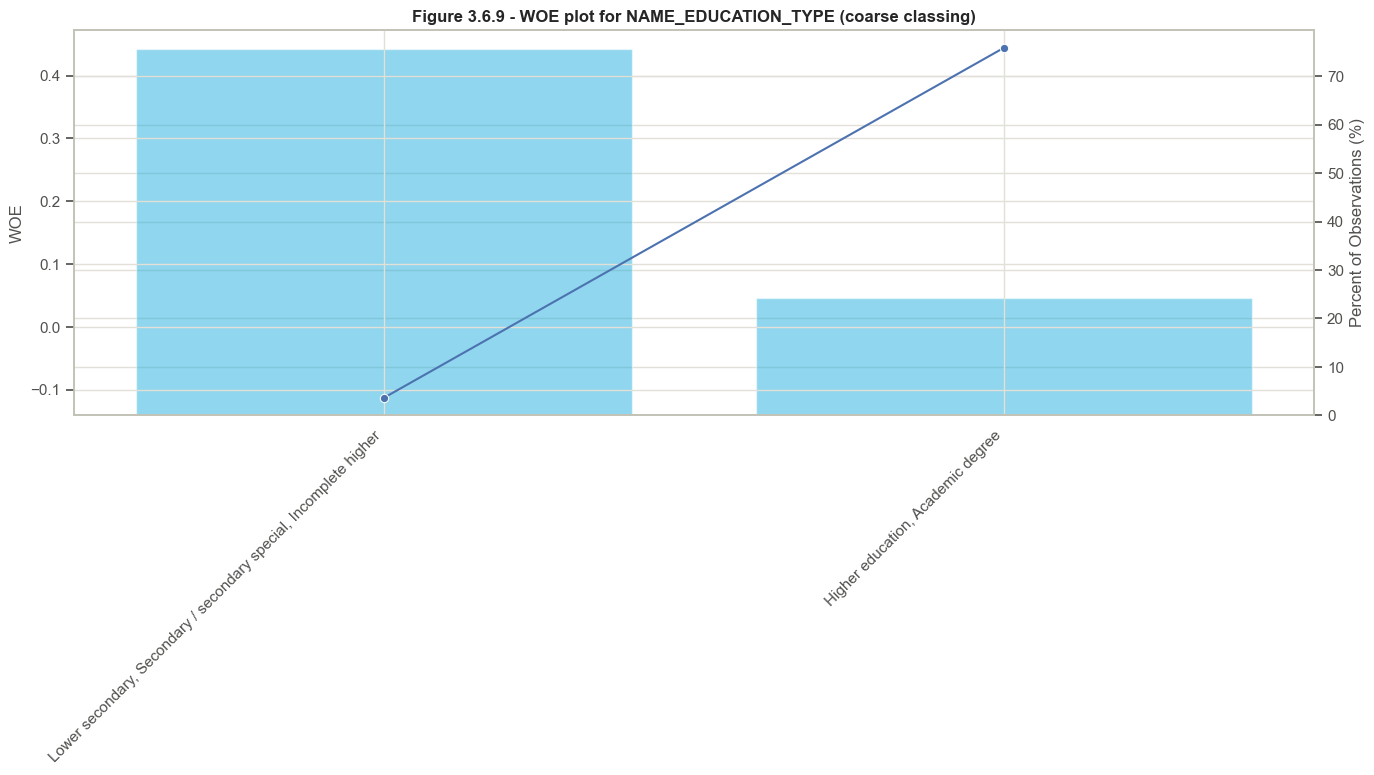

IV for DAYS_LAST_PHONE_CHANGE with 6 numeric bins: 0.049


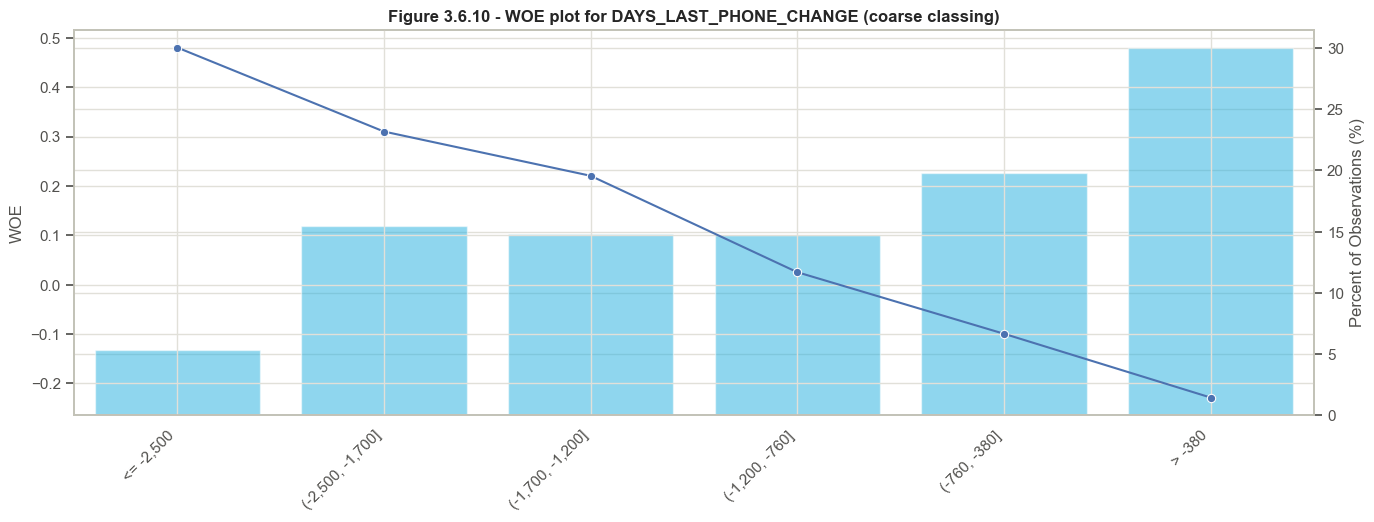

IV for REGION_RATING_CLIENT_W_CITY with 3 numeric bins: 0.0483


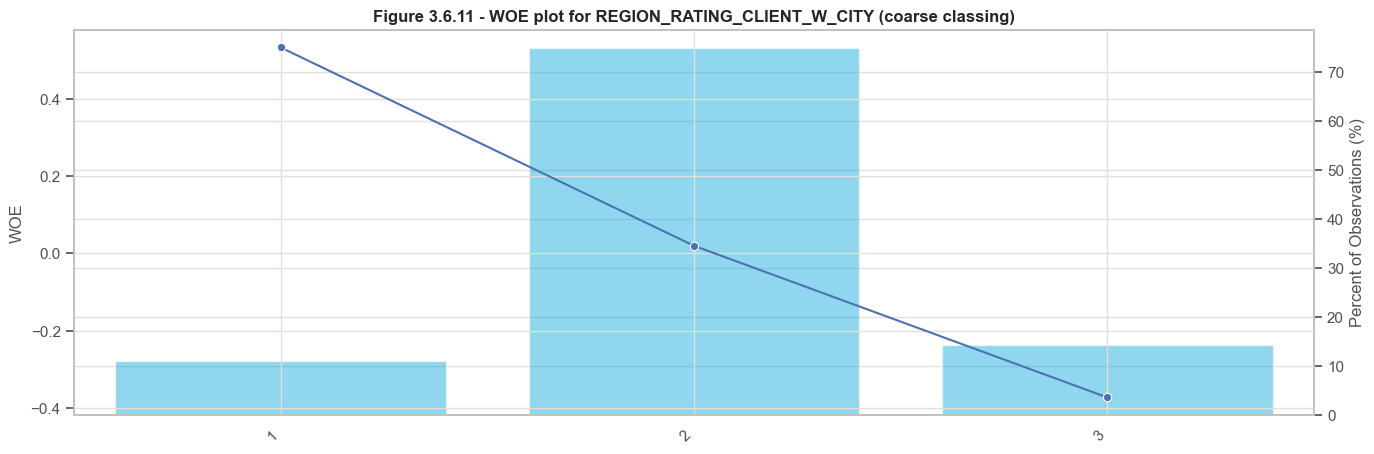

IV for REGION_POPULATION_RELATIVE with 5 numeric bins: 0.0288


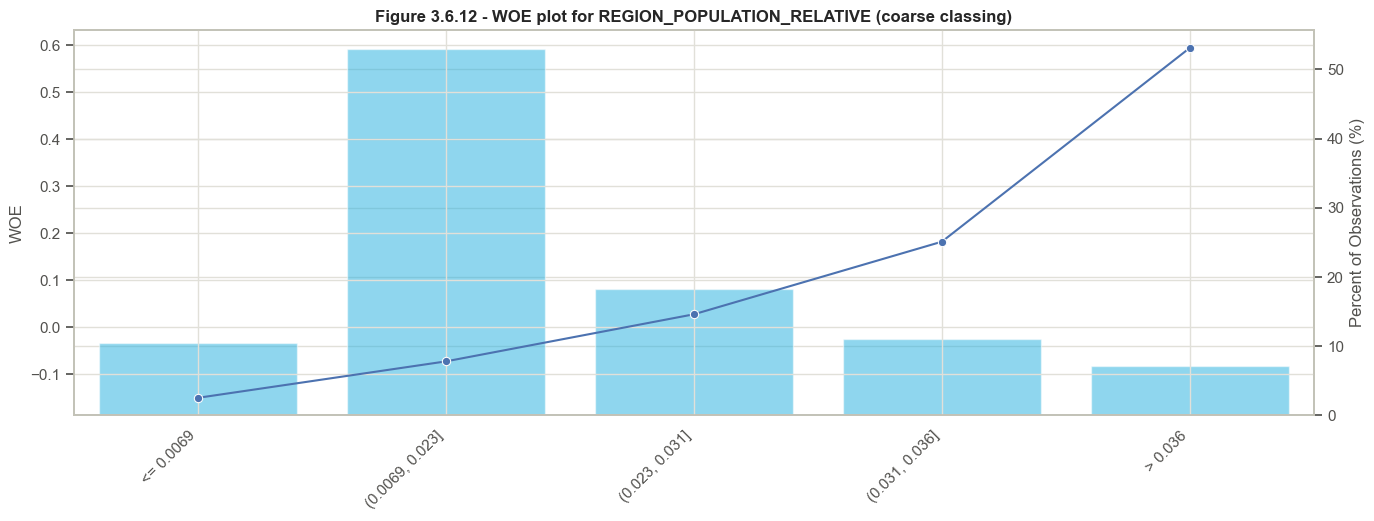

IV for FLOORSMAX_MEDI with 3 numeric bins: 0.0358


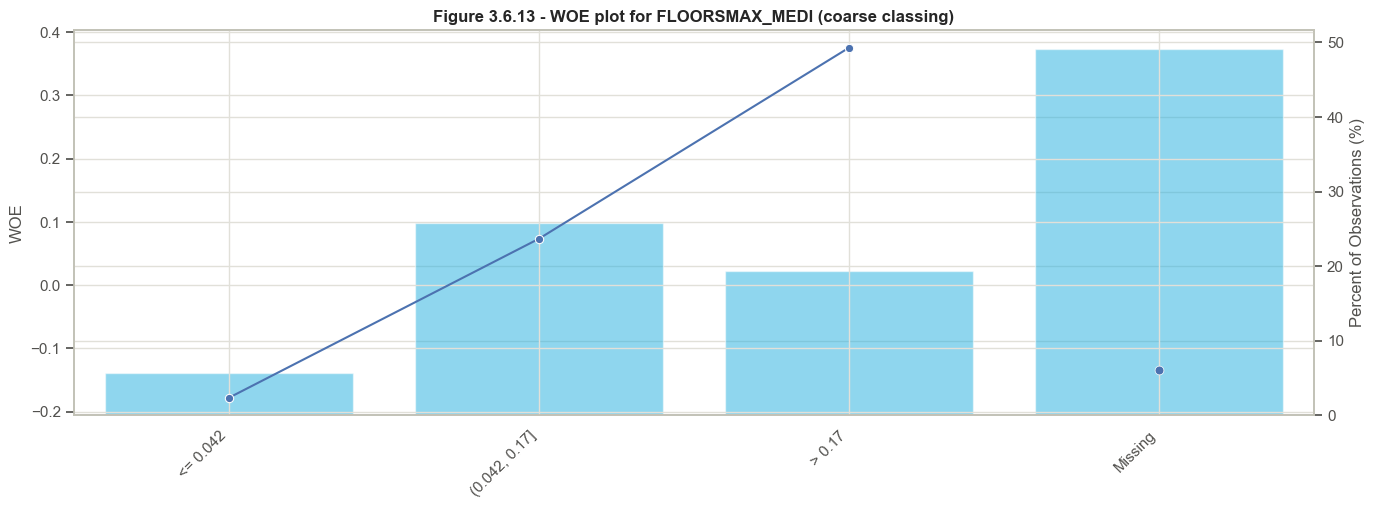

IV for DAYS_ID_PUBLISH with 6 numeric bins: 0.0324


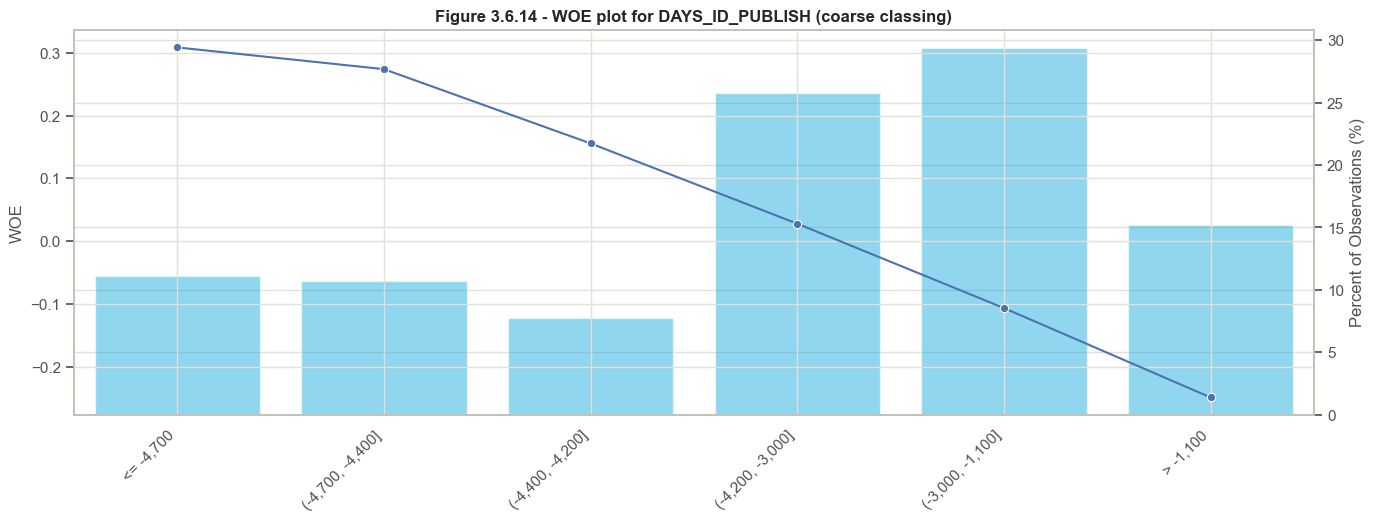

In [61]:
for i, variable in enumerate(shortlist, start=1):
    woe_bin_data = dev_train[[variable, TARGET]].copy()
    woe_bin_data['Bin_Range'] = assign_bins(dev_train, variable, coarse_specs[variable])
    woe_iv_plot(woe_bin_data, variable, order=bin_order(coarse_specs[variable]),
                title=f'Figure 3.6.{i} - WOE plot for {variable} (coarse classing)')

All ten numeric characteristics end with a one-directional WOE trend. The directions make business sense:
- **Lower risk:** higher external score, longer employment, older applicants, higher goods price, a better region rating (1), a more populous region, more floors in the building.
- **Higher risk:** a higher share of bureau credit still outstanding, a very recent credit, a recently changed phone number, a recently reissued identity document.

The categorical groups also read sensibly. Low-skill and manual occupations, and transport and self-employment organisations, are riskier. Accountants, core staff and the public sector are safer. Education collapses into two groups, higher education and the rest, because the academic-degree level is too small to stand alone.

**Special bins.**
- `No bureau history` has a negative WOE (bad rate about 10%), consistent with 1.5.
- The `Missing` bins of `employment_years` and `OCCUPATION_TYPE`, and the organisation group containing `Not employed (XNA)`, have positive WOE. These applicants are mostly pensioners, whose bad rate is below average (Table 1.3b). The bins therefore favour applicants outside employment rather than penalising them. They do overlap with `NAME_INCOME_TYPE`, which is kept for audit only, and this overlap is noted for the fairness review in 5.9.

**Exceptions to the 5% guide.**
- The `Missing` bin of `AMT_GOODS_PRICE` (0.1% of dev_train, 116 applicants, 5 bads) has a WOE resting on very few bads.
- The `Missing` bin of `BUR_debt_to_credit` holds 2.7% of dev_train.

Both are kept rather than deleting applicants or merging them without evidence. Their WOE is flagged as less stable.

**Weakest differentiation:** the closest adjacent WOE values are for `DAYS_ID_PUBLISH` (0.035), `OCCUPATION_TYPE` (0.045) and `BUR_days_since_recent_credit` (0.059).

## 3.7 Recalculate Information Value

Coarse classing should keep most of the information. Compare the IV before and after for every shortlisted characteristic (Module 10.3).

In [62]:
iv_compare = pd.DataFrame({'Fine IV': iv_table.loc[shortlist, 'IV'],
                           'Coarse IV': pd.Series({v: t['IV'].sum() for v, t in coarse_tables.items()})})
iv_compare['Change'] = iv_compare['Coarse IV'] - iv_compare['Fine IV']
iv_compare['Change %'] = iv_compare['Change'] / iv_compare['Fine IV'] * 100
iv_compare['Fine band'] = iv_compare['Fine IV'].apply(iv_band)
iv_compare['Coarse band'] = iv_compare['Coarse IV'].apply(iv_band)
print('Table 3.7a - Information Value before and after coarse classing (dev_train)')
display(iv_compare.style.format({'Fine IV': '{:.4f}', 'Coarse IV': '{:.4f}', 'Change': '{:+.4f}', 'Change %': '{:+.1f}'}))

Table 3.7a - Information Value before and after coarse classing (dev_train)


,Fine IV,Coarse IV,Change,Change %,Fine band,Coarse band
EXT_SOURCE_1,0.1614,0.1387,-0.0226,-14.0,Medium,Medium
employment_years,0.1103,0.1084,-0.0019,-1.7,Medium,Medium
AMT_GOODS_PRICE,0.1058,0.0464,-0.0593,-56.1,Medium,Weak
BUR_debt_to_credit,0.0983,0.0938,-0.0045,-4.5,Weak,Weak
BUR_days_since_recent_credit,0.0818,0.0765,-0.0053,-6.4,Weak,Weak
OCCUPATION_TYPE,0.0784,0.0752,-0.0032,-4.1,Weak,Weak
age_years,0.0699,0.0681,-0.0019,-2.7,Weak,Weak
ORGANIZATION_TYPE,0.0699,0.0661,-0.0038,-5.4,Weak,Weak
NAME_EDUCATION_TYPE,0.0507,0.0499,-0.0008,-1.5,Weak,Weak
DAYS_LAST_PHONE_CHANGE,0.0504,0.0490,-0.0014,-2.7,Weak,Weak


The largest loss is for `AMT_GOODS_PRICE`. Its fine-classed WOE shows why.

IV for AMT_GOODS_PRICE with 19 numeric bins: 0.1058


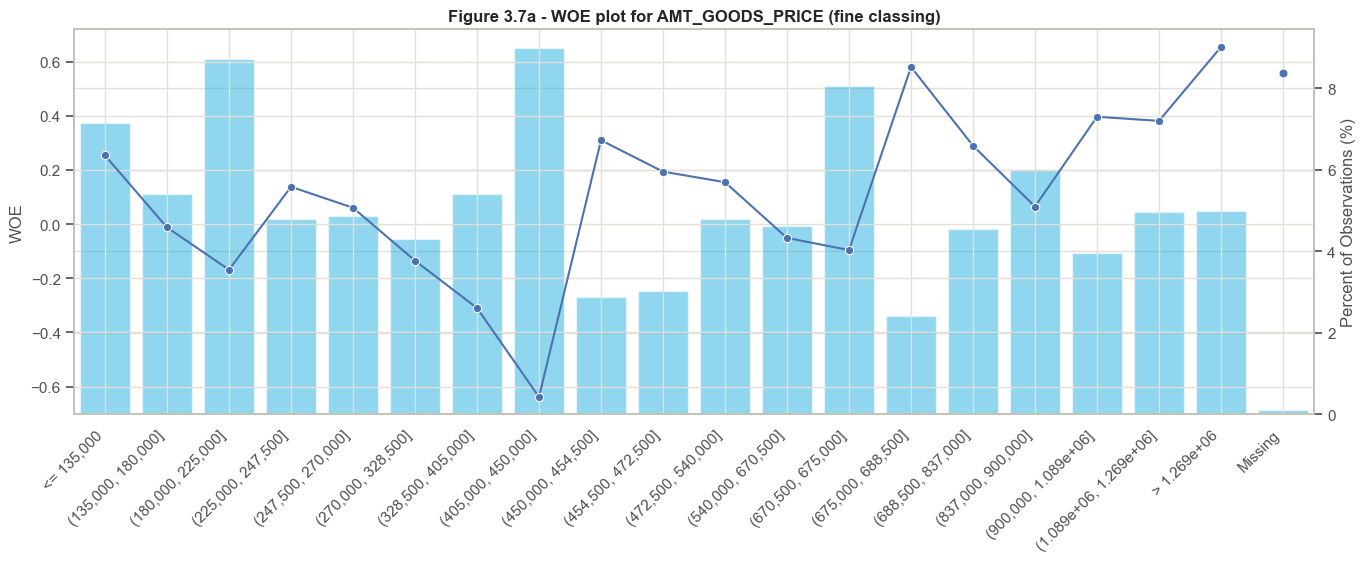

In [63]:
variable = 'AMT_GOODS_PRICE'
woe_bin_data = dev_train[[variable, TARGET]].copy()
woe_bin_data['Bin_Range'] = assign_bins(dev_train, variable, fine_specs[variable])
woe_iv_plot(woe_bin_data, variable, order=bin_order(fine_specs[variable]), title='Figure 3.7a - WOE plot for AMT_GOODS_PRICE (fine classing)')

Most characteristics keep at least 85% of their fine-classed IV and stay in the same band. Two lose more:

- **`AMT_GOODS_PRICE` (-56%, medium to weak).** The fine bins form a saw-tooth (Figure 3.7a). Risk rises towards the popular round prices of 450,000 and 675,000 and drops sharply just above them. This reflects the clustering of goods prices at round amounts, not a logical relationship between loan size and risk, so a fine scorecard would be overfitting it. The coarse version keeps the underlying trend (larger loans, lower risk), and the loss of IV is accepted.
- **`REGION_POPULATION_RELATIVE` (-31%).** The field takes a limited set of regional values with an irregular fine-bin pattern that the monotonic grouping smooths over.

On validation, the frozen bins give IVs close to dev_train for most characteristics. Three fall by roughly a quarter or more: `ORGANIZATION_TYPE`, `DAYS_LAST_PHONE_CHANGE` and `DAYS_ID_PUBLISH`. Their dev_train patterns are less stable, which makes them natural candidates for the tuning experiments in 5.5.

As a check on the frozen development bins, the same attributes are applied unchanged to the validation set. Nothing is refitted: validation only shows whether the dev_train WOE pattern holds on unseen data.

In [64]:
validation_iv = pd.Series({v: woe_iv(validation, v, coarse_specs[v])['IV'].sum() for v in shortlist}, name='Validation IV (same bins)')
display(iv_compare[['Coarse IV']].join(validation_iv).style.format('{:.4f}'))

,Coarse IV,Validation IV (same bins)
EXT_SOURCE_1,0.1387,0.1344
employment_years,0.1084,0.0951
AMT_GOODS_PRICE,0.0464,0.0407
BUR_debt_to_credit,0.0938,0.0983
BUR_days_since_recent_credit,0.0765,0.0809
OCCUPATION_TYPE,0.0752,0.0791
age_years,0.0681,0.0645
ORGANIZATION_TYPE,0.0661,0.0482
NAME_EDUCATION_TYPE,0.0499,0.0404
DAYS_LAST_PHONE_CHANGE,0.0490,0.0362


## 3.8 Finalise Bin Definitions and WOE Mappings

The bin definitions and WOE values are frozen here and used unchanged in Step 4:

- Numeric bins include their right edge, `(lower, upper]`, and the outer bins are open-ended.
- `Missing` and `No bureau history` keep their own WOE.
- Any category not seen in dev_train maps to `Unseen` with a neutral WOE of 0, meaning no evidence either way.

In [65]:
import json

def woe_map(table):
    # attribute -> WOE, with a neutral fallback for unseen categories
    return {**{str(b): float(w) for b, w in table['WOE'].items()}, UNSEEN: 0.0}

final_specs = {v: coarse_specs[v] for v in shortlist}
woe_maps = {v: woe_map(coarse_tables[v]) for v in shortlist}

# checks on dev_train: every record maps to exactly one known attribute, WOE is finite, counts reconcile
for var in shortlist:
    bins = assign_bins(dev_train, var, final_specs[var])
    assert bins.notna().all() and bins.isin(woe_maps[var].keys()).all(), var
    assert np.isfinite(list(woe_maps[var].values())).all(), var
    assert coarse_tables[var]['Count'].sum() == len(dev_train) and coarse_tables[var]['Events'].sum() == dev_train[TARGET].sum(), var
    assert assign_bins(validation, var, final_specs[var]).isin(woe_maps[var].keys()).all(), var

export = {v: {'spec': {k: (val if k != 'groups' else {str(a): g for a, g in val.items()}) for k, val in final_specs[v].items()},
              'woe': woe_maps[v]} for v in shortlist}
(OUTPUT_DIR / 'woe_mappings.json').write_text(json.dumps(export, indent=1))
print(f'Frozen mappings for {len(shortlist)} characteristics; all dev_train and validation records map to a finite WOE.')

Frozen mappings for 14 characteristics; all dev_train and validation records map to a finite WOE.


# Step 4 — Create Scorecard

The scorecard combines three things: the frozen attribute groupings, their WOE values, and logistic regression coefficients (Module 11.1). Everything is fitted on dev_train. The test set is encoded with the frozen mappings but its outcomes are not examined until 5.9.

## 4.1 Data Normalisation through WOE Encoding

Each raw value is replaced by the WOE of its attribute (Module 10.4). This puts every characteristic on the same log-odds scale, lets categorical fields and missing values enter the regression, and limits the influence of outliers, which inherit the WOE of their end bin. WOE is already the normalisation, so no extra min-max or z-scaling is added. The raw columns are not used as model inputs.

In [66]:
def woe_encode(df, specs, maps):
    # replace each characteristic by the WOE of its frozen attribute
    encoded = {f'{v}_WOE': assign_bins(df, v, specs[v]).map(maps[v]).astype(float).values for v in specs}
    return pd.DataFrame(encoded, index=df.index)

X_train = woe_encode(dev_train, final_specs, woe_maps)
X_valid = woe_encode(validation, final_specs, woe_maps)
X_test = woe_encode(test, final_specs, woe_maps)     # outcomes not used until 5.9
y_train, y_valid = dev_train[TARGET], validation[TARGET]

for name, X in [('dev_train', X_train), ('validation', X_valid), ('test', X_test)]:
    assert np.isfinite(X.values).all(), name
print('WOE-encoded inputs:', X_train.shape[1], '| rows:', {'dev_train': len(X_train), 'validation': len(X_valid), 'test': len(X_test)})

WOE-encoded inputs: 14 | rows: {'dev_train': 99786, 'validation': 33262, 'test': 66525}


In [67]:
example_var = 'EXT_SOURCE_1'
encoding_example = pd.DataFrame({'Attribute': list(woe_maps[example_var].keys()),
                                 'WOE': list(woe_maps[example_var].values())})
encoding_example['dev_train rows'] = encoding_example['Attribute'].map(assign_bins(dev_train, example_var, final_specs[example_var]).value_counts()).fillna(0).astype(int)
print(f'Table 4.1a - WOE encoding of {example_var}: every raw value is replaced by its attribute WOE')
display(encoding_example.style.format({'WOE': '{:.4f}', 'dev_train rows': '{:,}'}))

Table 4.1a - WOE encoding of EXT_SOURCE_1: every raw value is replaced by its attribute WOE


,Attribute,WOE,dev_train rows
0,<= 0.43,-0.4291,"14,573"
1,"(0.43, 0.59]",0.2686,"10,651"
2,"(0.59, 0.69]",0.5138,"6,647"
3,> 0.69,1.0878,"10,591"
4,Missing,-0.0880,"57,324"
5,Unseen,0.0000,0


## 4.2 Train Logistic Regression

Logistic regression models the log-odds of a bad outcome as a linear function of the WOE inputs (Module 9.3):

$$z = \ln\frac{p_{bad}}{1 - p_{bad}} = \beta_0 + \sum_i \beta_i \, WOE_i, \qquad p_{bad} = \frac{1}{1 + e^{-z}}$$

**Settings.**
- The model is **unweighted**. The labs used `class_weight='balanced'`, which treats goods and bads as equally common and shifts the intercept, so the predicted probabilities would no longer be true default probabilities and the scaled odds in 4.6 would be wrong.
- It uses scikit-learn's default L2 penalty with C = 1.0. With about 100,000 rows this has a negligible effect; the unpenalised statsmodels estimates are shown alongside as a check.

**Selection.** Characteristics are removed one at a time from the 14-characteristic shortlist:
1. A **positive** coefficient means a higher WOE (lower measured risk) would raise the predicted risk. This usually signals overlap with other inputs, so the characteristic with the largest positive coefficient is removed first.
2. Next, any characteristic that is not significant at 5% is removed.

In [68]:
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm

def fit_logistic(X, y):
    return LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000).fit(X, y)

selected = list(shortlist)
removal_log = []
while True:
    cols = [f'{v}_WOE' for v in selected]
    model = fit_logistic(X_train[cols], y_train)
    coefs = pd.Series(model.coef_[0], index=selected)
    if (coefs > 0).any():
        drop = coefs.idxmax()
        removal_log.append({'Removed': drop, 'Reason': f'positive coefficient ({coefs[drop]:+.3f})'})
        selected.remove(drop)
        continue
    sm_fit = sm.Logit(y_train, sm.add_constant(X_train[cols])).fit(disp=0)
    pvalues = sm_fit.pvalues.drop('const')
    if pvalues.max() > 0.05:
        drop = pvalues.idxmax().replace('_WOE', '')
        removal_log.append({'Removed': drop, 'Reason': f'not significant (p = {pvalues.max():.3f})'})
        selected.remove(drop)
        continue
    break

model_cols = [f'{v}_WOE' for v in selected]
baseline_model = model
print('Converged:', baseline_model.n_iter_[0] < baseline_model.max_iter, '| iterations:', baseline_model.n_iter_[0])
print(f'Characteristics in the model: {len(selected)} of {len(shortlist)} shortlisted')
print('Table 4.2a - Characteristics removed during fitting')
display(pd.DataFrame(removal_log) if removal_log else pd.DataFrame({'Removed': ['none']}))

Converged: True | iterations: 12
Characteristics in the model: 13 of 14 shortlisted
Table 4.2a - Characteristics removed during fitting


,Removed,Reason
0,REGION_POPULATION_RELATIVE,not significant (p = 0.447)


In [69]:
p_train = baseline_model.predict_proba(X_train[model_cols])[:, 1]
p_valid = baseline_model.predict_proba(X_valid[model_cols])[:, 1]
print(f'Mean predicted p_bad - dev_train: {p_train.mean():.4f} (observed bad rate {y_train.mean():.4f})')
print(f'Mean predicted p_bad - validation: {p_valid.mean():.4f} (observed bad rate {y_valid.mean():.4f})')

Mean predicted p_bad - dev_train: 0.0791 (observed bad rate 0.0792)
Mean predicted p_bad - validation: 0.0793 (observed bad rate 0.0792)


Only `REGION_POPULATION_RELATIVE` is removed: once region rating is in the model it adds nothing significant (p = 0.45). No coefficient turned positive. Because the model is unweighted, its mean predicted bad probability matches the observed bad rate on dev_train and on validation. The probabilities are calibrated on average, which the scaling in 4.6 relies on.

## 4.3 Examine Coefficients and Selected Characteristics

With WOE inputs, every coefficient should be negative: a higher WOE means a safer attribute, so it should lower the log-odds of a bad outcome.

In [70]:
coef_table = pd.DataFrame({
    'Coefficient (sklearn)': baseline_model.coef_[0],
    'Coefficient (unpenalised)': sm_fit.params.drop('const').values,
    'Std error': sm_fit.bse.drop('const').values,
    'p-value': sm_fit.pvalues.drop('const').values,
}, index=selected)
coef_table['Coarse IV (dev_train)'] = [coarse_tables[v]['IV'].sum() for v in selected]
coef_table['Validation IV'] = validation_iv[selected].values
coef_table.loc['Intercept', ['Coefficient (sklearn)', 'Coefficient (unpenalised)']] = [baseline_model.intercept_[0], sm_fit.params['const']]
print('Table 4.3a - Logistic regression on WOE inputs (dev_train)')
display(coef_table.style.format('{:.4f}', na_rep=''))

woe_corr = X_train[model_cols].corr()
max_pair = woe_corr.where(np.triu(np.ones(woe_corr.shape, dtype=bool), k=1)).abs().stack()
print(f'Largest correlation between two WOE inputs: {max_pair.max():.2f} ({max_pair.idxmax()[0]} vs {max_pair.idxmax()[1]})')

Table 4.3a - Logistic regression on WOE inputs (dev_train)


,Coefficient (sklearn),Coefficient (unpenalised),Std error,p-value,Coarse IV (dev_train),Validation IV
EXT_SOURCE_1,-0.6715,-0.6771,0.0374,0.0000,0.1387,0.1344
employment_years,-0.5424,-0.5411,0.0441,0.0000,0.1084,0.0951
AMT_GOODS_PRICE,-0.4443,-0.4463,0.0591,0.0000,0.0464,0.0407
BUR_debt_to_credit,-0.6325,-0.6350,0.0425,0.0000,0.0938,0.0983
BUR_days_since_recent_credit,-0.5832,-0.5859,0.0471,0.0000,0.0765,0.0809
OCCUPATION_TYPE,-0.3303,-0.3341,0.0494,0.0000,0.0752,0.0791
age_years,-0.1404,-0.1320,0.0552,0.0167,0.0681,0.0645
ORGANIZATION_TYPE,-0.3633,-0.3692,0.0585,0.0000,0.0661,0.0482
NAME_EDUCATION_TYPE,-0.6848,-0.6883,0.0607,0.0000,0.0499,0.0404
DAYS_LAST_PHONE_CHANGE,-0.6564,-0.6521,0.0564,0.0000,0.0490,0.0362


Largest correlation between two WOE inputs: 0.45 (employment_years_WOE vs age_years_WOE)


All 13 coefficients are negative, as expected, and the penalised and unpenalised estimates agree closely, so regularisation has no practical effect. The WOE inputs overlap only moderately; the largest correlation, between age and employment length, is 0.45. That overlap explains why `age_years` has the smallest coefficient and the weakest significance (p = 0.017). Older applicants have usually held their jobs longer, so the two fields share much of their signal.

**Why these 13 characteristics:**
- Each has an IV of at least 0.03 and a logical, monotonic or business-coherent attribute pattern.
- Each survived the redundancy rules and is significant with the expected sign.
- Together they span the external score, employment, loan size, bureau behaviour, occupation and education, region, housing and stability signals.

Coefficient size is not a ranking of standalone strength. With WOE inputs, a coefficient below 1 in magnitude means part of the characteristic's information is already carried by the others. Thirteen characteristics is within the class guide of 8-15. `ORGANIZATION_TYPE`, `DAYS_LAST_PHONE_CHANGE` and `DAYS_ID_PUBLISH` lost the most IV on validation (3.7), so they are tested in 5.5.

In [71]:
# keep the baseline configuration locally so Step 5 compares against the same model
baseline_config = {'selected': selected, 'intercept': float(baseline_model.intercept_[0]),
                   'coefficients': dict(zip(selected, map(float, baseline_model.coef_[0])))}
_ = (OUTPUT_DIR / 'baseline_model.json').write_text(json.dumps(baseline_config, indent=1))

## 4.4 Construct the Preliminary Scorecard

The points for attribute *j* of characteristic *i* combine the coefficient, which weights the characteristic, and the WOE, which weights the attribute (Module 11.1):

$$Score_{ij} = -\left(\beta_i \cdot WOE_{ij} + \frac{\beta_0}{n}\right)$$

Here *n* is the number of characteristics. The intercept is shared equally between them so that each characteristic's points stand alone. The minus sign makes higher points mean lower risk. Summed over an applicant's attributes, the points equal −z, the log-odds of being good.

In [72]:
n_chars = len(selected)
beta0 = baseline_model.intercept_[0]
betas = dict(zip(selected, baseline_model.coef_[0]))

rows = []
for var in selected:
    for attribute, woe in woe_maps[var].items():
        if attribute == UNSEEN and final_specs[var]['type'] != 'categorical':
            continue
        rows.append({'Characteristic': var, 'Attribute': attribute, 'WOE': woe, 'Coefficient': betas[var],
                     'Unscaled points': -(betas[var] * woe + beta0 / n_chars)})
prelim = pd.DataFrame(rows)
print('Table 4.4a - Preliminary (unscaled) scorecard')
display(prelim.set_index(['Characteristic', 'Attribute']).style.format('{:.4f}'))

# check: summed unscaled points = -z for every dev_train applicant
z_train = beta0 + X_train[model_cols].values @ baseline_model.coef_[0]
unscaled_sum = sum(-(betas[v] * X_train[f'{v}_WOE'] + beta0 / n_chars) for v in selected)
print('Summed unscaled points equal -z for every dev_train applicant:', np.allclose(unscaled_sum, -z_train))

Table 4.4a - Preliminary (unscaled) scorecard


Summed unscaled points equal -z for every dev_train applicant: True


## 4.5 Define Target Score Target Odds and PDO

Scaling turns the log-odds into familiar point values (Module 11.2). It needs three parameters. No required values were found in the course material, so these are **chosen assumptions**, taken from the lecture example:

- **Target score 600** - the score at which the target odds hold;
- **Target odds 50:1 (good:bad)** - the lecture writes this as "1:50", meaning one bad per 50 goods, so the numeric anchor is O = 50 and the PD at 600 is 1/51 ≈ 1.96%;
- **PDO 20** - every 20 points doubles the good:bad odds.

The target score is a reference point on the scale. It is **not** the approval cutoff, which is chosen in 5.7.

In [73]:
TARGET_SCORE = 600
TARGET_ODDS = 50        # good:bad odds at TARGET_SCORE
PDO = 20
print(f'Target score {TARGET_SCORE} at good:bad odds {TARGET_ODDS}:1 (PD = {1 / (1 + TARGET_ODDS):.2%}); {PDO} points double the odds')

Target score 600 at good:bad odds 50:1 (PD = 1.96%); 20 points double the odds


## 4.6 Calculate Scaling Factor and Offset

$$Factor = \frac{PDO}{\ln 2}, \qquad Offset = TargetScore - Factor \cdot \ln(O), \qquad TotalScore = Offset - Factor \cdot z$$

Because −z is the log of the good:bad odds, a higher score always means a lower risk.

In [74]:
FACTOR = PDO / np.log(2)
OFFSET = TARGET_SCORE - FACTOR * np.log(TARGET_ODDS)
print(f'Factor = {PDO} / ln(2) = {FACTOR:.4f}')
print(f'Offset = {TARGET_SCORE} - {FACTOR:.4f} x ln({TARGET_ODDS}) = {OFFSET:.4f}')

def score_from_z(z):
    return OFFSET - FACTOR * z

def p_bad_from_score(score):
    # numerically stable p_bad = 1 / (1 + exp((score - Offset) / Factor))
    from scipy.special import expit
    return expit(-(score - OFFSET) / FACTOR)

z_at_target = -np.log(TARGET_ODDS)
print(f'Check: score at good:bad odds {TARGET_ODDS} = {score_from_z(z_at_target):.2f}')
print(f'Check: score + PDO = {TARGET_SCORE + PDO} gives p_bad {p_bad_from_score(TARGET_SCORE + PDO):.5f} '
      f'vs 1/(1 + 2 x {TARGET_ODDS}) = {1 / (1 + 2 * TARGET_ODDS):.5f}')

Factor = 20 / ln(2) = 28.8539
Offset = 600 - 28.8539 x ln(50) = 487.1229
Check: score at good:bad odds 50 = 600.00
Check: score + PDO = 620 gives p_bad 0.00990 vs 1/(1 + 2 x 50) = 0.00990


The factor is 28.85 and the offset is 487.12. The lecture slides show 487.14 and 487.12 in different places because of rounding; the unrounded value is used here. At a score of 620 the good:bad odds double to 100:1, as intended.

## 4.7 Calculate Scaled Attribute Points

$$ScaledPoints_{ij} = Factor \cdot Score_{ij} + \frac{Offset}{n}$$

The offset is spread equally across the *n* characteristics, so it is added exactly once in total. Points are rounded to whole numbers for use. The effect of rounding on total scores and probabilities is measured below.

In [75]:
def build_scorecard(selected_vars, intercept, coefficients, specs, maps):
    # scaled scorecard table for a fitted model
    n = len(selected_vars)
    rows = []
    for var in selected_vars:
        for attribute, woe in maps[var].items():
            if attribute == UNSEEN and specs[var]['type'] != 'categorical':
                continue
            unscaled = -(coefficients[var] * woe + intercept / n)
            note = {MISSING: 'Value not reported', NO_HISTORY: 'No bureau record',
                    UNSEEN: 'Category not seen in development (neutral WOE)'}.get(attribute, '')
            rows.append({'Variable': var, 'Attribute / Bin': attribute, 'WOE': woe, 'Coefficient': coefficients[var],
                         'Points (unrounded)': FACTOR * unscaled + OFFSET / n,
                         'Points': int(round(FACTOR * unscaled + OFFSET / n)), 'Notes': note})
    return pd.DataFrame(rows)

scorecard = build_scorecard(selected, beta0, betas, final_specs, woe_maps)
print('Table 4.7a - Scaled scorecard (baseline model)')
display(scorecard.set_index(['Variable', 'Attribute / Bin']).style.format({'WOE': '{:.4f}', 'Coefficient': '{:.4f}', 'Points (unrounded)': '{:.2f}'}))

Table 4.7a - Scaled scorecard (baseline model)


In [76]:
def points_table(df, card, selected_vars, specs):
    # rounded points for each characteristic of each application
    lookup = {(r['Variable'], r['Attribute / Bin']): r['Points'] for _, r in card.iterrows()}
    return pd.DataFrame({v: [lookup[(v, a)] for a in assign_bins(df, v, specs[v])] for v in selected_vars}, index=df.index)

train_points = points_table(dev_train, scorecard, selected, final_specs)
score_rounded = train_points.sum(axis=1)
score_exact = score_from_z(z_train)
gap = score_rounded - score_exact
print(f'Rounded vs exact total score (dev_train): mean gap {gap.mean():+.3f}, max |gap| {gap.abs().max():.2f} points')
print(f'Largest resulting change in p_bad: {np.abs(p_bad_from_score(score_rounded) - p_bad_from_score(score_exact)).max():.5f}')

Rounded vs exact total score (dev_train): mean gap -0.134, max |gap| 3.17 points
Largest resulting change in p_bad: 0.01547


Each characteristic contributes between 34 and 64 points. The widest spreads between the worst and best attribute belong to `EXT_SOURCE_1` (29 points), `REGION_RATING_CLIENT_W_CITY` (21) and `employment_years` (17), so these move an applicant's score the most. `age_years` spans only 4 points, which reflects its overlap with employment length. Special bins sit where their risk puts them. For example, `No bureau history` scores below every bureau-debt bin except the most indebted one, while a missing employment length (mostly pensioners) scores like 9-15 years in a job.

Rounding each characteristic's points to a whole number moves a total score by at most about 3 points. The largest probability change occurs at the very low end of the score range, where probabilities change fastest. Decisions near realistic cutoffs are barely affected.

These are the baseline points. After tuning in 5.5, the final scorecard's points are regenerated in 5.6.

## 4.8 Calculate Applicant Total Scores

One function scores any application. It bins each characteristic with the frozen rules, looks up the WOE, applies the coefficients and scales the result. The checks below confirm three things:
- the score maps back to the model's probability through $p_{bad} = 1 / (1 + e^{(score - Offset)/Factor})$;
- the summed points equal the scaled log-odds;
- a higher score means lower risk.

In [77]:
def score_applications(df, selected_vars=None, model=None, specs=None, maps=None):
    # exact (unrounded) total score and p_bad for each application
    selected_vars, model = selected_vars or selected, model or baseline_model
    specs, maps = specs or final_specs, maps or woe_maps
    X = woe_encode(df, {v: specs[v] for v in selected_vars}, maps)[[f'{v}_WOE' for v in selected_vars]]
    z = model.intercept_[0] + X.values @ model.coef_[0]
    score = score_from_z(z)
    return pd.DataFrame({'score': score, 'p_bad': p_bad_from_score(score)}, index=df.index)

train_scores = score_applications(dev_train)
valid_scores = score_applications(validation)
assert np.allclose(train_scores['p_bad'], p_train), 'score must reproduce the model probability'
assert np.allclose(train_scores['score'], score_exact), 'summed points must equal scaled log-odds'
assert train_scores['score'].corr(train_scores['p_bad'], method='spearman') < -0.999, 'higher score = lower risk'
print('Checks passed: probabilities reproduced, points sum to scaled log-odds, higher score = lower risk')
print(train_scores['score'].describe(percentiles=[0.05, 0.5, 0.95]).round(1).to_dict())

Checks passed: probabilities reproduced, points sum to scaled log-odds, higher score = lower risk
{'count': 99786.0, 'mean': 563.9, 'std': 20.9, 'min': 497.0, '5%': 530.5, '50%': 563.2, '95%': 600.0, 'max': 651.1}


The profiles below are **synthetic model inputs** constructed for illustration. They are not real applicants. Their fields are kept internally consistent:
- ratios are calculated from their parts;
- a no-bureau-history profile has no bureau amounts;
- a not-employed profile has no employment length and the not-employed organisation code.

The last profile deliberately includes an extreme income, an extreme goods price and an occupation never seen in the data, to show that every value still finds a bin. Decisions are made in Step 5 once the cutoff is set.

In [78]:
def synthetic_profile(name, age, employed_years, goods_price, bureau_debt, bureau_credit, days_since_credit, occupation,
                      organisation, education, phone_days, region_rating, region_pop, floors, id_days, ext_score):
    no_history = bureau_credit is None
    return {'Profile': name, 'age_years': age, 'employment_years': employed_years, 'AMT_GOODS_PRICE': goods_price,
            'BUR_debt_sum': np.nan if no_history else bureau_debt, 'BUR_credit_sum': np.nan if no_history else bureau_credit,
            'BUR_days_since_recent_credit': np.nan if no_history else days_since_credit,
            'no_bureau_history': int(no_history), 'OCCUPATION_TYPE': occupation, 'ORGANIZATION_TYPE': organisation,
            'NAME_EDUCATION_TYPE': education, 'DAYS_LAST_PHONE_CHANGE': phone_days, 'REGION_RATING_CLIENT_W_CITY': region_rating,
            'REGION_POPULATION_RELATIVE': region_pop, 'FLOORSMAX_MEDI': floors, 'DAYS_ID_PUBLISH': id_days, 'EXT_SOURCE_1': ext_score}

profiles = pd.DataFrame([
    synthetic_profile('A: established owner', 54, 16.0, 950000, 150000, 1500000, 900, 'Core staff', 'School',
                      'Higher education', -2600, 1, 0.04, 0.33, -4800, 0.75),
    synthetic_profile('B: mid-career owner', 41, 6.0, 600000, 400000, 1000000, 300, 'Sales staff', 'Business Entity Type 3',
                      'Secondary / secondary special', -900, 2, 0.02, 0.17, -3500, np.nan),
    synthetic_profile('C: recent borrower', 28, 1.5, 300000, 900000, 1000000, 30, 'Laborers', 'Self-employed',
                      'Secondary / secondary special', -100, 3, 0.006, np.nan, -500, 0.25),
    synthetic_profile('D: retired owner, no bureau record', 63, np.nan, 450000, None, None, None, np.nan, 'Not employed (XNA)',
                      'Secondary / secondary special', -1500, 2, 0.03, np.nan, -4500, np.nan),
    synthetic_profile('E: extreme values and unseen occupation', 35, 3.0, 9000000, 50000, 100000, 60, 'Astronaut', 'Other',
                      'Higher education', -10, 2, 0.02, 0.5, -200, 0.95),
]).set_index('Profile')
profiles['BUR_debt_to_credit'] = safe_divide(profiles['BUR_debt_sum'], profiles['BUR_credit_sum'])

profile_points = points_table(profiles, scorecard, selected, final_specs)
profile_points['Total points (rounded)'] = profile_points.sum(axis=1)
profile_points = profile_points.join(score_applications(profiles).rename(columns={'score': 'Exact score', 'p_bad': 'Model p_bad'}))
print('Table 4.8a - Points and scores for synthetic model-input profiles')
display(profile_points.style.format({'Exact score': '{:.1f}', 'Model p_bad': '{:.2%}'}))
assert np.isfinite(profile_points['Exact score']).all()

Table 4.8a - Points and scores for synthetic model-input profiles


,EXT_SOURCE_1,employment_years,AMT_GOODS_PRICE,BUR_debt_to_credit,BUR_days_since_recent_credit,OCCUPATION_TYPE,age_years,ORGANIZATION_TYPE,NAME_EDUCATION_TYPE,DAYS_LAST_PHONE_CHANGE,REGION_RATING_CLIENT_W_CITY,FLOORSMAX_MEDI,DAYS_ID_PUBLISH,Total points (rounded),Exact score,Model p_bad
Profile,,,,,,,,,,,,,,,,
A: established owner,64,54,49,48,49,47,44,46,52,52,55,48,47,655,655.7,0.29%
B: mid-career owner,41,42,44,43,45,41,43,41,41,43,43,44,43,554,554.2,8.91%
C: recent borrower,35,37,41,35,35,40,41,41,41,39,34,41,39,499,498.6,40.20%
"D: retired owner, no bureau record",41,49,41,38,39,45,45,47,41,47,43,41,47,564,563.0,6.72%
E: extreme values and unseen occupation,64,40,49,41,35,43,42,43,52,39,43,48,39,578,577.9,4.12%


The dev_train scores have a median of about 563, and only about 5% of applicants score 600 or more. Most applicants are riskier than the target odds of 50:1 (PD 1.96%), which is expected given an average bad rate near 8%, equivalent to good:bad odds of about 11.6:1.

The profiles show how the scorecard behaves:
- **A**, a long-tenured, highly educated applicant with low bureau leverage, scores about 655 (p_bad 0.3%).
- **C**, a young applicant with a very recent credit, high bureau leverage and a low external score, scores about 499 (p_bad 40%).
- **D**, a retired owner with no bureau record, lands near the middle: the favourable employment and organisation points for not being employed offset the penalty for having no bureau history.
- **E** has extreme values and an unseen occupation. Its income and goods price fall into the open end bins, and the unseen occupation takes the neutral points, so it still receives a valid score.

Rounded and exact totals differ by less than one point for every profile.

# Step 5 — Analysis and Tuning

This step evaluates the scorecard, tunes it on the validation set, sets the lending policy (cutoff and pricing) and only then evaluates the frozen model and policy once on the held-out test set (Modules 11.3 and 11.4).

## 5.1 Evaluate Training and Validation Performance

A classifier needs a threshold. The lecture uses p = 0.5 (Module 9.3): approve if p_bad < 0.5. With only about 8% bads, that threshold approves almost everyone, so a second **provisional risk threshold** is also used: approve if p_bad is below the dev_train bad rate. In other words, an applicant is classed as bad if predicted to be riskier than average.

Both thresholds are applied identically to every model compared in 5.5. The final approval cutoff is a separate policy decision (5.7). Accuracy alone is weak evidence at this class balance: approving everyone would already be 92% accurate.

In [79]:
LECTURE_THRESHOLD = 0.5
RISK_THRESHOLD = y_train.mean()
print(f'Provisional risk threshold: approve if p_bad < {RISK_THRESHOLD:.4f} (dev_train bad rate)')

balance = pd.DataFrame({name: {'Applications': len(y), 'Goods': int((y == 0).sum()), 'Bads': int(y.sum()), 'Bad rate %': y.mean() * 100}
                        for name, y in [('dev_train', y_train), ('validation', y_valid)]}).T
print('Table 5.1a - Class balance')
display(balance.style.format({'Applications': '{:,.0f}', 'Goods': '{:,.0f}', 'Bads': '{:,.0f}', 'Bad rate %': '{:.2f}'}))

approval = pd.DataFrame({f'Approval % at p_bad < {t:.3g}': {'dev_train': (p_train < t).mean() * 100, 'validation': (p_valid < t).mean() * 100}
                         for t in [LECTURE_THRESHOLD, RISK_THRESHOLD]})
print('Table 5.1b - Share approved under each threshold (baseline model)')
display(approval.round(1))

Provisional risk threshold: approve if p_bad < 0.0792 (dev_train bad rate)
Table 5.1a - Class balance


,Applications,Goods,Bads,Bad rate %
dev_train,"99,786","91,881","7,905",7.92
validation,"33,262","30,627","2,635",7.92


Table 5.1b - Share approved under each threshold (baseline model)


,Approval % at p_bad < 0.5,Approval % at p_bad < 0.0792
dev_train,100.0000,60.0000
validation,100.0000,59.7000


At p_bad < 0.5 the model approves every applicant, because no predicted probability reaches 0.5 when the average risk is 8%. The lecture threshold therefore cannot separate goods from bads here. The provisional risk threshold approves about 60% of applicants, and the approval share is almost the same on dev_train and validation.

## 5.2 Construct and Interpret Confusion Matrices

In the lecture, the **positive class is the good payer**, even though the dataset codes bad as `TARGET = 1` (Module 11.3). The counts are taken from explicit masks rather than scikit-learn's default positive label:

| | Predicted good (approve) | Predicted bad (reject) |
|---|---|---|
| **Actual good** | TP - good approved | FN - good rejected |
| **Actual bad** | FP - bad approved | TN - bad rejected |

In [80]:
def confusion_counts(y, approve):
    good, bad = (y == 0).values, (y == 1).values
    return {'TP': int((good & approve).sum()), 'FN': int((good & ~approve).sum()),
            'FP': int((bad & approve).sum()), 'TN': int((bad & ~approve).sum())}

def confusion_frame(y, approve):
    c = confusion_counts(y, approve)
    return pd.DataFrame([[c['TP'], c['FN']], [c['FP'], c['TN']]],
                        index=['Actual good payer', 'Actual defaulter'], columns=['Predicted good (approve)', 'Predicted bad (reject)'])

for name, y, p in [('dev_train', y_train, p_train), ('validation', y_valid, p_valid)]:
    print(f'Table 5.2 - Confusion matrix, {name}, baseline model, approve if p_bad < {RISK_THRESHOLD:.4f}')
    display(confusion_frame(y, p < RISK_THRESHOLD).style.format('{:,}'))

Table 5.2 - Confusion matrix, dev_train, baseline model, approve if p_bad < 0.0792


,Predicted good (approve),Predicted bad (reject)
Actual good payer,"57,093","34,788"
Actual defaulter,"2,747","5,158"


Table 5.2 - Confusion matrix, validation, baseline model, approve if p_bad < 0.0792


,Predicted good (approve),Predicted bad (reject)
Actual good payer,"18,911","11,716"
Actual defaulter,937,"1,698"


On validation the provisional threshold rejects 1,698 of 2,635 bads (64%), but to do so it also rejects 11,716 goods. Most rejections are goods because goods outnumber bads about 12 to 1. The dev_train and validation matrices have almost identical proportions, so the model does not appear overfitted.

## 5.3 Calculate Classification Performance Measures

The performance measures from Module 11.3 are calculated from the confusion counts, with good payers as the positive class.

In [81]:
def classification_measures(y, approve):
    c = confusion_counts(y, approve)
    n = sum(c.values())
    ratio = lambda a, b: a / b if b else np.nan
    precision, recall = ratio(c['TP'], c['TP'] + c['FP']), ratio(c['TP'], c['TP'] + c['FN'])
    return {'Accuracy': (c['TP'] + c['TN']) / n, 'Error rate': (c['FP'] + c['FN']) / n,
            'Recall (good)': recall, 'Specificity (bad rejection)': ratio(c['TN'], c['TN'] + c['FP']),
            'Precision (good)': precision, 'F1 (good)': ratio(2 * precision * recall, precision + recall),
            'Approval rate': (c['TP'] + c['FP']) / n, 'Support goods': c['TP'] + c['FN'], 'Support bads': c['FP'] + c['TN']}

measures = pd.DataFrame({f'{name} | p_bad < {t:.3g}': classification_measures(y, p < t)
                         for t in [LECTURE_THRESHOLD, RISK_THRESHOLD]
                         for name, y, p in [('dev_train', y_train, p_train), ('validation', y_valid, p_valid)]}).T

### 5.3.1 Accuracy and Error Rate

$$Accuracy = \frac{TP + TN}{N}, \qquad Error\ rate = \frac{FP + FN}{N} = 1 - Accuracy$$

In [82]:
display(measures[['Accuracy', 'Error rate']].style.format('{:.4f}'))

,Accuracy,Error rate
dev_train | p_bad < 0.5,0.9208,0.0792
validation | p_bad < 0.5,0.9208,0.0792
dev_train | p_bad < 0.0792,0.6238,0.3762
validation | p_bad < 0.0792,0.6196,0.3804


At p_bad < 0.5, accuracy is 92.1%, exactly the share of goods: it is the accuracy of approving everyone and says nothing about the model. At the provisional threshold, accuracy falls to about 62% because 40% of applicants are rejected. This shows why accuracy is a poor guide at this class balance.

### 5.3.2 Recall and Specificity

$$Recall_{good} = \frac{TP}{TP + FN}\ \text{(share of goods approved)}, \qquad Specificity = \frac{TN}{TN + FP}\ \text{(share of bads rejected)}$$

In [83]:
display(measures[['Recall (good)', 'Specificity (bad rejection)', 'Approval rate']].style.format('{:.4f}'))

,Recall (good),Specificity (bad rejection),Approval rate
dev_train | p_bad < 0.5,1.0000,0.0000,1.0000
validation | p_bad < 0.5,1.0000,0.0000,1.0000
dev_train | p_bad < 0.0792,0.6214,0.6525,0.5997
validation | p_bad < 0.0792,0.6175,0.6444,0.5967


Recall and specificity show the trade-off directly. Approving everyone gives recall 1 and specificity 0. The provisional threshold gives recall of about 0.62 (goods approved) and specificity of about 0.64 (bads rejected), with similar values on dev_train and validation.

### 5.3.3 Precision and F1

$$Precision_{good} = \frac{TP}{TP + FP}, \qquad F1_{good} = \frac{2 \cdot Precision \cdot Recall}{Precision + Recall}$$

Zero denominators are returned as missing. The scikit-learn report for both classes is shown as a supplement. Its class "0" row matches the good-positive measures above.

In [84]:
from sklearn.metrics import classification_report
display(measures[['Precision (good)', 'F1 (good)', 'Support goods', 'Support bads']].style.format(
    {'Precision (good)': '{:.4f}', 'F1 (good)': '{:.4f}', 'Support goods': '{:,.0f}', 'Support bads': '{:,.0f}'}))

# supplementary: predicted label 1 = reject (bad), so class "0" = good payer
print('Supplementary classification report - validation, approve if p_bad <', round(RISK_THRESHOLD, 4))
print(classification_report(y_valid, (p_valid >= RISK_THRESHOLD).astype(int), target_names=['0 good payer', '1 defaulter'], digits=3))

,Precision (good),F1 (good),Support goods,Support bads
dev_train | p_bad < 0.5,0.9208,0.9588,"91,881","7,905"
validation | p_bad < 0.5,0.9208,0.9588,"30,627","2,635"
dev_train | p_bad < 0.0792,0.9541,0.7526,"91,881","7,905"
validation | p_bad < 0.0792,0.9528,0.7493,"30,627","2,635"


Supplementary classification report - validation, approve if p_bad < 0.0792
              precision    recall  f1-score   support

0 good payer      0.953     0.617     0.749     30627
 1 defaulter      0.127     0.644     0.212      2635

    accuracy                          0.620     33262
   macro avg      0.540     0.631     0.480     33262
weighted avg      0.887     0.620     0.707     33262



Precision for goods rises from 0.921 (approve all) to about 0.953: the approved group is cleaner. F1 for goods is higher at p_bad < 0.5 (0.959) than at the provisional threshold (0.749), but only because approving everyone maximises recall for goods. F1 for goods must be read together with specificity. In the supplementary report, the class-0 row matches the good-positive figures, and the class-1 row shows that only about 13% of rejected applicants are actually bad.

## 5.4 Evaluate ROC Curves and AUC

The ROC curve plots the share of goods approved (TPR) against the share of bads approved (FPR) as the cutoff moves (Module 11.3). To keep the lecture's good-positive orientation, the curve is drawn with `y_good = 1 - TARGET` and `p_good = 1 - p_bad`.

AUC is the probability that a random good scores higher than a random bad. **Gini** = 2·AUC − 1. **KS** is the largest gap between the TPR and FPR curves.

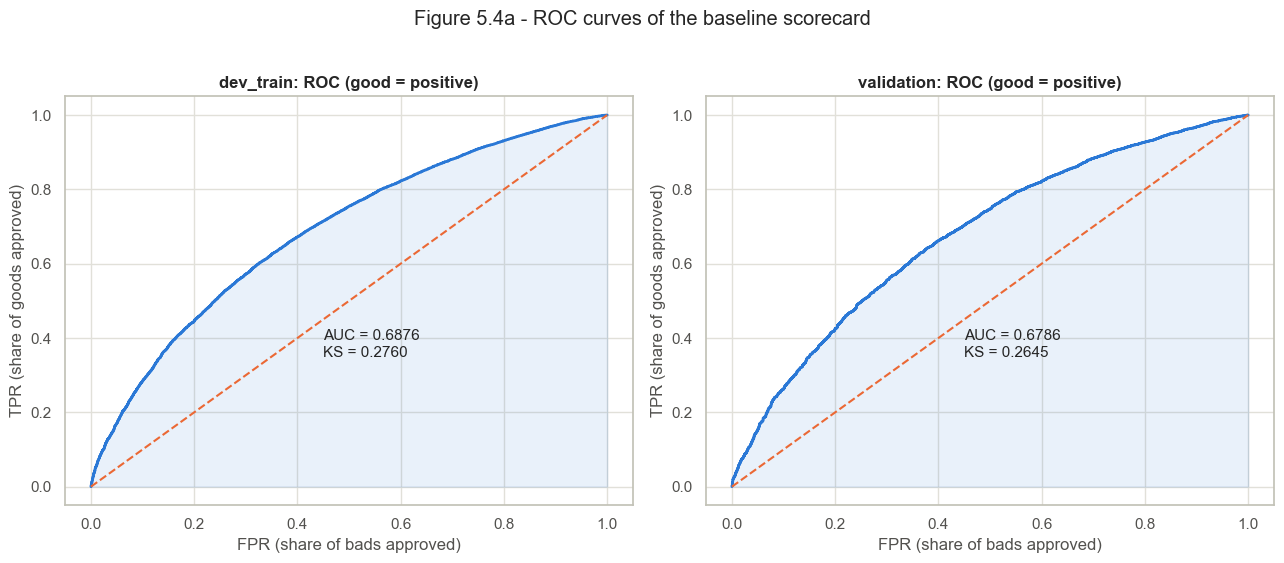

Table 5.4a - Discrimination of the baseline scorecard


,AUC,Gini,KS
dev_train,0.6876,0.3753,0.2760
validation,0.6786,0.3572,0.2645


In [85]:
from sklearn.metrics import roc_curve, roc_auc_score

def discrimination(y, p_bad):
    y_good, p_good = 1 - y, 1 - p_bad
    fpr, tpr, _ = roc_curve(y_good, p_good)
    auc = roc_auc_score(y_good, p_good)
    return {'AUC': auc, 'Gini': 2 * auc - 1, 'KS': np.max(tpr - fpr)}, fpr, tpr

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
roc_rows = {}
for ax, (name, y, p) in zip(axes, [('dev_train', y_train, p_train), ('validation', y_valid, p_valid)]):
    stats, fpr, tpr = discrimination(y, p)
    roc_rows[name] = stats
    ax.plot(fpr, tpr, color=GOOD_COLOUR, linewidth=2)
    ax.fill_between(fpr, tpr, alpha=0.1, color=GOOD_COLOUR)
    ax.plot([0, 1], [0, 1], '--', color=BAD_COLOUR)
    ax.text(0.45, 0.35, f"AUC = {stats['AUC']:.4f}\nKS = {stats['KS']:.4f}", fontsize=11)
    ax.set_xlabel('FPR (share of bads approved)'); ax.set_ylabel('TPR (share of goods approved)')
    ax.set_title(f'{name}: ROC (good = positive)')
plt.suptitle('Figure 5.4a - ROC curves of the baseline scorecard', y=1.02)
plt.tight_layout()
plt.show()
print('Table 5.4a - Discrimination of the baseline scorecard')
display(pd.DataFrame(roc_rows).T.style.format('{:.4f}'))

AUC is 0.688 on dev_train and 0.679 on validation (Gini 0.36, KS 0.26). This sits in the lecture's *poor* band (0.6-0.7), just below *fair*. The small gap between dev_train and validation means little overfitting. The modest level matches the IV results: only three characteristics reached medium IV, and the extract holds a single external score.

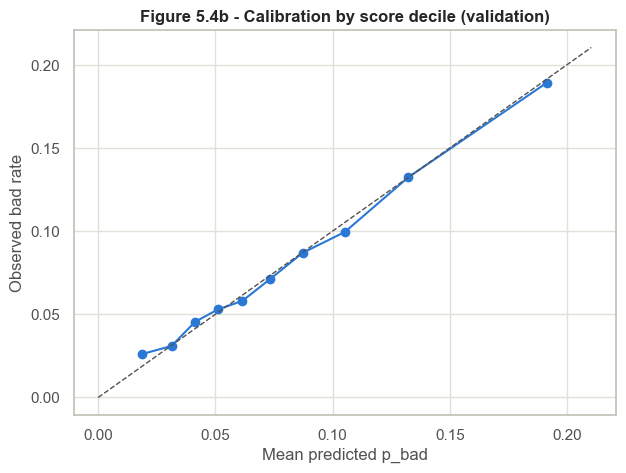

In [86]:
# calibration: mean predicted vs observed bad rate by score decile (validation)
deciles = pd.qcut(valid_scores['score'], 10, labels=False)
calibration = pd.DataFrame({'Mean predicted p_bad': valid_scores.groupby(deciles)['p_bad'].mean(),
                            'Observed bad rate': y_valid.groupby(deciles).mean()})
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(calibration['Mean predicted p_bad'], calibration['Observed bad rate'], marker='o', color=GOOD_COLOUR)
lim = calibration.values.max() * 1.1
ax.plot([0, lim], [0, lim], '--', color='#52514e', linewidth=1)
ax.set_xlabel('Mean predicted p_bad'); ax.set_ylabel('Observed bad rate')
ax.set_title('Figure 5.4b - Calibration by score decile (validation)')
plt.show()

Across the score deciles, observed bad rates on validation lie close to the diagonal, from about 2.6% in the safest decile to about 19% in the riskiest. The predicted probabilities are therefore usable as risk estimates for setting the cutoff and pricing. The unweighted fit in 4.2 is what makes this possible.

## 5.5 Tune Characteristics and Attribute Groupings

Three tuning experiments from Module 11.4 are run, each targeting a weakness found in 3.7 and 4.3. For every experiment:
- bins, WOE and the logistic regression are **refitted on dev_train only**;
- the result is scored on the same validation set, at the same provisional threshold, against the baseline.

| # | Lever (Module 11.4) | Change | Evidence |
|---|---|---|---|
| 1 | Remove a characteristic | Drop `DAYS_ID_PUBLISH` | Weakest characteristic; validation IV fell from 0.032 to 0.022 |
| 2 | Change attribute ranges | Re-cut `DAYS_LAST_PHONE_CHANGE` into at most 3 bins | Validation IV fell from 0.049 to 0.036 with 6 bins |
| 3 | Reduce the number of attributes | Merge `ORGANIZATION_TYPE` into at most 3 groups | Largest validation IV drop (0.066 to 0.048) |

**Adoption rule, fixed before seeing the results:** adopt a change if validation AUC falls by no more than 0.001 and the change makes the scorecard simpler or more stable. Changes that pass on their own are then applied cumulatively, smallest AUC loss first. Each is kept only while the combined validation AUC stays within 0.001 of the baseline.

In [87]:
def fit_pipeline(specs, variables):
    # refit WOE and logistic regression on dev_train for a given set of bins and characteristics
    tables = {v: woe_iv(dev_train, v, specs[v]) for v in variables}
    maps = {v: woe_map(tables[v]) for v in variables}
    sub_specs = {v: specs[v] for v in variables}
    model = fit_logistic(woe_encode(dev_train, sub_specs, maps), y_train)
    pipe = {'variables': list(variables), 'specs': sub_specs, 'maps': maps, 'tables': tables, 'model': model}
    pipe['p_train'] = model.predict_proba(woe_encode(dev_train, sub_specs, maps))[:, 1]
    pipe['p_valid'] = model.predict_proba(woe_encode(validation, sub_specs, maps))[:, 1]
    return pipe

def evaluate(pipe):
    stats, _, _ = discrimination(y_valid, pipe['p_valid'])
    m = classification_measures(y_valid, pipe['p_valid'] < RISK_THRESHOLD)
    return {'Characteristics': len(pipe['variables']),
            'Attributes': sum(len(t) for t in pipe['tables'].values()),
            'Validation AUC': stats['AUC'], 'Validation KS': stats['KS'],
            'F1 (good)': m['F1 (good)'], 'Recall (good)': m['Recall (good)'], 'Specificity': m['Specificity (bad rejection)'],
            'Positive coefficients': int((pipe['model'].coef_[0] > 0).sum())}

baseline_pipe = fit_pipeline(final_specs, selected)
assert np.allclose(baseline_pipe['p_valid'], p_valid), 'refitted baseline must reproduce Step 4'

exp_specs_2 = {**final_specs, 'DAYS_LAST_PHONE_CHANGE': coarse_numeric(dev_train, 'DAYS_LAST_PHONE_CHANGE', fine_specs['DAYS_LAST_PHONE_CHANGE'], max_bins=3)}
exp_specs_3 = {**final_specs, 'ORGANIZATION_TYPE': coarse_categorical(dev_train, 'ORGANIZATION_TYPE', fine_specs['ORGANIZATION_TYPE'], max_groups=3)}

experiments = {
    'Baseline': baseline_pipe,
    '1: drop DAYS_ID_PUBLISH': fit_pipeline(final_specs, [v for v in selected if v != 'DAYS_ID_PUBLISH']),
    '2: DAYS_LAST_PHONE_CHANGE in 3 bins': fit_pipeline(exp_specs_2, selected),
    '3: ORGANIZATION_TYPE in 3 groups': fit_pipeline(exp_specs_3, selected),
}
tuning = pd.DataFrame({name: evaluate(pipe) for name, pipe in experiments.items()}).T
tuning['AUC change vs baseline'] = tuning['Validation AUC'] - tuning.loc['Baseline', 'Validation AUC']
tuning['Within AUC rule alone'] = ['-'] + ['yes' if (d >= -0.001) else 'no' for d in tuning['AUC change vs baseline'].iloc[1:]]
print(f'Table 5.5a - Tuning experiments on validation (approve if p_bad < {RISK_THRESHOLD:.4f})')
display(tuning.style.format({'Validation AUC': '{:.4f}', 'Validation KS': '{:.4f}', 'F1 (good)': '{:.4f}', 'Recall (good)': '{:.4f}',
                             'Specificity': '{:.4f}', 'AUC change vs baseline': '{:+.4f}'}))

Table 5.5a - Tuning experiments on validation (approve if p_bad < 0.0792)


,Characteristics,Attributes,Validation AUC,Validation KS,F1 (good),Recall (good),Specificity,Positive coefficients,AUC change vs baseline,Within AUC rule alone
Baseline,13.000000,72.000000,0.6786,0.2645,0.7493,0.6175,0.6444,0.000000,+0.0000,-
1: drop DAYS_ID_PUBLISH,12.000000,66.000000,0.6784,0.2654,0.7493,0.6173,0.6459,0.000000,-0.0002,yes
2: DAYS_LAST_PHONE_CHANGE in 3 bins,13.000000,69.000000,0.6776,0.2603,0.7473,0.6148,0.6436,0.000000,-0.0010,yes
3: ORGANIZATION_TYPE in 3 groups,13.000000,69.000000,0.6785,0.2658,0.7493,0.6175,0.6440,0.000000,-0.0001,yes


All three changes keep validation AUC within 0.001 of the baseline, so each passes the rule on its own. Dropping `DAYS_ID_PUBLISH` costs only 0.0002 AUC and slightly raises KS and specificity, which confirms it added little. Regrouping `ORGANIZATION_TYPE` into three groups costs 0.0001. Re-cutting `DAYS_LAST_PHONE_CHANGE` costs the most, 0.0010.

The regrouped characteristics from experiments 2 and 3 are shown in the lab's WOE-plot format.

IV for DAYS_LAST_PHONE_CHANGE with 3 numeric bins: 0.0416


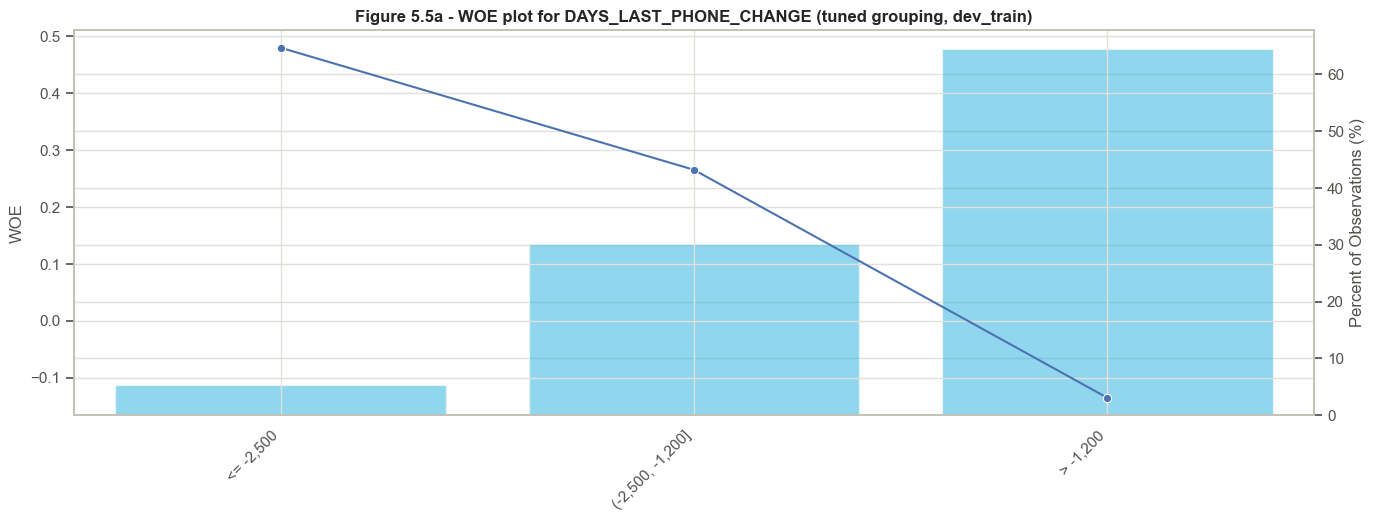

Validation IV with the tuned grouping: 0.0259
IV for ORGANIZATION_TYPE with 3 numeric bins: 0.0619


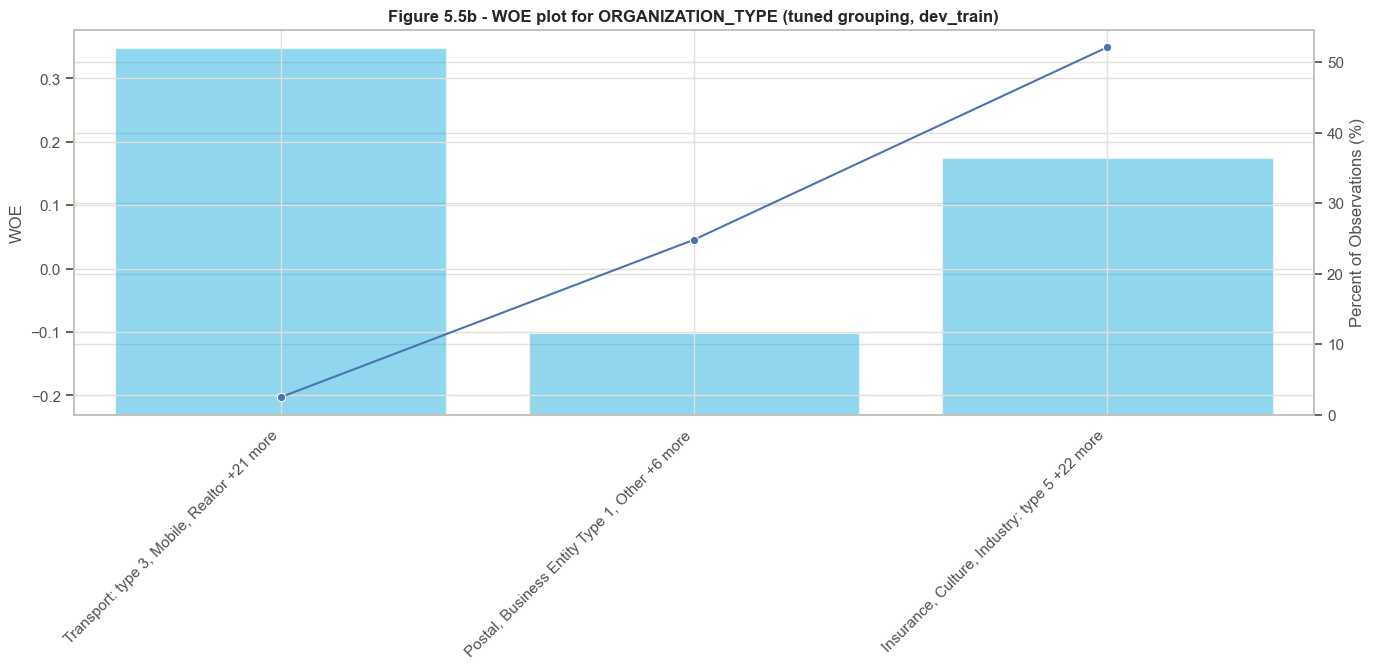

Validation IV with the tuned grouping: 0.0425


In [88]:
for variable, specs, label in [('DAYS_LAST_PHONE_CHANGE', exp_specs_2, 'Figure 5.5a'), ('ORGANIZATION_TYPE', exp_specs_3, 'Figure 5.5b')]:
    woe_bin_data = dev_train[[variable, TARGET]].copy()
    woe_bin_data['Bin_Range'] = assign_bins(dev_train, variable, specs[variable])
    woe_iv_plot(woe_bin_data, variable, order=bin_order(specs[variable]), title=f'{label} - WOE plot for {variable} (tuned grouping, dev_train)')
    valid_check = woe_iv(validation, variable, specs[variable])['IV'].sum()
    print(f'Validation IV with the tuned grouping: {valid_check:.4f}')

The three-group `ORGANIZATION_TYPE` keeps a validation IV of 0.043, close to the 0.048 of six groups, with half the attributes. The three-bin `DAYS_LAST_PHONE_CHANGE`, by contrast, drops to a validation IV of 0.026 from 0.036. Coarser bins removed information rather than adding stability.

In [89]:
# apply passing changes cumulatively, smallest AUC loss first, keeping each only while the
# combined validation AUC stays within 0.001 of the baseline
changes = {
    '1: drop DAYS_ID_PUBLISH': lambda specs, vars_: (specs, [v for v in vars_ if v != 'DAYS_ID_PUBLISH']),
    '2: DAYS_LAST_PHONE_CHANGE in 3 bins': lambda specs, vars_: ({**specs, 'DAYS_LAST_PHONE_CHANGE': exp_specs_2['DAYS_LAST_PHONE_CHANGE']}, vars_),
    '3: ORGANIZATION_TYPE in 3 groups': lambda specs, vars_: ({**specs, 'ORGANIZATION_TYPE': exp_specs_3['ORGANIZATION_TYPE']}, vars_),
}
baseline_auc = tuning.loc['Baseline', 'Validation AUC']
candidates = tuning.iloc[1:][tuning.iloc[1:]['Within AUC rule alone'] == 'yes'].sort_values('AUC change vs baseline', ascending=False).index

combined_specs, combined_vars, adopted, steps = dict(final_specs), list(selected), [], {}
for name in candidates:
    trial_specs, trial_vars = changes[name](combined_specs, combined_vars)
    trial_pipe = fit_pipeline(trial_specs, trial_vars)
    trial_auc = evaluate(trial_pipe)['Validation AUC']
    keep = trial_auc >= baseline_auc - 0.001
    steps[f'+ {name}'] = {**evaluate(trial_pipe), 'Kept': 'yes' if keep else 'no'}
    if keep:
        combined_specs, combined_vars, combined_pipe = trial_specs, trial_vars, trial_pipe
        adopted.append(name)
if not adopted:
    combined_pipe = baseline_pipe

print('Adopted changes:', adopted if adopted else 'none')
print('Table 5.5b - Cumulative adoption on validation (AUC limit: baseline - 0.001)')
display(pd.DataFrame({'Baseline': {**evaluate(baseline_pipe), 'Kept': '-'}, **steps}).T.style.format(
    {'Validation AUC': '{:.4f}', 'Validation KS': '{:.4f}', 'F1 (good)': '{:.4f}', 'Recall (good)': '{:.4f}', 'Specificity': '{:.4f}'}))

Adopted changes: ['3: ORGANIZATION_TYPE in 3 groups', '1: drop DAYS_ID_PUBLISH']
Table 5.5b - Cumulative adoption on validation (AUC limit: baseline - 0.001)


,Characteristics,Attributes,Validation AUC,Validation KS,F1 (good),Recall (good),Specificity,Positive coefficients,Kept
Baseline,13,72,0.6786,0.2645,0.7493,0.6175,0.6444,0,-
+ 3: ORGANIZATION_TYPE in 3 groups,13,69,0.6785,0.2658,0.7493,0.6175,0.6440,0,yes
+ 1: drop DAYS_ID_PUBLISH,12,63,0.6783,0.2669,0.7490,0.6168,0.6493,0,yes
+ 2: DAYS_LAST_PHONE_CHANGE in 3 bins,12,60,0.6773,0.2609,0.7465,0.6138,0.6436,0,no


Applied cumulatively, the `ORGANIZATION_TYPE` regrouping and the removal of `DAYS_ID_PUBLISH` are kept. Together they give 12 characteristics and 63 attributes (down from 13 and 72) for a validation AUC of 0.6783, only 0.0003 below the baseline, with a slightly higher KS. Adding the phone-change re-cut would take the loss past the 0.001 limit, so it is rejected. All tuning compares models at the same provisional threshold; changing the approval cutoff is a separate policy decision (5.7).

## 5.6 Select the Final Scorecard

The final scorecard is chosen on validation performance, simplicity and stability (Module 11.4). It remains the pipeline fitted on **dev_train**: bins, WOE, coefficients and scaling are frozen as fitted, so the cutoff chosen on validation keeps its meaning. Refitting on all development data would change the scores, and the cutoff would then have to be re-derived.

In [90]:
use_combined = len(adopted) > 0
final_pipe = combined_pipe if use_combined else baseline_pipe
final_vars, final_model = final_pipe['variables'], final_pipe['model']
final_beta0, final_betas = final_model.intercept_[0], dict(zip(final_vars, final_model.coef_[0]))
assert all(b < 0 for b in final_betas.values()), 'all coefficients should be negative'
print('Final scorecard:', ('tuned model: ' + ', '.join(adopted)) if use_combined else 'baseline model', f'| {len(final_vars)} characteristics')

final_scorecard = build_scorecard(final_vars, final_beta0, final_betas, final_pipe['specs'], final_pipe['maps'])
print('Table 5.6a - Final scorecard (Final Scorecard template fields)')
display(final_scorecard[['Variable', 'Attribute / Bin', 'Points', 'Notes']].set_index(['Variable', 'Attribute / Bin']))

Final scorecard: tuned model: 3: ORGANIZATION_TYPE in 3 groups, 1: drop DAYS_ID_PUBLISH | 12 characteristics
Table 5.6a - Final scorecard (Final Scorecard template fields)


Points               Notes
Variable                    Attribute / Bin                            
EXT_SOURCE_1                <= 0.43              38                    
                            (0.43, 0.59]         52                    
                            (0.59, 0.69]         56                    
                            > 0.69               67                    
                            Missing              45  Value not reported
...                                             ...                 ...
REGION_RATING_CLIENT_W_CITY 3                    38                    
FLOORSMAX_MEDI              <= 0.042             44                    
                            (0.042, 0.17]        48                    
                            > 0.17               52                    
                            Missing              45  Value not reported

[66 rows x 2 columns]

The final scorecard is the tuned model with 12 characteristics. Its points replace the baseline points in 4.7. They differ slightly because the coefficients were refitted and the offset is now shared across 12 characteristics instead of 13. All coefficients remain negative.

In [91]:
def selection_reason(var):
    if var in final_vars:
        return 'In final scorecard'
    if var in dropped:
        return dropped[var]
    if var in [r['Removed'] for r in removal_log]:
        return next(r['Reason'] for r in removal_log if r['Removed'] == var)
    if var in selected and var not in final_vars:
        return 'Removed in tuning (5.5)'
    return 'Not shortlisted'

top15_final = iv_table.head(TOP_N_IV)[['Rank', 'IV', 'Band']].copy()
top15_final['Used in final scorecard'] = ['Yes' if v in final_vars else 'No' for v in top15_final.index]
top15_final['Reason'] = [selection_reason(v) for v in top15_final.index]
print('Table 5.6b - Top 15 characteristics by IV (dev_train) and their use in the final scorecard')
display(top15_final.style.format({'IV': '{:.4f}'}))

# frozen final scoring
def final_scores(df):
    return score_applications(df, final_vars, final_model, final_pipe['specs'], final_pipe['maps'])

final_train_scores, final_valid_scores = final_scores(dev_train), final_scores(validation)
_ = (OUTPUT_DIR / 'final_model.json').write_text(json.dumps({'variables': final_vars, 'intercept': float(final_beta0),
                                                              'coefficients': {k: float(v) for k, v in final_betas.items()},
                                                              'target_score': TARGET_SCORE, 'target_odds': TARGET_ODDS, 'pdo': PDO}, indent=1))

Table 5.6b - Top 15 characteristics by IV (dev_train) and their use in the final scorecard


,Rank,IV,Band,Used in final scorecard,Reason
EXT_SOURCE_1,1,0.1614,Medium,Yes,In final scorecard
employment_years,2,0.1103,Medium,Yes,In final scorecard
AMT_GOODS_PRICE,3,0.1058,Medium,Yes,In final scorecard
BUR_debt_to_credit,4,0.0983,Weak,Yes,In final scorecard
BUR_days_since_recent_credit,5,0.0818,Weak,Yes,In final scorecard
OCCUPATION_TYPE,6,0.0784,Weak,Yes,In final scorecard
age_years,7,0.0699,Weak,Yes,In final scorecard
ORGANIZATION_TYPE,8,0.0699,Weak,Yes,In final scorecard
NAME_EDUCATION_TYPE,9,0.0507,Weak,Yes,In final scorecard
DAYS_LAST_PHONE_CHANGE,10,0.0504,Weak,Yes,In final scorecard


Eleven of the top 15 characteristics by IV are in the final scorecard. The other four are left out only because they duplicate a stronger field: `AMT_CREDIT` and `AMT_ANNUITY` duplicate goods price, `BUR_debt_sum` duplicates debt-to-credit, and `REGION_RATING_CLIENT` duplicates the city-adjusted rating.

## 5.7 Define and Compare Approval Cutoffs

The scorecard estimates risk; the cutoff decides who is approved (Module 11.4). Applicants with **score ≥ cutoff** are approved. A grid of cutoffs is evaluated on **validation only**. Two kinds of risk measure are kept apart:

- **Boundary risk** - the odds and PD of an applicant scoring exactly at the cutoff: good:bad odds = $e^{(cutoff - Offset)/Factor}$;
- **Accepted-portfolio risk** - the observed bad rate and the mean predicted p_bad of everyone approved, who all score at or above the cutoff.

**Policy rule (assumption).** Approve as many applicants as possible while keeping the accepted portfolio's observed bad rate on validation at or below **6%**. That is roughly a quarter lower than the 7.9% of approving everyone. The 6% limit is a stated risk-appetite assumption, not a course requirement.

In [92]:
RISK_LIMIT = 0.06
cutoff_grid = np.arange(520, 605, 5)

def cutoff_table(scores, y, cutoffs):
    rows = []
    for c in cutoffs:
        approve = (scores['score'] >= c).values
        odds = np.exp((c - OFFSET) / FACTOR)
        rows.append({'Cutoff': c, 'Approved': int(approve.sum()), 'Approval %': approve.mean() * 100,
                     'Accepted bad rate % (observed)': y[approve].mean() * 100 if approve.any() else np.nan,
                     'Mean predicted p_bad % (approved)': scores.loc[approve, 'p_bad'].mean() * 100 if approve.any() else np.nan,
                     'Boundary good:bad odds': odds, 'Boundary PD %': 100 / (1 + odds)})
    return pd.DataFrame(rows).set_index('Cutoff')

valid_cutoffs = cutoff_table(final_valid_scores, y_valid.values, cutoff_grid)
print('Table 5.7a - Cutoff comparison on validation (approve if score >= cutoff)')
display(valid_cutoffs.style.format({'Approved': '{:,}', 'Approval %': '{:.1f}', 'Accepted bad rate % (observed)': '{:.2f}',
                                    'Mean predicted p_bad % (approved)': '{:.2f}', 'Boundary good:bad odds': '{:.1f}', 'Boundary PD %': '{:.2f}'}))

eligible_cutoffs = valid_cutoffs[valid_cutoffs['Accepted bad rate % (observed)'] <= RISK_LIMIT * 100]
POLICY_CUTOFF = int(eligible_cutoffs.index.min())
print(f'Policy cutoff: {POLICY_CUTOFF} (lowest cutoff whose accepted bad rate on validation is at most {RISK_LIMIT:.0%})')

Table 5.7a - Cutoff comparison on validation (approve if score >= cutoff)


,Approved,Approval %,Accepted bad rate % (observed),Mean predicted p_bad % (approved),Boundary good:bad odds,Boundary PD %
Cutoff,,,,,,
520,"32,979",99.1,7.76,7.77,3.1,24.24
525,"32,537",97.8,7.56,7.57,3.7,21.20
530,"31,752",95.5,7.35,7.27,4.4,18.45
535,"30,565",91.9,6.91,6.89,5.3,15.99
540,"28,934",87.0,6.47,6.44,6.3,13.79
545,"26,867",80.8,5.88,5.95,7.4,11.86
550,"24,392",73.3,5.48,5.44,8.8,10.16
555,"21,483",64.6,5.01,4.91,10.5,8.69
560,"18,480",55.6,4.50,4.41,12.5,7.41


Policy cutoff: 545 (lowest cutoff whose accepted bad rate on validation is at most 6%)


Raising the cutoff lowers both approval and accepted risk. The policy cutoff of **545** approves about 81% of validation applicants and brings the accepted bad rate down to 5.9%, against 7.9% for approving everyone. The mean predicted p_bad of the approved group (5.95%) matches the observed rate. The applicant exactly at the cutoff has good:bad odds of only 7.4:1 (PD 11.9%), much riskier than the accepted portfolio's average, which is why boundary risk and portfolio risk must not be confused. The target score of 600 would approve only about 5% of applicants, so it is a scaling anchor, not a usable cutoff.

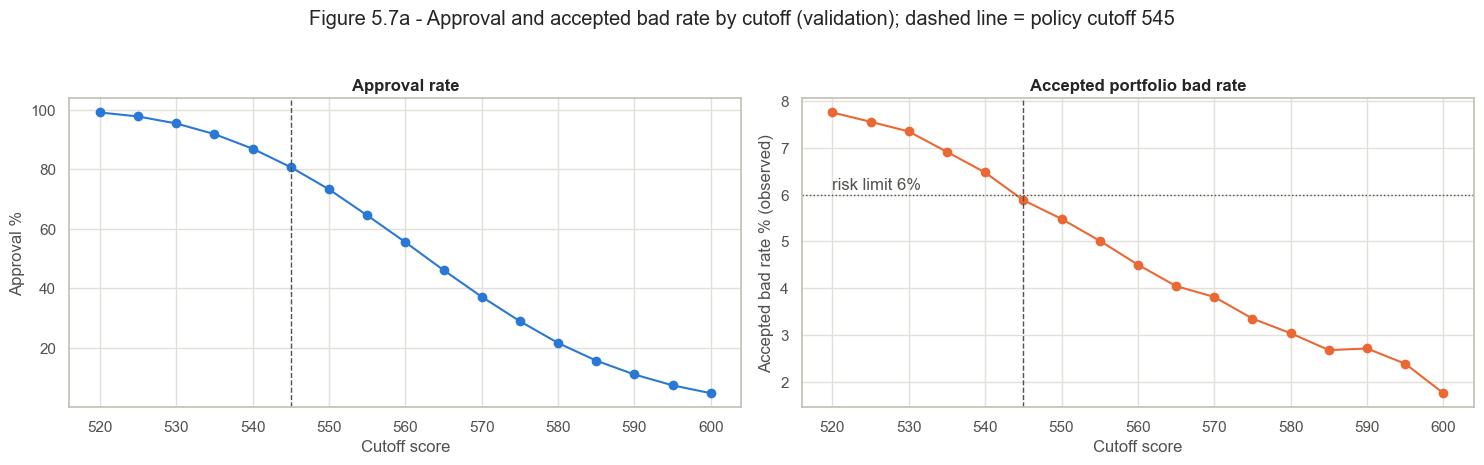

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(valid_cutoffs.index, valid_cutoffs['Approval %'], marker='o', color=GOOD_COLOUR)
axes[0].set_ylabel('Approval %'); axes[0].set_title('Approval rate')
axes[1].plot(valid_cutoffs.index, valid_cutoffs['Accepted bad rate % (observed)'], marker='o', color=BAD_COLOUR)
axes[1].axhline(RISK_LIMIT * 100, color='#52514e', linestyle=':', linewidth=1)
axes[1].text(cutoff_grid[0], RISK_LIMIT * 100 + 0.1, f'risk limit {RISK_LIMIT:.0%}', color='#52514e')
axes[1].set_ylabel('Accepted bad rate % (observed)'); axes[1].set_title('Accepted portfolio bad rate')
for ax in axes:
    ax.axvline(POLICY_CUTOFF, color='#52514e', linestyle='--', linewidth=1)
    ax.set_xlabel('Cutoff score')
plt.suptitle(f'Figure 5.7a - Approval and accepted bad rate by cutoff (validation); dashed line = policy cutoff {POLICY_CUTOFF}', y=1.03)
plt.tight_layout()
plt.show()

## 5.8 Calculate Revenue Default Losses and Profitability

**Business assumptions.** All money is in the dataset's (unstated) currency units. The data does not say whether `AMT_ANNUITY` and `AMT_INCOME_TOTAL` are monthly or annual, so the actual loan cash flows cannot be recovered. Instead, a **hypothetical standard loan** is priced:

| Assumption | Value | Basis |
|---|---|---|
| Applicants per period | 10,000 | Lecture example scale (Module 11.4) |
| Take-up of approved offers | 100% (sensitivity 60-80%) | No take-up data |
| Standard principal | 500,000 | Close to the median `AMT_CREDIT` (hypothetical) |
| Term and repayment | 36 equal monthly instalments | Hypothetical; the data's term is unknown |
| Funding cost | 4% a year on the outstanding balance | Assumption |
| Operating cost | 1.5% a year on the outstanding balance | Assumption |
| Payment difficulty → loss event | 50% of `TARGET = 1` cases become losses | `TARGET` is early delinquency, not a confirmed loss |
| Loss timing and severity | At mid-term; loss = 75% of the outstanding balance | Unsecured loan, high LGD |
| Target margin | 1% of principal a year | Assumption |
| Rate cap | 36% a year | Assumption (common consumer-credit ceiling) |

**Class comparison first (Module 11.4).** The class formula is applied first:
- revenue = funded loans × revenue per loan;
- expected loss = funded loans × loss-event probability × loss per event;
- net = revenue − expected loss.

Revenue per loan is the interest on the standard loan at a flat illustrative 15% a year. Loss per event is the principal lost at mid-term. As in the lecture, only interest revenue and credit losses are included (no funding or operating costs). The formula also counts revenue on loans that go bad, so it overstates net contribution.

In [94]:
from scipy.optimize import brentq

ASSUME = {'applicants': 10000, 'take_up': 1.0, 'principal': 500000, 'term_months': 36, 'funding_rate': 0.04, 'opex_rate': 0.015,
          'event_to_loss': 0.5, 'lgd': 0.75, 'margin_rate': 0.01, 'rate_cap': 0.36, 'flat_rate': 0.15}

def schedule(principal, annual_rate, months):
    # equal-instalment amortisation: opening balance and interest for each month
    r = annual_rate / 12
    payment = principal / months if r == 0 else principal * r / (1 - (1 + r) ** -months)
    balances, interest, balance = [], [], principal
    for _ in range(months):
        balances.append(balance); interest.append(balance * r)
        balance = balance * (1 + r) - payment
    return np.array(balances), np.array(interest)

def loan_outcomes(rate, a):
    # net contribution of one loan if it performs, and if it becomes a loss event at mid-term
    balances, interest = schedule(a['principal'], rate, a['term_months'])
    carry = (a['funding_rate'] + a['opex_rate']) / 12
    k = a['term_months'] // 2
    good = interest.sum() - carry * balances.sum()
    loss = interest[:k].sum() - carry * balances[:k].sum() - a['lgd'] * balances[k]
    return good, loss

# class comparison: flat-rate interest revenue vs principal losses
flat_balances, flat_interest = schedule(ASSUME['principal'], ASSUME['flat_rate'], ASSUME['term_months'])
revenue_per_loan = flat_interest.sum()
loss_per_event = ASSUME['lgd'] * flat_balances[ASSUME['term_months'] // 2]
print(f'Revenue per loan (interest at {ASSUME["flat_rate"]:.0%} over {ASSUME["term_months"]} months): {revenue_per_loan:,.0f}')
print(f'Loss per loss event (75% of the mid-term balance): {loss_per_event:,.0f}')

scale = ASSUME['applicants'] / len(validation)
rows = []
for label, c in [('Approve all', -np.inf)] + [(int(c), c) for c in cutoff_grid]:
    approve = (final_valid_scores['score'] >= c).values
    funded = approve.sum() * scale * ASSUME['take_up']
    loss_prob = y_valid.values[approve].mean() * ASSUME['event_to_loss']
    revenue, losses = funded * revenue_per_loan, funded * loss_prob * loss_per_event
    rows.append({'Cutoff': label, 'Approval %': approve.mean() * 100, 'Funded loans': funded, 'Loss-event probability %': loss_prob * 100,
                 'Revenue': revenue, 'Expected losses': losses, 'Net contribution': revenue - losses})
class_comparison = pd.DataFrame(rows).set_index('Cutoff')
print('Table 5.8a - Class business comparison on validation, scaled to 10,000 applicants')
display(class_comparison.style.format({'Approval %': '{:.1f}', 'Funded loans': '{:,.0f}', 'Loss-event probability %': '{:.2f}',
                                       'Revenue': '{:,.0f}', 'Expected losses': '{:,.0f}', 'Net contribution': '{:,.0f}'}))

Revenue per loan (interest at 15% over 36 months): 123,976
Loss per loss event (75% of the mid-term balance): 208,376
Table 5.8a - Class business comparison on validation, scaled to 10,000 applicants


,Approval %,Funded loans,Loss-event probability %,Revenue,Expected losses,Net contribution
Cutoff,,,,,,
Approve all,100.0,"10,000",3.96,"1,239,759,131","82,537,280","1,157,221,850"
520,99.1,"9,915",3.88,"1,229,211,003","80,125,375","1,149,085,628"
525,97.8,"9,782",3.78,"1,212,736,541","77,024,354","1,135,712,188"
530,95.5,"9,546",3.68,"1,183,477,600","73,108,923","1,110,368,677"
535,91.9,"9,189",3.46,"1,139,235,098","66,186,441","1,073,048,657"
540,87.0,"8,699",3.24,"1,078,443,590","58,668,814","1,019,774,776"
545,80.8,"8,077",2.94,"1,001,401,256","49,491,045","951,910,211"
550,73.3,"7,333",2.74,"909,151,726","41,879,447","867,272,279"
555,64.6,"6,459",2.51,"800,725,916","33,735,351","766,990,564"


Under the class formula, net contribution rises steadily as the cutoff falls, and approving everyone gives the highest figure. Two features of the formula drive this: interest on a 15% loan is large relative to the expected loss when only half of payment difficulties become losses, and the formula ignores funding and operating costs. The fuller calculation below includes both.

**Risk-based pricing.** The interest rate should match the risk of the loan (Module 7.1). Approved applicants are grouped into score bands. Each band's loss-event probability is its mean predicted p_bad (calibrated in 5.4) × 50%. The band's rate is the lowest annual rate at which the expected contribution of a standard loan covers funding cost, operating cost and expected credit loss, plus the target margin:

$$(1 - q)\cdot G(r) + q \cdot L(r) = margin \times principal \times term$$

Here *G* is the net contribution of a loan that performs and *L* that of a loan that becomes a loss at mid-term. The rate is rounded up to the next 0.25%. These rates are **illustrative**: there is no data on how applicants respond to price, so they are break-even rates, not optimal prices.

In [95]:
SCORE_BANDS = [-np.inf, 530, 540, 550, 560, 570, 580, 590, np.inf]
band_labels = ['< 530', '530-539', '540-549', '550-559', '560-569', '570-579', '580-589', '590+']

def band_of(scores):
    return pd.cut(scores, bins=SCORE_BANDS, labels=band_labels, right=False)

def break_even_rate(q, a):
    target = a['margin_rate'] * a['principal'] * a['term_months'] / 12
    gap = lambda r: (1 - q) * loan_outcomes(r, a)[0] + q * loan_outcomes(r, a)[1] - target
    return brentq(gap, 0.0, 2.0) if gap(2.0) > 0 else np.nan

valid_bands = band_of(final_valid_scores['score'])
pricing = pd.DataFrame({'Applicants': valid_bands.value_counts().reindex(band_labels).rename_axis('Score band'),
                        'Mean predicted p_bad %': final_valid_scores.groupby(valid_bands, observed=False)['p_bad'].mean().reindex(band_labels) * 100,
                        'Observed bad rate %': y_valid.groupby(valid_bands, observed=False).mean().reindex(band_labels) * 100})
pricing['Loss-event probability %'] = pricing['Mean predicted p_bad %'] * ASSUME['event_to_loss']
pricing['Break-even rate %'] = [break_even_rate(q / 100, ASSUME) * 100 for q in pricing['Loss-event probability %']]
pricing['Offered rate %'] = np.ceil(pricing['Break-even rate %'] * 4) / 4
pricing['Within 36% cap'] = np.where(pricing['Offered rate %'] <= ASSUME['rate_cap'] * 100, 'yes', 'no')
pricing['Above policy cutoff'] = ['yes' if lo >= POLICY_CUTOFF else ('partly' if hi > POLICY_CUTOFF else 'no')
                                  for lo, hi in zip(SCORE_BANDS[:-1], SCORE_BANDS[1:])]
print('Table 5.8b - Illustrative risk-based rates by score band (validation risk estimates)')
display(pricing.style.format({'Applicants': '{:,.0f}', 'Mean predicted p_bad %': '{:.2f}', 'Observed bad rate %': '{:.2f}',
                              'Loss-event probability %': '{:.2f}', 'Break-even rate %': '{:.2f}', 'Offered rate %': '{:.2f}'}))
offered_rate = dict(zip(band_labels, np.fmin(pricing['Offered rate %'].values / 100, ASSUME['rate_cap'])))   # capped; unpriceable bands get the cap

Table 5.8b - Illustrative risk-based rates by score band (validation risk estimates)


,Applicants,Mean predicted p_bad %,Observed bad rate %,Loss-event probability %,Break-even rate %,Offered rate %,Within 36% cap,Above policy cutoff
< 530,"1,510",21.86,19.93,10.93,10.22,10.25,yes,no
530-539,"2,818",15.81,16.36,7.91,9.41,9.50,yes,no
540-549,"4,542",11.78,11.80,5.89,8.88,9.00,yes,partly
550-559,"5,912",8.69,8.54,4.34,8.48,8.50,yes,yes
560-569,"6,100",6.34,5.90,3.17,8.18,8.25,yes,yes
570-579,"5,169",4.59,4.89,2.30,7.96,8.00,yes,yes
580-589,"3,522",3.31,3.38,1.66,7.80,8.00,yes,yes
590+,"3,689",1.99,2.71,0.99,7.63,7.75,yes,yes


Break-even rates run from 7.75% for the safest band to 10.25% for the riskiest, all well inside the 36% cap. The observed band bad rates on validation track the predicted ones closely. Even the bands below the cutoff could be priced profitably on paper, at 9.5-10.25%.

**Policy versus approve-all.** Both are evaluated on the same validation applicants, with the same band rates, cost assumptions and take-up, scaled to 10,000 applicants. Each applicant's realised outcome is used: a good contributes *G* at its band rate, and a bad becomes a loss event with probability 50% (otherwise it is treated as performing).

In [96]:
def portfolio(scores, y, approve, a, rates=None):
    # expected funded count, revenue, losses and net contribution for an approval decision
    rates = rates or offered_rate
    bands = band_of(scores['score']).astype(str).values
    funded_scale = a['applicants'] / len(scores) * a['take_up']
    revenue = losses = net = 0.0
    for band in np.unique(bands[approve]):
        in_band = approve & (bands == band)
        r = rates[band]
        balances, interest = schedule(a['principal'], r, a['term_months'])
        k = a['term_months'] // 2
        g, l = loan_outcomes(r, a)
        n_good, n_bad = (y[in_band] == 0).sum(), (y[in_band] == 1).sum()
        n_loss = n_bad * a['event_to_loss']
        n_perform = n_good + n_bad - n_loss
        revenue += (n_perform * interest.sum() + n_loss * interest[:k].sum()) * funded_scale
        losses += n_loss * a['lgd'] * balances[k] * funded_scale
        net += (n_perform * g + n_loss * l) * funded_scale
    return {'Approval %': approve.mean() * 100, 'Funded loans': approve.sum() * funded_scale,
            'Accepted bad rate % (observed)': y[approve].mean() * 100,
            'Mean predicted p_bad % (approved)': scores.loc[approve, 'p_bad'].mean() * 100,
            'Interest revenue': revenue, 'Credit losses': losses, 'Net contribution (after funding and operating cost)': net}

y_valid_arr = y_valid.values
policy_approve = (final_valid_scores['score'] >= POLICY_CUTOFF).values
policy_vs_all = pd.DataFrame({f'Scorecard policy (score >= {POLICY_CUTOFF})': portfolio(final_valid_scores, y_valid_arr, policy_approve, ASSUME),
                              'Approve all': portfolio(final_valid_scores, y_valid_arr, np.ones(len(y_valid_arr), dtype=bool), ASSUME)}).T
print('Table 5.8c - Policy vs approve-all on validation, scaled to 10,000 applicants')
display(policy_vs_all.style.format('{:,.2f}', subset=['Approval %', 'Accepted bad rate % (observed)', 'Mean predicted p_bad % (approved)'])
        .format('{:,.0f}', subset=['Funded loans', 'Interest revenue', 'Credit losses', 'Net contribution (after funding and operating cost)']))

Table 5.8c - Policy vs approve-all on validation, scaled to 10,000 applicants


,Approval %,Funded loans,Accepted bad rate % (observed),Mean predicted p_bad % (approved),Interest revenue,Credit losses,Net contribution (after funding and operating cost)
Scorecard policy (score >= 545),80.77,"8,077",5.88,5.95,"528,252,374","47,309,938","127,664,879"
Approve all,100.00,"10,000",7.92,7.93,"672,483,689","79,168,713","156,667,444"


The same risk-based economics across the whole cutoff grid show how contribution and portfolio risk trade off as the cutoff moves:

In [97]:
grid_rows = {}
for c in ['Approve all'] + list(cutoff_grid):
    approve = np.ones(len(y_valid_arr), dtype=bool) if c == 'Approve all' else (final_valid_scores['score'] >= c).values
    res = portfolio(final_valid_scores, y_valid_arr, approve, ASSUME)
    grid_rows[c] = {'Approval %': res['Approval %'], 'Accepted bad rate % (observed)': res['Accepted bad rate % (observed)'],
                    'Net contribution': res['Net contribution (after funding and operating cost)']}
risk_based_grid = pd.DataFrame(grid_rows).T.rename_axis('Cutoff')
print('Table 5.8d - Net contribution under risk-based pricing by cutoff (validation, 10,000 applicants)')
display(risk_based_grid.style.format({'Approval %': '{:.1f}', 'Accepted bad rate % (observed)': '{:.2f}', 'Net contribution': '{:,.0f}'}))

Table 5.8d - Net contribution under risk-based pricing by cutoff (validation, 10,000 applicants)


,Approval %,Accepted bad rate % (observed),Net contribution
Cutoff,,,
Approve all,100.0,7.92,"156,667,444"
520,99.1,7.76,"155,853,905"
525,97.8,7.56,"153,905,123"
530,95.5,7.35,"148,822,888"
535,91.9,6.91,"144,272,337"
540,87.0,6.47,"136,015,126"
545,80.8,5.88,"127,664,879"
550,73.3,5.48,"114,300,600"
555,64.6,5.01,"101,289,107"


Because each band is priced to cover its own expected loss plus a margin, every band contributes positively under the base assumptions. Net contribution therefore keeps rising as the cutoff falls. On validation, approving everyone earns about 157m against 128m for the 545 policy. In exchange, the policy lowers the accepted bad rate from 7.9% to 5.9%.

In [98]:
# deterministic sensitivities: rates stay as set; one assumption changes at a time
scenarios = [('Base case', {})] + \
    [(f'LGD {v:.0%}', {'lgd': v}) for v in [0.5, 0.9]] + \
    [(f'Loss events = {v:.0%} of payment difficulties', {'event_to_loss': v}) for v in [0.3, 0.8, 1.0]] + \
    [(f'Funding cost {v:.0%}', {'funding_rate': v}) for v in [0.03, 0.06]] + \
    [(f'Take-up {v:.0%}', {'take_up': v}) for v in [0.6, 0.8]]
all_approve = np.ones(len(y_valid_arr), dtype=bool)
sensitivity = pd.DataFrame({name: {'Scorecard policy': portfolio(final_valid_scores, y_valid_arr, policy_approve, {**ASSUME, **chg})['Net contribution (after funding and operating cost)'],
                                   'Approve all': portfolio(final_valid_scores, y_valid_arr, all_approve, {**ASSUME, **chg})['Net contribution (after funding and operating cost)']}
                            for name, chg in scenarios}).T
sensitivity['Policy advantage'] = sensitivity['Scorecard policy'] - sensitivity['Approve all']
print('Table 5.8e - Net contribution sensitivity (validation, 10,000 applicants)')
display(sensitivity.style.format('{:,.0f}'))

Table 5.8e - Net contribution sensitivity (validation, 10,000 applicants)


,Scorecard policy,Approve all,Policy advantage
Base case,"127,664,879","156,667,444","-29,002,566"
LGD 50%,"143,434,858","183,057,016","-39,622,157"
LGD 90%,"118,202,891","140,833,702","-22,630,810"
Loss events = 30% of payment difficulties,"147,170,545","189,477,410","-42,306,865"
Loss events = 80% of payment difficulties,"98,406,380","107,452,497","-9,046,117"
Loss events = 100% of payment difficulties,"78,900,714","74,642,532","4,258,182"
Funding cost 3%,"191,897,162","236,057,905","-44,160,743"
Funding cost 6%,"-799,687","-2,113,476","1,313,789"
Take-up 60%,"76,598,927","94,000,467","-17,401,539"
Take-up 80%,"102,131,903","125,333,956","-23,202,052"


The ranking depends on how many payment difficulties turn into actual losses:
- When 80% become losses, the gap narrows to about 9m.
- When all of them become losses, the scorecard policy earns more than approve-all.
- When funding costs rise to 6% with rates held at their original level, both portfolios lose money, but the policy loses less.

**Recommended policy: approve applicants scoring 545 or more, priced by score band (7.75%-9.00%).** The cutoff follows the stated risk appetite of an accepted bad rate of at most 6%. It gives up about 18% of the base-case contribution, and in return cuts the accepted bad rate by about a quarter. The extra contribution from lending below 545 rests on the most uncertain assumptions:
- the 50% conversion of payment difficulty into loss;
- the ability to charge 9.5-10.25% to applicants with 16-20% payment-difficulty rates without losing the better ones or attracting worse ones (no price-response data exists).

If the bank verifies a low loss conversion and accepts higher risk, a cutoff around 530-540 would add contribution. The figures are an illustrative net contribution in dataset currency units. They are not a fully costed economic profit: capital, tax and acquisition costs are excluded.

## 5.9 Evaluate the Frozen Model and Policy on Held Out Test Data

The following are now frozen: the bins and WOE (3.8 and 5.6), the coefficients (5.6), the scaling (4.5-4.6), the cutoff (5.7) and the band rates (5.8). The test set is scored **once**. The summary sheet asks for training and test F1, recall and specificity. These are reported at the policy cutoff (approve = predicted good), with good payers as the positive class. "Training" means dev_train, the data the final model was fitted on.

In [99]:
final_test_scores = final_scores(test)
y_test = test[TARGET]

final_rows = {}
for name, y, scores in [('Training (dev_train)', y_train, final_train_scores), ('Test (held out)', y_test, final_test_scores)]:
    approve = (scores['score'] >= POLICY_CUTOFF).values
    m = classification_measures(y, approve)
    d, _, _ = discrimination(y, scores['p_bad'].values)
    final_rows[name] = {'F1 (good)': m['F1 (good)'], 'Recall (good)': m['Recall (good)'], 'Specificity (bad rejection)': m['Specificity (bad rejection)'],
                        'Accuracy': m['Accuracy'], 'Approval rate': m['Approval rate'], 'AUC': d['AUC'], 'Gini': d['Gini'], 'KS': d['KS']}
final_perf = pd.DataFrame(final_rows).T
print(f'Table 5.9a - Final scorecard performance at the policy cutoff (approve if score >= {POLICY_CUTOFF})')
display(final_perf.style.format('{:.4f}'))
print(f'Table 5.9b - Confusion matrix, test set, cutoff {POLICY_CUTOFF}')
display(confusion_frame(y_test, (final_test_scores['score'] >= POLICY_CUTOFF).values).style.format('{:,}'))

Table 5.9a - Final scorecard performance at the policy cutoff (approve if score >= 545)


,F1 (good),Recall (good),Specificity (bad rejection),Accuracy,Approval rate,AUC,Gini,KS
Training (dev_train),0.8797,0.8264,0.3910,0.7919,0.8092,0.6862,0.3723,0.2757
Test (held out),0.8795,0.8256,0.3956,0.7916,0.8081,0.6813,0.3626,0.2714


Table 5.9b - Confusion matrix, test set, cutoff 545


,Predicted good (approve),Predicted bad (reject)
Actual good payer,"50,575","10,680"
Actual defaulter,"3,185","2,085"


On the held-out test set, the frozen scorecard performs almost exactly as on the data it was fitted on:
- F1 (good) is 0.880 on training and 0.879 on test.
- Recall (good) is 0.826 on both.
- Specificity is 0.391 on training and 0.396 on test.
- AUC is 0.686 on training and 0.681 on test.

The scorecard generalises. At this cutoff it approves 83% of goods and rejects about 40% of bads. That is the expected outcome for a scorecard with AUC near 0.68 at an 81% approval rate.

In [100]:
y_test_arr = y_test.values
test_policy = (final_test_scores['score'] >= POLICY_CUTOFF).values
test_portfolio = pd.DataFrame({f'Scorecard policy (score >= {POLICY_CUTOFF})': portfolio(final_test_scores, y_test_arr, test_policy, ASSUME),
                               'Approve all': portfolio(final_test_scores, y_test_arr, np.ones(len(y_test_arr), dtype=bool), ASSUME)}).T
print('Table 5.9c - Frozen policy vs approve-all on the test set, scaled to 10,000 applicants')
display(test_portfolio.style.format('{:,.2f}', subset=['Approval %', 'Accepted bad rate % (observed)', 'Mean predicted p_bad % (approved)'])
        .format('{:,.0f}', subset=['Funded loans', 'Interest revenue', 'Credit losses', 'Net contribution (after funding and operating cost)']))

Table 5.9c - Frozen policy vs approve-all on the test set, scaled to 10,000 applicants


,Approval %,Funded loans,Accepted bad rate % (observed),Mean predicted p_bad % (approved),Interest revenue,Credit losses,Net contribution (after funding and operating cost)
Scorecard policy (score >= 545),80.81,"8,081",5.92,5.94,"528,381,064","47,686,893","127,274,042"
Approve all,100.00,"10,000",7.92,7.95,"672,622,593","79,181,347","156,790,837"


On test, the policy approves 80.8% of applicants. The observed accepted bad rate is 5.92%, against 5.94% predicted, so the risk estimates hold on unseen data. The contribution pattern matches validation: the policy earns about 127m against 157m for approve-all, in exchange for a bad rate about two percentage points lower.

**Decisions for the synthetic profiles from 4.8**, scored with the final scorecard. Rejected profiles receive no offer.

In [101]:
profile_decisions = final_scores(profiles).rename(columns={'score': 'Score', 'p_bad': 'Model p_bad'})
profile_decisions['Rounded points'] = points_table(profiles, final_scorecard, final_vars, final_pipe['specs']).sum(axis=1)
profile_decisions['Cutoff'] = POLICY_CUTOFF
profile_decisions['Decision'] = np.where(profile_decisions['Score'] >= POLICY_CUTOFF, 'Approve', 'Reject')
profile_decisions['Score band'] = band_of(profile_decisions['Score']).astype(str)
profile_decisions['Offered rate'] = [f'{offered_rate[b]:.2%}' if d == 'Approve' else 'no offer'
                                     for b, d in zip(profile_decisions['Score band'], profile_decisions['Decision'])]
print('Table 5.9d - Synthetic profiles: points, score, decision and offered rate')
display(profile_decisions.style.format({'Score': '{:.1f}', 'Model p_bad': '{:.2%}'}))

Table 5.9d - Synthetic profiles: points, score, decision and offered rate


,Score,Model p_bad,Rounded points,Cutoff,Decision,Score band,Offered rate
Profile,,,,,,,
A: established owner,653.2,0.32%,653,545,Approve,590+,7.75%
B: mid-career owner,553.5,9.10%,553,545,Approve,550-559,8.50%
C: recent borrower,500.7,38.46%,501,545,Reject,< 530,no offer
"D: retired owner, no bureau record",559.6,7.50%,559,545,Approve,550-559,8.50%
E: extreme values and unseen occupation,580.5,3.78%,579,545,Approve,580-589,8.00%


The synthetic profiles confirm that the policy behaves sensibly:
- **A**, **B** and **E** are approved.
- **C** (score 501) is rejected and receives no offer.
- **D**, the retired owner without bureau history, scores about 560 and is approved at 8.50%: the scorecard does not automatically exclude thin-file applicants.

Rates rise as scores fall, from 7.75% for **A** to 8.50% for **B** and **D**.

**Fairness audit.** Gender, income type and family status are not scorecard inputs. Approval rates and accepted bad rates by group show whether the policy nevertheless treats groups differently. Group differences can reflect genuine differences in risk characteristics. This is a descriptive check, not proof of fairness or of legal compliance.

In [102]:
audit = test.assign(approved=test_policy, age_band=pd.cut(test['age_years'], [25, 35, 45, 55, 65], include_lowest=True).astype(str))
audit_rows = []
for field in ['CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'age_band']:
    for group, g in audit.groupby(field):
        audit_rows.append({'Field': field, 'Group': group, 'Applicants': len(g), 'Approval %': g['approved'].mean() * 100,
                           'Bad rate % (all)': g[TARGET].mean() * 100,
                           'Bad rate % (approved)': g.loc[g['approved'], TARGET].mean() * 100 if g['approved'].any() else np.nan})
fairness = pd.DataFrame(audit_rows).set_index(['Field', 'Group'])
print('Table 5.9e - Approval and bad rates by group, test set (groups under 100 applicants are too small to interpret)')
display(fairness.style.format({'Applicants': '{:,}', 'Approval %': '{:.1f}', 'Bad rate % (all)': '{:.2f}', 'Bad rate % (approved)': '{:.2f}'}))

Table 5.9e - Approval and bad rates by group, test set (groups under 100 applicants are too small to interpret)


- **Gender.** Gender is not a scorecard input, yet women are approved more often than men (85% against 72%). This follows the difference in observed risk (bad rates of 6.9% and 10.0%), carried by correlated characteristics such as occupation and organisation. Approved men remain riskier than approved women, so the policy does not over-penalise men relative to their observed risk. It is still a disparity to monitor.
- **Income type.** Pensioners are approved 98% of the time, against 73% for working applicants. The employment and organisation bins that capture "not employed" favour them. Excluding income type removes it as a direct input, but not its influence.
- **Age.** Age is a direct input, and approval rises from 62% for ages 25-35 to 96% for 55-65.

Age-related decisions need checking against the applicable lending rules before use. Groups with fewer than 100 applicants cannot be interpreted. Dropping gender from the model does not by itself establish fair or lawful lending.

In [103]:
summary_ready = pd.Series({
    'Selected rows / bads / bad rate': f"{len(model_data):,} / {model_data[TARGET].sum():,} / {model_data[TARGET].mean():.2%}",
    'Characteristics in final scorecard': len(final_vars),
    'Train F1 / Recall / Specificity': ' / '.join(f"{final_perf.loc['Training (dev_train)', k]:.3f}" for k in ['F1 (good)', 'Recall (good)', 'Specificity (bad rejection)']),
    'Test F1 / Recall / Specificity': ' / '.join(f"{final_perf.loc['Test (held out)', k]:.3f}" for k in ['F1 (good)', 'Recall (good)', 'Specificity (bad rejection)']),
    'Target score / target odds / PDO': f'{TARGET_SCORE} / {TARGET_ODDS}:1 good:bad / {PDO}',
    'Cutoff score': POLICY_CUTOFF,
    'Expected approval rate at cutoff (validation)': f"{valid_cutoffs.loc[POLICY_CUTOFF, 'Approval %']:.1f}%",
    'Good:bad odds at cutoff (boundary)': f"{valid_cutoffs.loc[POLICY_CUTOFF, 'Boundary good:bad odds']:.1f}:1 (PD {valid_cutoffs.loc[POLICY_CUTOFF, 'Boundary PD %']:.2f}%)",
    'Expected default rate at cutoff (validation, observed accepted)': f"{valid_cutoffs.loc[POLICY_CUTOFF, 'Accepted bad rate % (observed)']:.2f}%",
})
print('Table 5.9f - Summary-ready results')
display(summary_ready.to_frame('Value'))

Table 5.9f - Summary-ready results


,Value
Selected rows / bads / bad rate,"199,573 / 15,810 / 7.92%"
Characteristics in final scorecard,12
Train F1 / Recall / Specificity,0.880 / 0.826 / 0.391
Test F1 / Recall / Specificity,0.879 / 0.826 / 0.396
Target score / target odds / PDO,600 / 50:1 good:bad / 20
Cutoff score,545
Expected approval rate at cutoff (validation),80.8%
Good:bad odds at cutoff (boundary),7.4:1 (PD 11.86%)
"Expected default rate at cutoff (validation, observed accepted)",5.88%


## 5.10 Monitor Population Shifts and Stability

The Population Stability Index compares the distribution of a recent population with the development sample (Module 11.4):

$$PSI = \sum_k (current\ share_k - reference\ share_k) \times \ln\frac{current\ share_k}{reference\ share_k}$$

Shares use the frozen development bins: score deciles from dev_train, and the scorecard attributes. To avoid taking the log of zero, any share is floored at 0.0001. A common rule of thumb (an industry convention, not from the course) reads PSI < 0.1 as stable, 0.1-0.25 as a moderate shift and > 0.25 as a significant shift.

The data has no dates, so dev_train vs test is only a comparison of two random samples from the same period. It illustrates the calculation but is not evidence of future stability.

In [104]:
def psi(reference, current, floor=1e-4):
    ref = reference.value_counts(normalize=True)
    cur = current.value_counts(normalize=True).reindex(ref.index).fillna(0)
    ref, cur = ref.clip(lower=floor), cur.clip(lower=floor)
    return float(((cur - ref) * np.log(cur / ref)).sum())

decile_edges = np.quantile(final_train_scores['score'], np.linspace(0, 1, 11))[1:-1]
to_decile = lambda s: pd.cut(s, bins=[-np.inf, *decile_edges, np.inf], labels=False)
stability = {'Total score (deciles)': psi(to_decile(final_train_scores['score']), to_decile(final_test_scores['score']))}
for var in final_vars:
    stability[var] = psi(assign_bins(dev_train, var, final_pipe['specs'][var]), assign_bins(test, var, final_pipe['specs'][var]))
psi_table = pd.Series(stability, name='PSI (dev_train vs test)').to_frame()
print('Table 5.10a - Population stability, dev_train vs test (illustration)')
display(psi_table.style.format('{:.5f}'))

Table 5.10a - Population stability, dev_train vs test (illustration)


,PSI (dev_train vs test)
Total score (deciles),0.00034
EXT_SOURCE_1,0.00007
employment_years,0.00002
AMT_GOODS_PRICE,0.00012
BUR_debt_to_credit,0.00025
BUR_days_since_recent_credit,0.00027
OCCUPATION_TYPE,0.00001
age_years,0.00006
ORGANIZATION_TYPE,0.00004
NAME_EDUCATION_TYPE,0.00001


Every PSI is far below 0.1. This is expected, because dev_train and test are random samples from the same period, and it says nothing about future stability.

**Monitoring.** Once the scorecard is in use, the following should be tracked monthly or quarterly against the frozen dev_train bins:
- the score PSI and each characteristic's PSI;
- the approval rate and the accepted bad rate as performance matures;
- calibration (predicted vs observed bad rate by score band).

A PSI above 0.1, or a calibration gap of more than about one percentage point in the main bands, should trigger a review. A PSI above 0.25 should trigger redevelopment.

**Recommendation and limitations.** The 12-characteristic scorecard ranks risk consistently on unseen data (test AUC 0.68), and its probabilities are well calibrated. Adopting it at a cutoff of 545 with band pricing from 7.75% to 9.00% approves about 81% of homeowner applicants at a bad rate of about 5.9%.

The main limitations are:
- the population is a homeowner proxy, not confirmed renovation borrowers, and includes revolving loans;
- the target is early payment difficulty, not loss;
- only approved loans have outcomes (reject-inference bias);
- there is no application date, so no out-of-time test was possible;
- the currency and periods of the amounts are unknown, so the pricing uses a hypothetical standard loan;
- discrimination is only in the poor-to-fair range.

The scorecard should be re-validated on a dated, out-of-time sample with confirmed loss outcomes before it is used for real lending decisions.